In [ ]:
!pip install -q kagglehub

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from kagglehub import KaggleDatasetAdapter

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
file_path = "PS_20174392719_1491204439457_log.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "ealaxi/paysim1",
    file_path
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Using Colab cache for faster access to the 'paysim1' dataset.
Dataset loaded successfully!
Shape: (6362620, 11)


In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (6362620, 11)

Column Names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data Types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [ ]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df) * 100).round(4)
})

missing_table

,Missing Values,Percentage
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [ ]:
transaction_counts = df["type"].value_counts()

print(transaction_counts)

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


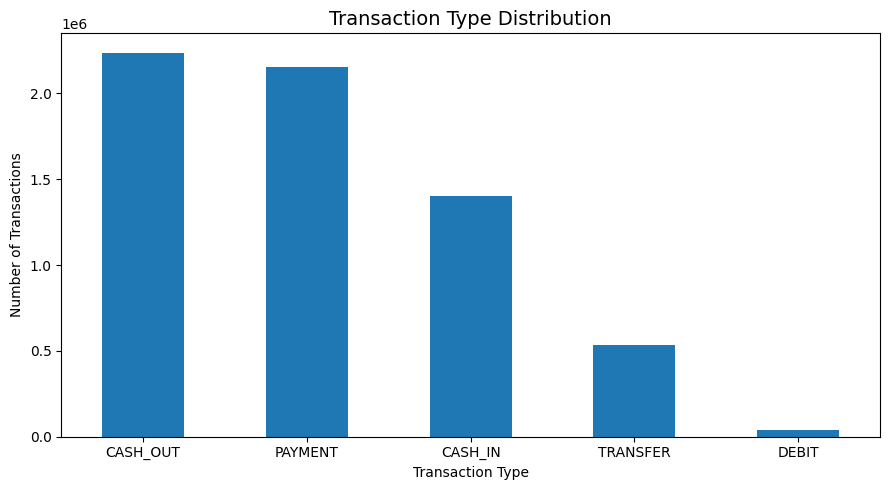

In [ ]:
plt.figure(figsize=(9, 5))

transaction_counts.plot(kind="bar")

plt.title("Transaction Type Distribution", fontsize=14)
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
fraud_counts = df["isFraud"].value_counts()

print("Genuine transactions:", fraud_counts.get(0, 0))
print("Fraud transactions:", fraud_counts.get(1, 0))

print("\nPercentage:")
print((fraud_counts / len(df) * 100).round(4))

Genuine transactions: 6354407
Fraud transactions: 8213

Percentage:
isFraud
0    99.8709
1     0.1291
Name: count, dtype: float64


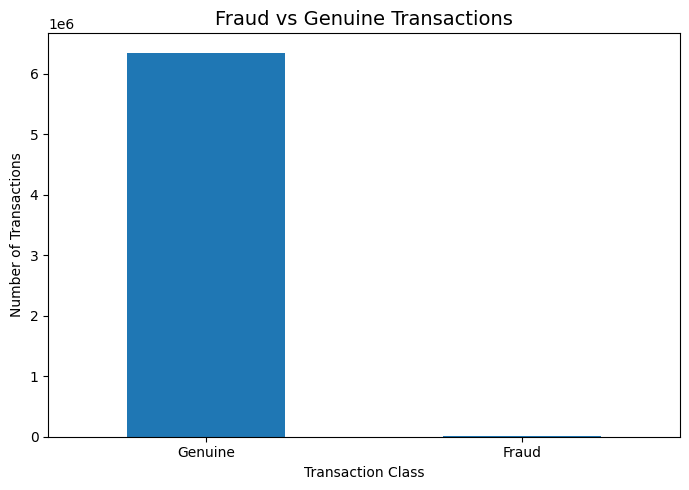

In [ ]:
plt.figure(figsize=(7, 5))

fraud_counts.rename({
    0: "Genuine",
    1: "Fraud"
}).plot(kind="bar")

plt.title("Fraud vs Genuine Transactions", fontsize=14)
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
fraud_type_table = pd.crosstab(
    df["type"],
    df["isFraud"]
)

fraud_type_table

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [ ]:
fraud_rate = (
    df.groupby("type")["isFraud"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

fraud_rate

,isFraud
type,
TRANSFER,0.768799
CASH_OUT,0.183955
CASH_IN,0.000000
DEBIT,0.000000
PAYMENT,0.000000


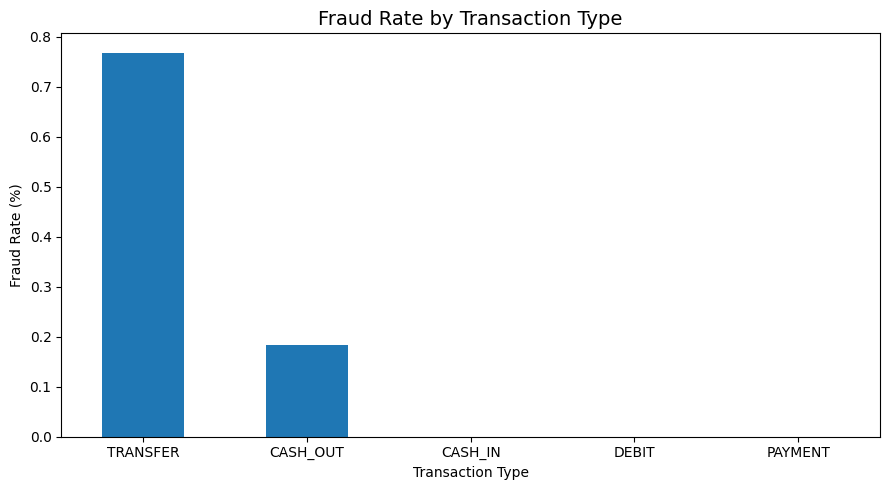

In [ ]:
plt.figure(figsize=(9, 5))

fraud_rate.plot(kind="bar")

plt.title("Fraud Rate by Transaction Type", fontsize=14)
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
data = df.copy()

print("Working dataset created.")
print("Shape:", data.shape)

Working dataset created.
Shape: (6362620, 11)


In [ ]:
data["origBalanceChange"] = (
    data["oldbalanceOrg"] -
    data["newbalanceOrig"]
)

data["destBalanceChange"] = (
    data["newbalanceDest"] -
    data["oldbalanceDest"]
)

data["origBalanceError"] = (
    data["amount"] -
    data["origBalanceChange"]
).abs()

data["destBalanceError"] = (
    data["amount"] -
    data["destBalanceChange"]
).abs()

data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,origBalanceChange,destBalanceChange,origBalanceError,destBalanceError
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0,1.455192e-11,9839.64
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0,1.136868e-12,1864.28
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0,0.000000e+00,181.00
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0,0.000000e+00,21363.00
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0,0.000000e+00,11668.14


In [ ]:
data["type_encoded"] = (
    data["type"].astype("category").cat.codes
)

data[
    ["type", "type_encoded"]
].head(10)

,type,type_encoded
0,PAYMENT,3
1,PAYMENT,3
2,TRANSFER,4
3,CASH_OUT,1
4,PAYMENT,3
5,PAYMENT,3
6,PAYMENT,3
7,PAYMENT,3
8,PAYMENT,3
9,DEBIT,2


In [ ]:
print("Minimum amount:", data["amount"].min())
print("Maximum amount:", data["amount"].max())
print("Mean amount:", data["amount"].mean())
print("Median amount:", data["amount"].median())

Minimum amount: 0.0
Maximum amount: 92445516.64
Mean amount: 179861.90354913071
Median amount: 74871.94


In [ ]:
benford_data = data[data["amount"] > 0].copy()

print("Original rows:", len(data))
print("Rows used for Benford analysis:", len(benford_data))

Original rows: 6362620
Rows used for Benford analysis: 6362604


In [ ]:
def get_first_digit(x):
    x = abs(x)

    if x == 0:
        return 0

    while x < 1:
        x *= 10

    return int(str(x)[0])

benford_data["first_digit"] = (
    benford_data["amount"]
    .apply(get_first_digit)
)

benford_data[
    ["amount", "first_digit"]
].head(15)

,amount,first_digit
0,9839.64,9
1,1864.28,1
2,181.00,1
3,181.00,1
4,11668.14,1
5,7817.71,7
6,7107.77,7
7,7861.64,7
8,4024.36,4
9,5337.77,5


In [ ]:
digits = np.arange(1, 10)

benford_expected = np.log10(
    1 + (1 / digits)
)

benford_table = pd.DataFrame({
    "Digit": digits,
    "Expected": benford_expected
})

benford_table

,Digit,Expected
0,1,0.301030
1,2,0.176091
2,3,0.124939
3,4,0.096910
4,5,0.079181
5,6,0.066947
6,7,0.057992
7,8,0.051153
8,9,0.045757


In [ ]:
observed_distribution = (
    benford_data["first_digit"]
    .value_counts(normalize=True)
    .reindex(digits, fill_value=0)
    .sort_index()
)

observed_table = pd.DataFrame({
    "Digit": digits,
    "Observed": observed_distribution.values
})

observed_table

,Digit,Observed
0,1,0.335952
1,2,0.204658
2,3,0.125487
3,4,0.082780
4,5,0.062200
5,6,0.052540
6,7,0.048082
7,8,0.045195
8,9,0.043105


In [ ]:
benford_comparison = benford_table.merge(
    observed_table,
    on="Digit"
)

benford_comparison

,Digit,Expected,Observed
0,1,0.301030,0.335952
1,2,0.176091,0.204658
2,3,0.124939,0.125487
3,4,0.096910,0.082780
4,5,0.079181,0.062200
5,6,0.066947,0.052540
6,7,0.057992,0.048082
7,8,0.051153,0.045195
8,9,0.045757,0.043105


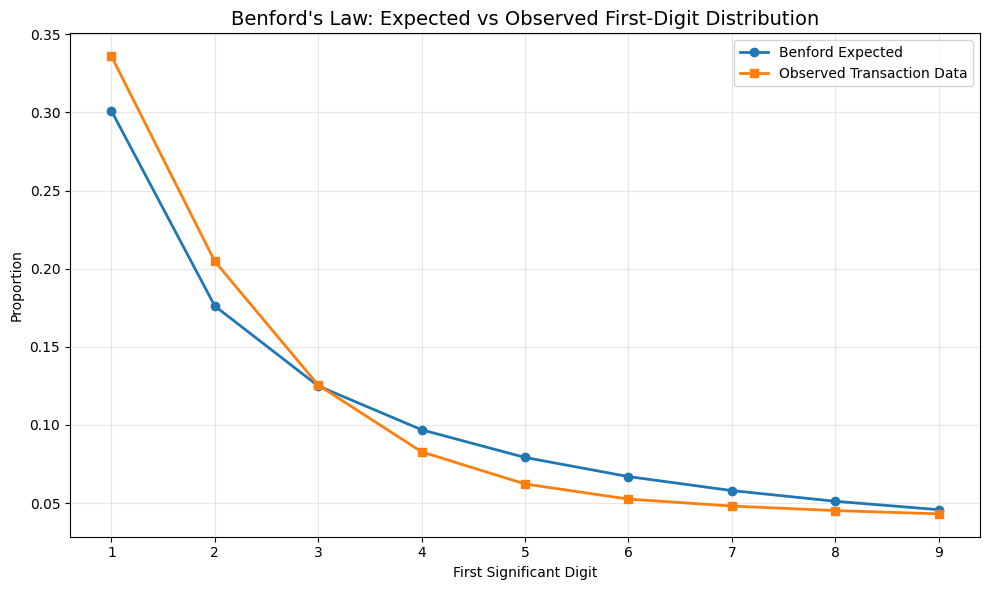

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    benford_comparison["Digit"],
    benford_comparison["Expected"],
    marker="o",
    linewidth=2,
    label="Benford Expected"
)

plt.plot(
    benford_comparison["Digit"],
    benford_comparison["Observed"],
    marker="s",
    linewidth=2,
    label="Observed Transaction Data"
)

plt.title(
    "Benford's Law: Expected vs Observed First-Digit Distribution",
    fontsize=14
)

plt.xlabel("First Significant Digit")
plt.ylabel("Proportion")

plt.xticks(digits)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
benford_comparison["AbsoluteDeviation"] = (
    benford_comparison["Observed"] -
    benford_comparison["Expected"]
).abs()

MAD = (
    benford_comparison["AbsoluteDeviation"]
    .mean()
)

print("Overall Benford MAD:", round(MAD, 6))

Overall Benford MAD: 0.01423


In [ ]:
benford_by_type = {}

for transaction_type in benford_data["type"].unique():

    subset = benford_data[
        benford_data["type"] == transaction_type
    ]

    if len(subset) < 100:
        continue

    observed = (
        subset["first_digit"]
        .value_counts(normalize=True)
        .reindex(digits, fill_value=0)
    )

    mad = np.mean(
        np.abs(
            observed.values -
            benford_expected
        )
    )

    benford_by_type[transaction_type] = mad

benford_by_type

{'PAYMENT': np.float64(0.009527080538070446),
 'TRANSFER': np.float64(0.00542689607360235),
 'CASH_OUT': np.float64(0.022241291494627738),
 'DEBIT': np.float64(0.016359726172359423),
 'CASH_IN': np.float64(0.02284360145691074)}

In [ ]:
data["BenfordTypeScore"] = (
    data["type"].map(benford_by_type)
)

data[
    [
        "type",
        "amount",
        "BenfordTypeScore",
        "isFraud"
    ]
].head(10)

,type,amount,BenfordTypeScore,isFraud
0,PAYMENT,9839.64,0.009527,0
1,PAYMENT,1864.28,0.009527,0
2,TRANSFER,181.00,0.005427,1
3,CASH_OUT,181.00,0.022241,1
4,PAYMENT,11668.14,0.009527,0
5,PAYMENT,7817.71,0.009527,0
6,PAYMENT,7107.77,0.009527,0
7,PAYMENT,7861.64,0.009527,0
8,PAYMENT,4024.36,0.009527,0
9,DEBIT,5337.77,0.016360,0


In [ ]:
TIME_WINDOW_SIZE = 25

data["time_window_25"] = (
    data["step"] // TIME_WINDOW_SIZE
)

print(
    "Number of time windows:",
    data["time_window_25"].nunique()
)

Number of time windows: 30


In [ ]:
time_benford_25 = {}

temp = data[
    data["amount"] > 0
].copy()

temp["first_digit"] = (
    temp["amount"].apply(get_first_digit)
)

for window, group in temp.groupby(
    "time_window_25"
):

    if len(group) < 100:
        continue

    observed = (
        group["first_digit"]
        .value_counts(normalize=True)
        .reindex(digits, fill_value=0)
    )

    mad = np.mean(
        np.abs(
            observed.values -
            benford_expected
        )
    )

    time_benford_25[window] = mad

print(
    "Analyzed time windows:",
    len(time_benford_25)
)

Analyzed time windows: 30


In [ ]:
data["BenfordTimeScore_25"] = (
    data["time_window_25"]
    .map(time_benford_25)
    .fillna(0)
)

data[
    [
        "step",
        "time_window_25",
        "BenfordTimeScore_25"
    ]
].head()

,step,time_window_25,BenfordTimeScore_25
0,1,0,0.014544
1,1,0,0.014544
2,1,0,0.014544
3,1,0,0.014544
4,1,0,0.014544


In [ ]:
sender_frequency = (
    data["nameOrig"]
    .value_counts()
)

data["sender_transaction_count"] = (
    data["nameOrig"]
    .map(sender_frequency)
)

In [ ]:
receiver_frequency = (
    data["nameDest"]
    .value_counts()
)

data["receiver_transaction_count"] = (
    data["nameDest"]
    .map(receiver_frequency)
)

In [ ]:
sender_mean_amount = (
    data.groupby("nameOrig")["amount"]
    .mean()
)

data["sender_avg_amount"] = (
    data["nameOrig"]
    .map(sender_mean_amount)
)

In [ ]:
receiver_mean_amount = (
    data.groupby("nameDest")["amount"]
    .mean()
)

data["receiver_avg_amount"] = (
    data["nameDest"]
    .map(receiver_mean_amount)
)

In [ ]:
data["sender_amount_deviation"] = (
    data["amount"] /
    (data["sender_avg_amount"] + 1)
)

data["receiver_amount_deviation"] = (
    data["amount"] /
    (data["receiver_avg_amount"] + 1)
)

In [ ]:
data["sender_window_velocity"] = (
    data.groupby(
        ["nameOrig", "time_window_25"]
    )["amount"]
    .transform("count")
)

data["receiver_window_velocity"] = (
    data.groupby(
        ["nameDest", "time_window_25"]
    )["amount"]
    .transform("count")
)

In [ ]:
def minmax_normalize(series):

    min_value = series.min()
    max_value = series.max()

    if max_value == min_value:
        return pd.Series(
            0,
            index=series.index
        )

    return (
        (series - min_value) /
        (max_value - min_value)
    )

In [ ]:
data["BenfordTypeScore_Norm"] = (
    minmax_normalize(
        data["BenfordTypeScore"]
        .fillna(0)
    )
)

data["BenfordTimeScore_Norm"] = (
    minmax_normalize(
        data["BenfordTimeScore_25"]
        .fillna(0)
    )
)

In [ ]:
data["BenfordForensicScore"] = (
    0.5 * data["BenfordTypeScore_Norm"]
    +
    0.5 * data["BenfordTimeScore_Norm"]
)

data[
    [
        "amount",
        "type",
        "step",
        "BenfordTypeScore",
        "BenfordTimeScore_25",
        "BenfordForensicScore",
        "isFraud"
    ]
].head(15)

,amount,type,step,BenfordTypeScore,BenfordTimeScore_25,BenfordForensicScore,isFraud
0,9839.64,PAYMENT,1,0.009527,0.014544,0.355783,0
1,1864.28,PAYMENT,1,0.009527,0.014544,0.355783,0
2,181.00,TRANSFER,1,0.005427,0.014544,0.238075,1
3,181.00,CASH_OUT,1,0.022241,0.014544,0.720783,1
4,11668.14,PAYMENT,1,0.009527,0.014544,0.355783,0
5,7817.71,PAYMENT,1,0.009527,0.014544,0.355783,0
6,7107.77,PAYMENT,1,0.009527,0.014544,0.355783,0
7,7861.64,PAYMENT,1,0.009527,0.014544,0.355783,0
8,4024.36,PAYMENT,1,0.009527,0.014544,0.355783,0
9,5337.77,DEBIT,1,0.016360,0.014544,0.551935,0


<Figure size 800x500 with 0 Axes>

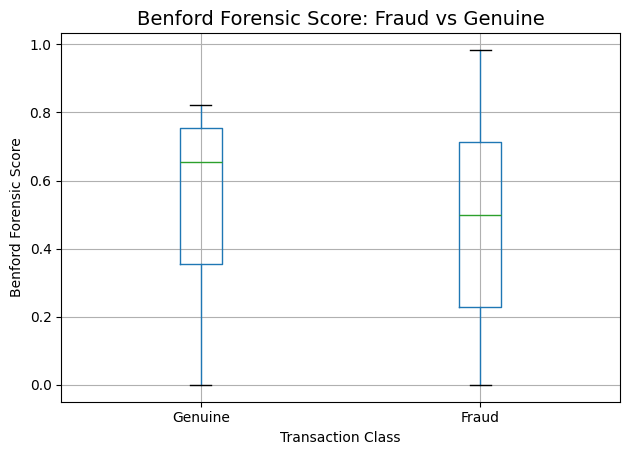

In [ ]:
plt.figure(figsize=(8, 5))

data.boxplot(
    column="BenfordForensicScore",
    by="isFraud"
)

plt.title(
    "Benford Forensic Score: Fraud vs Genuine",
    fontsize=14
)

plt.suptitle("")

plt.xlabel("Transaction Class")
plt.ylabel("Benford Forensic Score")

plt.xticks(
    [1, 2],
    ["Genuine", "Fraud"]
)

plt.tight_layout()
plt.show()

In [ ]:
benford_summary = (
    data.groupby("isFraud")
    ["BenfordForensicScore"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

benford_summary

,count,mean,median,std,min,max
isFraud,,,,,,
0,6354407,0.562330,0.65352,0.206426,0.0,0.822605
1,8213,0.471851,0.50000,0.259719,0.0,0.982709


In [ ]:
final_features = [
    "origBalanceChange",
    "destBalanceChange",
    "origBalanceError",
    "destBalanceError",
    "type_encoded",
    "BenfordTypeScore",
    "time_window_25",
    "BenfordTimeScore_25",
    "sender_transaction_count",
    "receiver_transaction_count",
    "sender_avg_amount",
    "receiver_avg_amount",
    "sender_amount_deviation",
    "receiver_amount_deviation",
    "sender_window_velocity",
    "receiver_window_velocity",
    "BenfordForensicScore"
]

print("Number of engineered features:", len(final_features))

Number of engineered features: 17


In [ ]:
data[final_features].describe().T

,count,mean,std,min,25%,50%,75%,max
origBalanceChange,6362620.0,-21230.564504,146643.286486,-1.915268e+06,0.000000e+00,0.000000,10150.435000,1.000000e+07
destBalanceChange,6362620.0,124294.731682,812939.081063,-1.306083e+07,0.000000e+00,0.000000,149105.425000,1.056878e+08
origBalanceError,6362620.0,201092.468248,606650.460080,0.000000e+00,2.954230e+03,68677.255000,249641.087500,9.244552e+07
destBalanceError,6362620.0,93599.071898,435056.981484,0.000000e+00,1.164153e-10,5123.620000,43421.330000,7.588573e+07
type_encoded,6362620.0,1.714150,1.350117,0.000000e+00,1.000000e+00,1.000000,3.000000,4.000000e+00
BenfordTypeScore,6362620.0,0.016628,0.006866,5.426896e-03,9.527081e-03,0.022241,0.022241,2.284360e-02
time_window_25,6362620.0,9.325026,5.720980,0.000000e+00,6.000000e+00,9.000000,13.000000,2.900000e+01
BenfordTimeScore_25,6362620.0,0.014637,0.002128,5.963137e-03,1.315382e-02,0.014544,0.016130,2.398524e-02
sender_transaction_count,6362620.0,1.002932,0.054200,1.000000e+00,1.000000e+00,1.000000,1.000000,3.000000e+00
receiver_transaction_count,6362620.0,11.192238,12.395440,1.000000e+00,1.000000e+00,7.000000,17.000000,1.130000e+02


In [ ]:
feature_comparison = (
    data.groupby("isFraud")[final_features]
    .mean()
    .T
)

feature_comparison

isFraud,0,1
origBalanceChange,-23141.516382,1.457275e+06
destBalanceChange,123504.809994,7.354580e+05
origBalanceError,201338.558304,1.069233e+04
destBalanceError,92756.964361,7.451386e+05
type_encoded,1.713139,2.496530e+00
BenfordTypeScore,0.016631,1.385354e-02
time_window_25,9.318649,1.425874e+01
BenfordTimeScore_25,0.014638,1.425106e-02
sender_transaction_count,1.002932,1.003409e+00
receiver_transaction_count,11.196240,8.095337e+00


In [ ]:
correlation_features = [
    "amount",
    "origBalanceChange",
    "destBalanceChange",
    "origBalanceError",
    "destBalanceError",
    "sender_transaction_count",
    "receiver_transaction_count",
    "sender_avg_amount",
    "receiver_avg_amount",
    "sender_amount_deviation",
    "receiver_amount_deviation",
    "sender_window_velocity",
    "receiver_window_velocity",
    "BenfordForensicScore",
    "isFraud"
]

correlation_with_fraud = (
    data[correlation_features]
    .corr()["isFraud"]
    .sort_values(
        ascending=False
    )
)

correlation_with_fraud

,isFraud
isFraud,1.000000
origBalanceChange,0.362472
receiver_avg_amount,0.079746
amount,0.076688
sender_avg_amount,0.076671
destBalanceError,0.053840
receiver_amount_deviation,0.042675
destBalanceChange,0.027028
sender_transaction_count,0.000316
sender_window_velocity,0.000139


In [ ]:
print(
    "Total missing values:",
    data.isnull().sum().sum()
)

Total missing values: 0


In [ ]:
score_columns = [
    "BenfordTypeScore",
    "BenfordTimeScore_25",
    "BenfordForensicScore"
]

for col in score_columns:
    data[col] = data[col].fillna(0)

print(
    "Missing values after score handling:",
    data.isnull().sum().sum()
)

Missing values after score handling: 0


In [ ]:
numeric_data = data.select_dtypes(
    include=np.number
)

infinite_count = np.isinf(
    numeric_data
).sum().sum()

print(
    "Infinite values:",
    infinite_count
)

Infinite values: 0


In [ ]:
print(
    "Final Member 1 Dataset Shape:",
    data.shape
)

print(
    "\nTotal Features:",
    len(data.columns)
)

print(
    "\nFraud Cases:",
    data["isFraud"].sum()
)

print(
    "Genuine Cases:",
    (data["isFraud"] == 0).sum()
)

Final Member 1 Dataset Shape: (6362620, 30)

Total Features: 30

Fraud Cases: 8213
Genuine Cases: 6354407


In [ ]:
print("FINAL COLUMNS:\n")

for i, column in enumerate(
    data.columns,
    start=1
):
    print(
        f"{i}. {column}"
    )

FINAL COLUMNS:

1. step
2. type
3. amount
4. nameOrig
5. oldbalanceOrg
6. newbalanceOrig
7. nameDest
8. oldbalanceDest
9. newbalanceDest
10. isFraud
11. isFlaggedFraud
12. origBalanceChange
13. destBalanceChange
14. origBalanceError
15. destBalanceError
16. type_encoded
17. BenfordTypeScore
18. time_window_25
19. BenfordTimeScore_25
20. sender_transaction_count
21. receiver_transaction_count
22. sender_avg_amount
23. receiver_avg_amount
24. sender_amount_deviation
25. receiver_amount_deviation
26. sender_window_velocity
27. receiver_window_velocity
28. BenfordTypeScore_Norm
29. BenfordTimeScore_Norm
30. BenfordForensicScore


In [ ]:
# FAST SAVE — Parquet format

final_output = "ForensicFusion_Member1_Final.parquet"

data.to_parquet(
    final_output,
    index=False,
    engine="pyarrow"
)

print("Final Member 1 dataset saved successfully!")
print("File:", final_output)

Final Member 1 dataset saved successfully!
File: ForensicFusion_Member1_Final.parquet


In [ ]:
print("Shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Fraud cases:", data["isFraud"].sum())

Shape: (6362620, 30)
Missing values: 0
Fraud cases: 8213


Mem-2

In [ ]:
import pyarrow.parquet as pq

file_path = "ForensicFusion_Member1_Final.parquet"

parquet_file = pq.ParquetFile(file_path)

print("Number of rows:", parquet_file.metadata.num_rows)
print("Number of row groups:", parquet_file.num_row_groups)

print("\nColumns:")
for column in parquet_file.schema.names:
    print(column)

Number of rows: 6362620
Number of row groups: 7

Columns:
step
type
amount
nameOrig
oldbalanceOrg
newbalanceOrig
nameDest
oldbalanceDest
newbalanceDest
isFraud
isFlaggedFraud
origBalanceChange
destBalanceChange
origBalanceError
destBalanceError
type_encoded
BenfordTypeScore
time_window_25
BenfordTimeScore_25
sender_transaction_count
receiver_transaction_count
sender_avg_amount
receiver_avg_amount
sender_amount_deviation
receiver_amount_deviation
sender_window_velocity
receiver_window_velocity
BenfordTypeScore_Norm
BenfordTimeScore_Norm
BenfordForensicScore


In [ ]:
import pyarrow.parquet as pq
import pandas as pd

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

print("=" * 60)
print("FORENSICFUSION - MEMBER 2 DATASET INSPECTION")
print("=" * 60)

print("Rows:", pf.metadata.num_rows)
print("Row groups:", pf.num_row_groups)
print("Columns:", len(pf.schema.names))

print("\nColumn names:")
for i, col in enumerate(pf.schema.names, 1):
    print(f"{i:2d}. {col}")

# Read only first 10,000 rows
sample_df = pd.read_parquet(
    FILE_PATH,
    engine="pyarrow",
    columns=pf.schema.names
).head(10000)

print("\nSample shape:", sample_df.shape)

print("\nData types:")
print(sample_df.dtypes)

print("\nFirst 5 rows:")
display(sample_df.head())

FORENSICFUSION - MEMBER 2 DATASET INSPECTION
Rows: 6362620
Row groups: 7
Columns: 30

Column names:
 1. step
 2. type
 3. amount
 4. nameOrig
 5. oldbalanceOrg
 6. newbalanceOrig
 7. nameDest
 8. oldbalanceDest
 9. newbalanceDest
10. isFraud
11. isFlaggedFraud
12. origBalanceChange
13. destBalanceChange
14. origBalanceError
15. destBalanceError
16. type_encoded
17. BenfordTypeScore
18. time_window_25
19. BenfordTimeScore_25
20. sender_transaction_count
21. receiver_transaction_count
22. sender_avg_amount
23. receiver_avg_amount
24. sender_amount_deviation
25. receiver_amount_deviation
26. sender_window_velocity
27. receiver_window_velocity
28. BenfordTypeScore_Norm
29. BenfordTimeScore_Norm
30. BenfordForensicScore


Full Dataset Statistics

In [ ]:
import pyarrow.parquet as pq
import pandas as pd

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

total_fraud = 0
total_genuine = 0
min_step = float("inf")
max_step = float("-inf")

for i in range(pf.num_row_groups):

    rg = pf.read_row_group(
        i,
        columns=["isFraud", "step"]
    ).to_pandas()

    fraud_count = int((rg["isFraud"] == 1).sum())
    genuine_count = int((rg["isFraud"] == 0).sum())

    total_fraud += fraud_count
    total_genuine += genuine_count

    min_step = min(min_step, rg["step"].min())
    max_step = max(max_step, rg["step"].max())

    del rg

total = total_fraud + total_genuine

print("=" * 60)
print("FULL DATASET STATISTICS")
print("=" * 60)

print(f"Total transactions : {total:,}")
print(f"Genuine            : {total_genuine:,}")
print(f"Fraud              : {total_fraud:,}")

print(f"\nGenuine percentage  : {(total_genuine / total) * 100:.4f}%")
print(f"Fraud percentage    : {(total_fraud / total) * 100:.4f}%")

print(f"\nMinimum step       : {min_step}")
print(f"Maximum step       : {max_step}")

FULL DATASET STATISTICS
Total transactions : 6,362,620
Genuine            : 6,354,407
Fraud              : 8,213

Genuine percentage  : 99.8709%
Fraud percentage    : 0.1291%

Minimum step       : 1
Maximum step       : 743


Check the Benford evidence

In [ ]:
print("=" * 60)
print("BENFORD FORENSIC SCORE")
print("=" * 60)

benford_values = []

for i in range(pf.num_row_groups):

    rg = pf.read_row_group(
        i,
        columns=["BenfordForensicScore"]
    ).to_pandas()

    benford_values.append(rg["BenfordForensicScore"])

benford = pd.concat(benford_values, ignore_index=True)

print(benford.describe())

print("\nMissing values:")
print(benford.isna().sum())

del benford_values
del benford

BENFORD FORENSIC SCORE
count    6.362620e+06
mean     5.622129e-01
std      2.065291e-01
min      0.000000e+00
25%      3.557829e-01
50%      6.535196e-01
75%      7.532605e-01
max      9.827088e-01
Name: BenfordForensicScore, dtype: float64

Missing values:
0


Create the account-to-node mapping

In [ ]:
import pyarrow.parquet as pq

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

account_to_id = {}
next_node_id = 0

print("=" * 60)
print("BUILDING ACCOUNT NODE MAPPING")
print("=" * 60)

for rg_idx in range(pf.num_row_groups):

    rg = pf.read_row_group(
        rg_idx,
        columns=["nameOrig", "nameDest"]
    ).to_pandas()

    accounts = pd.concat(
        [
            rg["nameOrig"],
            rg["nameDest"]
        ],
        ignore_index=True
    ).drop_duplicates()

    for account in accounts:

        if account not in account_to_id:
            account_to_id[account] = next_node_id
            next_node_id += 1

    print(
        f"Row group {rg_idx + 1}/{pf.num_row_groups} | "
        f"Nodes so far: {next_node_id:,}"
    )

    del rg
    del accounts

num_nodes = next_node_id

print("\nTotal unique accounts:", f"{num_nodes:,}")

BUILDING ACCOUNT NODE MAPPING
Row group 1/7 | Nodes so far: 1,497,910
Row group 2/7 | Nodes so far: 2,986,111
Row group 3/7 | Nodes so far: 4,479,367
Row group 4/7 | Nodes so far: 5,979,161
Row group 5/7 | Nodes so far: 7,473,082
Row group 6/7 | Nodes so far: 8,971,312
Row group 7/7 | Nodes so far: 9,073,900

Total unique accounts: 9,073,900


In [ ]:
import pickle

MAPPING_PATH = "account_to_node_mapping.pkl"

with open(MAPPING_PATH, "wb") as f:
    pickle.dump(account_to_id, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Node mapping saved:", MAPPING_PATH)
print("Total nodes:", len(account_to_id))

Node mapping saved: account_to_node_mapping.pkl
Total nodes: 9073900


Create transaction edges

In [ ]:
import os

os.makedirs("graph_data", exist_ok=True)

print("graph_data directory ready.")

graph_data directory ready.


In [ ]:
import pyarrow.parquet as pq
import numpy as np
import os

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

os.makedirs("graph_data/edges", exist_ok=True)

edge_columns = [
    "nameOrig",
    "nameDest",
    "amount",
    "type_encoded",
    "step",
    "BenfordTypeScore",
    "BenfordTimeScore_25",
    "BenfordForensicScore",
    "BenfordTypeScore_Norm",
    "BenfordTimeScore_Norm",
    "time_window_25",
    "origBalanceChange",
    "destBalanceChange",
    "origBalanceError",
    "destBalanceError",
    "sender_amount_deviation",
    "receiver_amount_deviation",
    "sender_window_velocity",
    "receiver_window_velocity",
    "isFraud"
]

for rg_idx in range(pf.num_row_groups):

    print(f"\nProcessing row group {rg_idx + 1}/{pf.num_row_groups}")

    rg = pf.read_row_group(
        rg_idx,
        columns=edge_columns
    ).to_pandas()

    source_nodes = rg["nameOrig"].map(
        account_to_id
    ).to_numpy(dtype=np.int64)

    destination_nodes = rg["nameDest"].map(
        account_to_id
    ).to_numpy(dtype=np.int64)

    feature_columns = [
        "amount",
        "type_encoded",
        "step",
        "BenfordTypeScore",
        "BenfordTimeScore_25",
        "BenfordForensicScore",
        "BenfordTypeScore_Norm",
        "BenfordTimeScore_Norm",
        "time_window_25",
        "origBalanceChange",
        "destBalanceChange",
        "origBalanceError",
        "destBalanceError",
        "sender_amount_deviation",
        "receiver_amount_deviation",
        "sender_window_velocity",
        "receiver_window_velocity"
    ]

    edge_features = rg[
        feature_columns
    ].to_numpy(dtype=np.float32)

    edge_labels = rg["isFraud"].to_numpy(
        dtype=np.int8
    )

    output_path = (
        f"graph_data/edges/"
        f"edge_part_{rg_idx + 1}.npz"
    )

    np.savez(
        output_path,
        source=source_nodes,
        destination=destination_nodes,
        features=edge_features,
        labels=edge_labels
    )

    print("Saved:", output_path)
    print("Edges:", len(source_nodes))
    print("Fraud:", int(edge_labels.sum()))

    del rg
    del source_nodes
    del destination_nodes
    del edge_features
    del edge_labels


Processing row group 1/7
Saved: graph_data/edges/edge_part_1.npz
Edges: 1048576
Fraud: 1142

Processing row group 2/7
Saved: graph_data/edges/edge_part_2.npz
Edges: 1048576
Fraud: 921

Processing row group 3/7
Saved: graph_data/edges/edge_part_3.npz
Edges: 1048576
Fraud: 604

Processing row group 4/7
Saved: graph_data/edges/edge_part_4.npz
Edges: 1048576
Fraud: 762

Processing row group 5/7
Saved: graph_data/edges/edge_part_5.npz
Edges: 1048576
Fraud: 710

Processing row group 6/7
Saved: graph_data/edges/edge_part_6.npz
Edges: 1048576
Fraud: 3178

Processing row group 7/7
Saved: graph_data/edges/edge_part_7.npz
Edges: 71164
Fraud: 896


Create the temporal train/validation/test split

In [ ]:
import pyarrow.parquet as pq
import numpy as np

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

step_values = []

for i in range(pf.num_row_groups):
    rg = pf.read_row_group(
        i,
        columns=["step"]
    )

    step_values.append(
        rg["step"].to_numpy()
    )

steps = np.concatenate(step_values)

train_step_end = np.quantile(steps, 0.70)
val_step_end = np.quantile(steps, 0.85)

print("=" * 60)
print("TEMPORAL SPLIT")
print("=" * 60)

print("Minimum step:", steps.min())
print("Maximum step:", steps.max())

print("\n70% step boundary:", train_step_end)
print("85% step boundary:", val_step_end)

del step_values
del steps

TEMPORAL SPLIT
Minimum step: 1
Maximum step: 743

70% step boundary: 323.0
85% step boundary: 378.0


Create split information for every edge

In [ ]:
import pyarrow.parquet as pq
import numpy as np
import os

FILE_PATH = "ForensicFusion_Member1_Final.parquet"

pf = pq.ParquetFile(FILE_PATH)

# Temporal boundaries obtained from Step 9
TRAIN_END = 323
VAL_END = 378

# Output directories
os.makedirs("graph_data/train", exist_ok=True)
os.makedirs("graph_data/val", exist_ok=True)
os.makedirs("graph_data/test", exist_ok=True)

feature_columns = [
    "amount",
    "type_encoded",
    "step",
    "BenfordTypeScore",
    "BenfordTimeScore_25",
    "BenfordForensicScore",
    "BenfordTypeScore_Norm",
    "BenfordTimeScore_Norm",
    "time_window_25",
    "origBalanceChange",
    "destBalanceChange",
    "origBalanceError",
    "destBalanceError",
    "sender_amount_deviation",
    "receiver_amount_deviation",
    "sender_window_velocity",
    "receiver_window_velocity"
]

columns_to_read = [
    "nameOrig",
    "nameDest"
] + feature_columns + ["isFraud"]

# Statistics
total_train = 0
total_val = 0
total_test = 0

fraud_train = 0
fraud_val = 0
fraud_test = 0

print("=" * 60)
print("CREATING TEMPORAL EDGE SPLITS")
print("=" * 60)

for rg_idx in range(pf.num_row_groups):

    print(f"\nProcessing row group {rg_idx + 1}/{pf.num_row_groups}")

    rg = pf.read_row_group(
        rg_idx,
        columns=columns_to_read
    ).to_pandas()

    # --------------------------------------------------
    # Convert account names → node IDs
    # --------------------------------------------------

    source = rg["nameOrig"].map(
        account_to_id
    ).to_numpy(dtype=np.int64)

    destination = rg["nameDest"].map(
        account_to_id
    ).to_numpy(dtype=np.int64)

    # --------------------------------------------------
    # Edge features
    # --------------------------------------------------

    features = rg[
        feature_columns
    ].to_numpy(dtype=np.float32)

    labels = rg["isFraud"].to_numpy(
        dtype=np.int8
    )

    steps = rg["step"].to_numpy(
        dtype=np.int32
    )

    # --------------------------------------------------
    # Temporal masks
    # --------------------------------------------------

    train_mask = steps <= TRAIN_END

    val_mask = (
        (steps > TRAIN_END) &
        (steps <= VAL_END)
    )

    test_mask = steps > VAL_END

    # --------------------------------------------------
    # Save TRAIN
    # --------------------------------------------------

    if train_mask.any():

        path = (
            f"graph_data/train/"
            f"edge_part_{rg_idx + 1}.npz"
        )

        np.savez(
            path,
            source=source[train_mask],
            destination=destination[train_mask],
            features=features[train_mask],
            labels=labels[train_mask],
            step=steps[train_mask]
        )

        total_train += train_mask.sum()
        fraud_train += labels[train_mask].sum()

    # --------------------------------------------------
    # Save VALIDATION
    # --------------------------------------------------

    if val_mask.any():

        path = (
            f"graph_data/val/"
            f"edge_part_{rg_idx + 1}.npz"
        )

        np.savez(
            path,
            source=source[val_mask],
            destination=destination[val_mask],
            features=features[val_mask],
            labels=labels[val_mask],
            step=steps[val_mask]
        )

        total_val += val_mask.sum()
        fraud_val += labels[val_mask].sum()

    # --------------------------------------------------
    # Save TEST
    # --------------------------------------------------

    if test_mask.any():

        path = (
            f"graph_data/test/"
            f"edge_part_{rg_idx + 1}.npz"
        )

        np.savez(
            path,
            source=source[test_mask],
            destination=destination[test_mask],
            features=features[test_mask],
            labels=labels[test_mask],
            step=steps[test_mask]
        )

        total_test += test_mask.sum()
        fraud_test += labels[test_mask].sum()

    print(
        f"Train: {train_mask.sum():,} | "
        f"Val: {val_mask.sum():,} | "
        f"Test: {test_mask.sum():,}"
    )

    del rg
    del source
    del destination
    del features
    del labels
    del steps

print("\n" + "=" * 60)
print("TEMPORAL SPLIT COMPLETE")
print("=" * 60)

print(f"Train transactions : {total_train:,}")
print(f"Validation         : {total_val:,}")
print(f"Test               : {total_test:,}")

print("\nFraud transactions:")
print(f"Train fraud        : {fraud_train:,}")
print(f"Validation fraud   : {fraud_val:,}")
print(f"Test fraud         : {fraud_test:,}")

print("\nFraud percentages:")
print(
    f"Train : {(fraud_train / total_train) * 100:.4f}%"
)

print(
    f"Val   : {(fraud_val / total_val) * 100:.4f}%"
)

print(
    f"Test  : {(fraud_test / total_test) * 100:.4f}%"
)

CREATING TEMPORAL EDGE SPLITS

Processing row group 1/7
Train: 1,048,576 | Val: 0 | Test: 0

Processing row group 2/7
Train: 1,048,576 | Val: 0 | Test: 0

Processing row group 3/7
Train: 1,048,576 | Val: 0 | Test: 0

Processing row group 4/7
Train: 1,048,576 | Val: 0 | Test: 0

Processing row group 5/7
Train: 269,283 | Val: 779,293 | Test: 0

Processing row group 6/7
Train: 0 | Val: 201,123 | Test: 847,453

Processing row group 7/7
Train: 0 | Val: 0 | Test: 71,164

TEMPORAL SPLIT COMPLETE
Train transactions : 4,463,587
Validation         : 980,416
Test               : 918,617

Fraud transactions:
Train fraud        : 3,643
Validation fraud   : 564
Test fraud         : 4,006

Fraud percentages:
Train : 0.0816%
Val   : 0.0575%
Test  : 0.4361%


Verify the split

In [ ]:
import glob
import numpy as np

def inspect_split(folder):

    files = sorted(
        glob.glob(f"{folder}/edge_part_*.npz")
    )

    total = 0
    fraud = 0
    min_step = float("inf")
    max_step = float("-inf")

    for file in files:

        data = np.load(file)

        labels = data["labels"]
        steps = data["step"]

        total += len(labels)
        fraud += labels.sum()

        min_step = min(min_step, steps.min())
        max_step = max(max_step, steps.max())

    return {
        "files": len(files),
        "transactions": total,
        "fraud": int(fraud),
        "fraud_%": 100 * fraud / total,
        "min_step": min_step,
        "max_step": max_step
    }


print("TRAIN")
print(inspect_split("graph_data/train"))

print("\nVALIDATION")
print(inspect_split("graph_data/val"))

print("\nTEST")
print(inspect_split("graph_data/test"))

TRAIN
{'files': 5, 'transactions': 4463587, 'fraud': 3643, 'fraud_%': np.float64(0.08161597387930379), 'min_step': np.int32(1), 'max_step': np.int32(323)}

VALIDATION
{'files': 2, 'transactions': 980416, 'fraud': 564, 'fraud_%': np.float64(0.05752660095306482), 'min_step': np.int32(324), 'max_step': np.int32(378)}

TEST
{'files': 2, 'transactions': 918617, 'fraud': 4006, 'fraud_%': np.float64(0.43609034015264253), 'min_step': np.int32(379), 'max_step': np.int32(743)}


A — Initialize node accumulators

In [ ]:
import numpy as np

NUM_NODES = len(account_to_id)

print("Number of nodes:", f"{NUM_NODES:,}")

# Count
out_count = np.zeros(NUM_NODES, dtype=np.int32)
in_count = np.zeros(NUM_NODES, dtype=np.int32)

# Amount sums
out_amount_sum = np.zeros(NUM_NODES, dtype=np.float64)
in_amount_sum = np.zeros(NUM_NODES, dtype=np.float64)

# Amount maximum
out_amount_max = np.zeros(NUM_NODES, dtype=np.float32)
in_amount_max = np.zeros(NUM_NODES, dtype=np.float32)

# Benford sums
out_benford_sum = np.zeros(NUM_NODES, dtype=np.float64)
in_benford_sum = np.zeros(NUM_NODES, dtype=np.float64)

# Velocity sums
out_velocity_sum = np.zeros(NUM_NODES, dtype=np.float64)
in_velocity_sum = np.zeros(NUM_NODES, dtype=np.float64)

print("Node accumulators created.")

Number of nodes: 9,073,900
Node accumulators created.


B — Aggregate only TRAIN transactions

In [ ]:
import glob
import numpy as np

train_files = sorted(
    glob.glob("graph_data/train/edge_part_*.npz")
)

print("Training edge files:", len(train_files))

for file_idx, file in enumerate(train_files, 1):

    print(
        f"Processing training file "
        f"{file_idx}/{len(train_files)}"
    )

    data = np.load(file)

    src = data["source"]
    dst = data["destination"]
    features = data["features"]

    # --------------------------------------------------
    # Feature positions
    # --------------------------------------------------

    # 0  amount
    # 1  type_encoded
    # 2  step
    # 3  BenfordTypeScore
    # 4  BenfordTimeScore_25
    # 5  BenfordForensicScore
    # 6  BenfordTypeScore_Norm
    # 7  BenfordTimeScore_Norm
    # 8  time_window_25
    # 9  origBalanceChange
    # 10 destBalanceChange
    # 11 origBalanceError
    # 12 destBalanceError
    # 13 sender_amount_deviation
    # 14 receiver_amount_deviation
    # 15 sender_window_velocity
    # 16 receiver_window_velocity

    amount = features[:, 0]
    benford = features[:, 5]

    sender_velocity = features[:, 15]
    receiver_velocity = features[:, 16]

    # --------------------------------------------------
    # Sender aggregation
    # --------------------------------------------------

    np.add.at(
        out_count,
        src,
        1
    )

    np.add.at(
        out_amount_sum,
        src,
        amount
    )

    np.maximum.at(
        out_amount_max,
        src,
        amount
    )

    np.add.at(
        out_benford_sum,
        src,
        benford
    )

    np.add.at(
        out_velocity_sum,
        src,
        sender_velocity
    )

    # --------------------------------------------------
    # Receiver aggregation
    # --------------------------------------------------

    np.add.at(
        in_count,
        dst,
        1
    )

    np.add.at(
        in_amount_sum,
        dst,
        amount
    )

    np.maximum.at(
        in_amount_max,
        dst,
        amount
    )

    np.add.at(
        in_benford_sum,
        dst,
        benford
    )

    np.add.at(
        in_velocity_sum,
        dst,
        receiver_velocity
    )

    del data
    del src
    del dst
    del features

print("\nTraining-period node aggregation complete.")

Training edge files: 5
Processing training file 1/5
Processing training file 2/5
Processing training file 3/5
Processing training file 4/5
Processing training file 5/5

Training-period node aggregation complete.


C — Convert sums to averages

In [ ]:
out_avg_amount = np.zeros(NUM_NODES, dtype=np.float32)
in_avg_amount = np.zeros(NUM_NODES, dtype=np.float32)

out_avg_benford = np.zeros(NUM_NODES, dtype=np.float32)
in_avg_benford = np.zeros(NUM_NODES, dtype=np.float32)

out_avg_velocity = np.zeros(NUM_NODES, dtype=np.float32)
in_avg_velocity = np.zeros(NUM_NODES, dtype=np.float32)


# Outgoing averages
out_mask = out_count > 0

out_avg_amount[out_mask] = (
    out_amount_sum[out_mask] /
    out_count[out_mask]
)

out_avg_benford[out_mask] = (
    out_benford_sum[out_mask] /
    out_count[out_mask]
)

out_avg_velocity[out_mask] = (
    out_velocity_sum[out_mask] /
    out_count[out_mask]
)


# Incoming averages
in_mask = in_count > 0

in_avg_amount[in_mask] = (
    in_amount_sum[in_mask] /
    in_count[in_mask]
)

in_avg_benford[in_mask] = (
    in_benford_sum[in_mask] /
    in_count[in_mask]
)

in_avg_velocity[in_mask] = (
    in_velocity_sum[in_mask] /
    in_count[in_mask]
)

print("Average features calculated.")

Average features calculated.


D — Create the final node feature matrix

In [ ]:
node_features = np.column_stack([
    out_count,
    in_count,
    out_amount_sum,
    in_amount_sum,
    out_avg_amount,
    in_avg_amount,
    out_amount_max,
    in_amount_max,
    out_avg_benford,
    in_avg_benford,
    out_avg_velocity,
    in_avg_velocity
]).astype(np.float32)

print("Node feature shape:", node_features.shape)

Node feature shape: (9073900, 12)


E — Save it

In [ ]:
NODE_FEATURE_PATH = "graph_data/node_features_train.npy"

np.save(
    NODE_FEATURE_PATH,
    node_features
)

print("Saved:", NODE_FEATURE_PATH)

Saved: graph_data/node_features_train.npy


In [ ]:
del node_features

print("Node feature matrix released from RAM.")

Node feature matrix released from RAM.


In [ ]:
zero_out = np.count_nonzero(out_count == 0)
zero_in = np.count_nonzero(in_count == 0)

zero_both = np.count_nonzero(
    (out_count == 0) &
    (in_count == 0)
)

print("=" * 60)
print("NODE FEATURE COVERAGE")
print("=" * 60)

print(
    "Nodes with no outgoing training transactions:",
    f"{zero_out:,}"
)

print(
    "Nodes with no incoming training transactions:",
    f"{zero_in:,}"
)

print(
    "Nodes with no training activity at all:",
    f"{zero_both:,}"
)

print(
    "Nodes with training activity:",
    f"{NUM_NODES - zero_both:,}"
)

NODE FEATURE COVERAGE
Nodes with no outgoing training transactions: 4,614,951
Nodes with no incoming training transactions: 7,168,124
Nodes with no training activity at all: 2,710,076
Nodes with training activity: 6,363,824


13 — Normalize the node features

In [ ]:
import numpy as np

NODE_FEATURE_PATH = "graph_data/node_features_train.npy"

node_features = np.load(
    NODE_FEATURE_PATH,
    mmap_mode="r"
)

print("Node feature shape:", node_features.shape)

# Calculate statistics only from training-derived node features
feature_mean = np.mean(
    node_features,
    axis=0
)

feature_std = np.std(
    node_features,
    axis=0
)

# Prevent division by zero
feature_std[feature_std < 1e-8] = 1.0

print("\nFeature means:")
print(feature_mean)

print("\nFeature standard deviations:")
print(feature_std)

Node feature shape: (9073900, 12)

Feature means:
[4.9191493e-01 4.9191493e-01 8.5388000e+04 8.4984789e+04 8.5301664e+04
 1.2194788e+04 8.5360320e+04 2.8984893e+04 2.6643187e-01 8.5303292e-02
 4.9145406e-01 2.6069513e-01]

Feature standard deviations:
[5.02294600e-01 2.24047494e+00 4.41425656e+05 9.72745375e+05
 4.41050031e+05 1.07400734e+05 4.41397531e+05 3.47258812e+05
 3.01540554e-01 1.67664513e-01 5.01391470e-01 6.59469008e-01]


In [ ]:
np.save(
    "graph_data/node_feature_mean.npy",
    feature_mean
)

np.save(
    "graph_data/node_feature_std.npy",
    feature_std
)

print("Normalization statistics saved.")

Normalization statistics saved.


14 — Create a memory-mapped normalized feature matrix

In [ ]:
import numpy as np

input_path = "graph_data/node_features_train.npy"
output_path = "graph_data/node_features_normalized.npy"

features = np.load(
    input_path,
    mmap_mode="r"
)

mean = np.load(
    "graph_data/node_feature_mean.npy"
)

std = np.load(
    "graph_data/node_feature_std.npy"
)

normalized = np.lib.format.open_memmap(
    output_path,
    mode="w+",
    dtype=np.float32,
    shape=features.shape
)

chunk_size = 250_000

for start in range(
    0,
    features.shape[0],
    chunk_size
):

    end = min(
        start + chunk_size,
        features.shape[0]
    )

    normalized[start:end] = (
        (features[start:end] - mean) / std
    )

    if start % 1_000_000 == 0:
        print(
            f"Processed {start:,}/"
            f"{features.shape[0]:,}"
        )

normalized.flush()

print("\nNormalized node features saved:")
print(output_path)

Processed 0/9,073,900
Processed 1,000,000/9,073,900
Processed 2,000,000/9,073,900
Processed 3,000,000/9,073,900
Processed 4,000,000/9,073,900
Processed 5,000,000/9,073,900
Processed 6,000,000/9,073,900
Processed 7,000,000/9,073,900
Processed 8,000,000/9,073,900
Processed 9,000,000/9,073,900

Normalized node features saved:
graph_data/node_features_normalized.npy


15 — Verify normalization

In [ ]:
normalized = np.load(
    "graph_data/node_features_normalized.npy",
    mmap_mode="r"
)

print("Shape:", normalized.shape)

sample = normalized[
    :1_000_000
]

print("\nSample mean:")
print(sample.mean(axis=0))

print("\nSample std:")
print(sample.std(axis=0))

Shape: (9073900, 12)

Sample mean:
[ 1.0070646  -0.21829668  0.17029941 -0.0861968   0.16993347 -0.11439969
  0.17013009 -0.08308506  0.9290385  -0.50528014  1.0042225  -0.39725292]

Sample std:
[0.08714353 0.05502574 0.58969754 0.05787985 0.58779466 0.12186514
 0.58939517 0.07851014 0.6521709  0.05509479 0.02421815 0.04884108]


16 — Install/check PyTorch Geometric

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

checkpoint_dir = "/content/drive/MyDrive/Forensic-Project"

os.makedirs(checkpoint_dir, exist_ok=True)

print("Checkpoint directory:")
print(checkpoint_dir)

Checkpoint directory:
/content/drive/MyDrive/Forensic-Project


In [ ]:
try:
    import torch_geometric

    print(
        "PyTorch Geometric version:",
        torch_geometric.__version__
    )

except ImportError:
    print("PyTorch Geometric is not installed.")

PyTorch Geometric version: 2.8.0.post1


18 — We need a compact graph representation

In [ ]:
import glob
import numpy as np

train_files = sorted(
    glob.glob("graph_data/train/edge_part_*.npz")
)

val_files = sorted(
    glob.glob("graph_data/val/edge_part_*.npz")
)

test_files = sorted(
    glob.glob("graph_data/test/edge_part_*.npz")
)

print("Train files:", len(train_files))
print("Validation files:", len(val_files))
print("Test files:", len(test_files))

Train files: 5
Validation files: 2
Test files: 2


In [ ]:
import numpy as np
import glob

all_files = (
    train_files +
    val_files +
    test_files
)

total_edges = 0

for file in all_files:
    data = np.load(file)
    total_edges += len(data["source"])

print("Total edges:", f"{total_edges:,}")

Total edges: 6,362,620


In [ ]:
edge_index_path = (
    "graph_data/edge_index.npy"
)

edge_index = np.lib.format.open_memmap(
    edge_index_path,
    mode="w+",
    dtype=np.int64,
    shape=(2, total_edges)
)

position = 0

for idx, file in enumerate(all_files, 1):

    data = np.load(file)

    n = len(data["source"])

    edge_index[0, position:position+n] = (
        data["source"]
    )

    edge_index[1, position:position+n] = (
        data["destination"]
    )

    position += n

    print(
        f"Processed {idx}/{len(all_files)} "
        f"files | {position:,} edges"
    )

edge_index.flush()

print("\nSaved:")
print(edge_index_path)
print("Shape:", edge_index.shape)

Processed 1/9 files | 1,048,576 edges
Processed 2/9 files | 2,097,152 edges
Processed 3/9 files | 3,145,728 edges
Processed 4/9 files | 4,194,304 edges
Processed 5/9 files | 4,463,587 edges
Processed 6/9 files | 5,242,880 edges
Processed 7/9 files | 5,444,003 edges
Processed 8/9 files | 6,291,456 edges
Processed 9/9 files | 6,362,620 edges

Saved:
graph_data/edge_index.npy
Shape: (2, 6362620)


19 — Verify graph connectivity

In [ ]:
edge_index = np.load(
    "graph_data/edge_index.npy",
    mmap_mode="r"
)

print("Edge index shape:", edge_index.shape)

print("Minimum source ID:", edge_index[0].min())
print("Maximum source ID:", edge_index[0].max())

print("Minimum destination ID:", edge_index[1].min())
print("Maximum destination ID:", edge_index[1].max())

print("Expected maximum node ID:",
      NUM_NODES - 1)

Edge index shape: (2, 6362620)
Minimum source ID: 0
Maximum source ID: 9042282
Minimum destination ID: 571
Maximum destination ID: 9073899
Expected maximum node ID: 9073899


In [ ]:
import torch_geometric
print(torch_geometric.__version__)

2.8.0.post1


20 — Create training-only edge_index

In [ ]:
import glob
import numpy as np

train_files = sorted(
    glob.glob("graph_data/train/edge_part_*.npz")
)

total_train_edges = 0

for file in train_files:
    data = np.load(file)
    total_train_edges += len(data["source"])

print("Training edges:", f"{total_train_edges:,}")

Training edges: 4,463,587


Training Graph

In [ ]:
train_edge_index_path = (
    "graph_data/train_edge_index.npy"
)

train_edge_index = np.lib.format.open_memmap(
    train_edge_index_path,
    mode="w+",
    dtype=np.int64,
    shape=(2, total_train_edges)
)

position = 0

for idx, file in enumerate(train_files, 1):

    data = np.load(file)

    n = len(data["source"])

    train_edge_index[
        0,
        position:position+n
    ] = data["source"]

    train_edge_index[
        1,
        position:position+n
    ] = data["destination"]

    position += n

    print(
        f"Processed {idx}/{len(train_files)} "
        f"| {position:,} edges"
    )

train_edge_index.flush()

print("\nTraining graph saved:")
print(train_edge_index_path)
print("Shape:", train_edge_index.shape)

Processed 1/5 | 1,048,576 edges
Processed 2/5 | 2,097,152 edges
Processed 3/5 | 3,145,728 edges
Processed 4/5 | 4,194,304 edges
Processed 5/5 | 4,463,587 edges

Training graph saved:
graph_data/train_edge_index.npy
Shape: (2, 4463587)


21 — Verify the training graph

In [ ]:
train_edge_index = np.load(
    "graph_data/train_edge_index.npy",
    mmap_mode="r"
)

print("=" * 60)
print("TRAINING GRAPH VERIFICATION")
print("=" * 60)

print("Shape:", train_edge_index.shape)

print(
    "Minimum source:",
    train_edge_index[0].min()
)

print(
    "Maximum source:",
    train_edge_index[0].max()
)

print(
    "Minimum destination:",
    train_edge_index[1].min()
)

print(
    "Maximum destination:",
    train_edge_index[1].max()
)

print(
    "Expected node range:",
    0,
    "to",
    NUM_NODES - 1
)

TRAINING GRAPH VERIFICATION
Shape: (2, 4463587)
Minimum source: 0
Maximum source: 6247853
Minimum destination: 571
Maximum destination: 7141176
Expected node range: 0 to 9073899


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

PyTorch: 2.11.0+cpu
PyG: 2.8.0.post1
Device: cpu


23 — Prepare GraphSAGE

In [ ]:
class GraphSAGEEncoder(nn.Module):

    def __init__(
        self,
        in_channels=12,
        hidden_channels=64,
        out_channels=64,
        dropout=0.2
    ):
        super().__init__()

        self.conv1 = SAGEConv(
            in_channels,
            hidden_channels
        )

        self.conv2 = SAGEConv(
            hidden_channels,
            out_channels
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        return x

In [ ]:
class TransactionFraudClassifier(nn.Module):

    def __init__(
        self,
        node_embedding_dim=64,
        edge_feature_dim=17,
        hidden_dim=64
    ):
        super().__init__()

        input_dim = (
            node_embedding_dim * 2
            + edge_feature_dim
        )

        self.mlp = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(
                hidden_dim,
                1
            )
        )

    def forward(
        self,
        sender_embedding,
        receiver_embedding,
        edge_features
    ):

        combined = torch.cat(
            [
                sender_embedding,
                receiver_embedding,
                edge_features
            ],
            dim=1
        )

        return self.mlp(combined).squeeze(1)

In [ ]:
class ForensicFusionGraphSAGE(nn.Module):

    def __init__(
        self,
        node_features=12,
        edge_features=17,
        hidden_dim=64,
        embedding_dim=64
    ):
        super().__init__()

        self.encoder = GraphSAGEEncoder(
            in_channels=node_features,
            hidden_channels=hidden_dim,
            out_channels=embedding_dim
        )

        self.classifier = TransactionFraudClassifier(
            node_embedding_dim=embedding_dim,
            edge_feature_dim=edge_features,
            hidden_dim=hidden_dim
        )

    def forward(
        self,
        x,
        graph_edge_index,
        source_nodes,
        destination_nodes,
        transaction_features
    ):

        # GraphSAGE account embeddings
        embeddings = self.encoder(
            x,
            graph_edge_index
        )

        # Select sender/receiver embeddings
        sender_embedding = embeddings[
            source_nodes
        ]

        receiver_embedding = embeddings[
            destination_nodes
        ]

        # Transaction fraud prediction
        logits = self.classifier(
            sender_embedding,
            receiver_embedding,
            transaction_features
        )

        return logits

24 — Prepare the training graph for LinkNeighborLoader

In [ ]:
import torch
from torch_geometric.data import Data

# Load training graph
train_edge_index_np = np.load(
    "graph_data/train_edge_index.npy",
    mmap_mode="r"
)

# Convert connectivity to torch
train_edge_index = torch.from_numpy(
    np.asarray(train_edge_index_np)
).long()

print("=" * 60)
print("PYG TRAINING GRAPH")
print("=" * 60)

print("Edge index shape:", train_edge_index.shape)
print("Number of nodes:", NUM_NODES)
print("Number of edges:", train_edge_index.shape[1])

PYG TRAINING GRAPH
Edge index shape: torch.Size([2, 4463587])
Number of nodes: 9073900
Number of edges: 4463587


/tmp/ipykernel_3216/929660704.py:11: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  train_edge_index = torch.from_numpy(


In [ ]:
train_graph = Data(
    edge_index=train_edge_index,
    num_nodes=NUM_NODES
)

print(train_graph)

Data(edge_index=[2, 4463587], num_nodes=9073900)


In [ ]:
train_sources = []
train_destinations = []
train_labels = []

for idx, file in enumerate(train_files, 1):

    data = np.load(file)

    train_sources.append(
        data["source"]
    )

    train_destinations.append(
        data["destination"]
    )

    train_labels.append(
        data["labels"]
    )

    print(
        f"Loaded {idx}/{len(train_files)}"
    )

train_sources = np.concatenate(
    train_sources
)

train_destinations = np.concatenate(
    train_destinations
)

train_labels = np.concatenate(
    train_labels
)

print("\nTraining transaction arrays:")
print("Sources:", train_sources.shape)
print("Destinations:", train_destinations.shape)
print("Labels:", train_labels.shape)

print(
    "Fraud:",
    train_labels.sum()
)

Loaded 1/5
Loaded 2/5
Loaded 3/5
Loaded 4/5
Loaded 5/5

Training transaction arrays:
Sources: (4463587,)
Destinations: (4463587,)
Labels: (4463587,)
Fraud: 3643


Create the positive/negative edge label index

In [ ]:
train_target_edges = torch.tensor(
    np.vstack([
        train_sources,
        train_destinations
    ]),
    dtype=torch.long
)

train_target_labels = torch.tensor(
    train_labels,
    dtype=torch.float32
)

print(
    "Target edge index:",
    train_target_edges.shape
)

print(
    "Target labels:",
    train_target_labels.shape
)

Target edge index: torch.Size([2, 4463587])
Target labels: torch.Size([4463587])


In [ ]:
unique, counts = np.unique(
    train_labels,
    return_counts=True
)

print("=" * 60)
print("TRAINING LABEL DISTRIBUTION")
print("=" * 60)

for u, c in zip(unique, counts):

    print(
        f"Label {u}: {c:,} "
        f"({100*c/len(train_labels):.6f}%)"
    )

TRAINING LABEL DISTRIBUTION
Label 0: 4,459,944 (99.918384%)
Label 1: 3,643 (0.081616%)


25 — Create the LinkNeighborLoader

In [ ]:
from torch_geometric.loader import LinkNeighborLoader

train_loader = LinkNeighborLoader(
    train_graph,

    num_neighbors=[10, 5],

    # Pass train_target_edges to edge_label_index
    edge_label_index=train_target_edges,
    # Pass train_target_labels to edge_label
    edge_label=train_target_labels,

    batch_size=512,

    shuffle=True,

    num_workers=0
)

print("Training LinkNeighborLoader created.")

/usr/local/lib/python3.12/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


Training LinkNeighborLoader created.


A — Test ONE batch only

In [ ]:
!pip install pyg-lib

In [ ]:
import pyg_lib

print("PyG-Lib:", pyg_lib.__version__)

PyG-Lib: 0.8.0+pt211cpu


In [ ]:
!pip install -q pyg_lib torch_scatter torch_sparse torch_cluster \
-f https://data.pyg.org/whl/torch-2.11.0+cpu.html

In [ ]:
import torch
import torch_geometric
import importlib.util

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("PyG:", torch_geometric.__version__)

print("pyg-lib found:",
      importlib.util.find_spec("pyg_lib") is not None)

print("torch-sparse found:",
      importlib.util.find_spec("torch_sparse") is not None)

PyTorch: 2.11.0+cpu
CUDA: None
PyG: 2.8.0.post1
pyg-lib found: True
torch-sparse found: True


In [ ]:
import pyg_lib
import torch_sparse

print("pyg-lib import: SUCCESS")
print("torch-sparse import: SUCCESS")

pyg-lib import: SUCCESS
torch-sparse import: SUCCESS


In [ ]:
import torch
from torch_geometric.data import Data

graph_path = "/content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt"

checkpoint = torch.load(
    graph_path,
    map_location="cpu"
)

train_graph = Data(
    edge_index=checkpoint["edge_index"],
    num_nodes=checkpoint["num_nodes"]
)

print(train_graph)

Data(edge_index=[2, 4463587], num_nodes=9073900)


In [ ]:
import pyg_lib
import torch_sparse

print("pyg-lib import: SUCCESS")
print("torch-sparse import: SUCCESS")

pyg-lib import: SUCCESS
torch-sparse import: SUCCESS


In [ ]:
import torch
from torch_geometric.data import Data

graph_path = "/content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt"

checkpoint = torch.load(
    graph_path,
    map_location="cpu"
)

train_graph = Data(
    edge_index=checkpoint["edge_index"],
    num_nodes=checkpoint["num_nodes"]
)

print(train_graph)
print("Nodes:", train_graph.num_nodes)
print("Edges:", train_graph.edge_index.shape[1])

Data(edge_index=[2, 4463587], num_nodes=9073900)
Nodes: 9073900
Edges: 4463587


In [ ]:
print("train_target_edges exists:",
      "train_target_edges" in globals())

print("train_target_labels exists:",
      "train_target_labels" in globals())

train_target_edges exists: False
train_target_labels exists: False


In [ ]:
import os

print("=" * 60)
print("GRAPH DATA FILES")
print("=" * 60)

for root, dirs, files in os.walk("/content/graph_data"):
    for f in files:
        print(os.path.join(root, f))

print("\n" + "=" * 60)
print("MEMBER 2 DRIVE FILES")
print("=" * 60)

for root, dirs, files in os.walk(
    "/content/drive/MyDrive/Forensic-Project"
):
    for f in files:
        print(os.path.join(root, f))

GRAPH DATA FILES
/content/graph_data/node_features_normalized.npy
/content/graph_data/node_feature_std.npy
/content/graph_data/edge_index.npy
/content/graph_data/node_features_train.npy
/content/graph_data/train_edge_index.npy
/content/graph_data/node_feature_mean.npy
/content/graph_data/train/edge_part_3.npz
/content/graph_data/train/edge_part_1.npz
/content/graph_data/train/edge_part_4.npz
/content/graph_data/train/edge_part_5.npz
/content/graph_data/train/edge_part_2.npz
/content/graph_data/edges/edge_part_3.npz
/content/graph_data/edges/edge_part_7.npz
/content/graph_data/edges/edge_part_1.npz
/content/graph_data/edges/edge_part_4.npz
/content/graph_data/edges/edge_part_6.npz
/content/graph_data/edges/edge_part_5.npz
/content/graph_data/edges/edge_part_2.npz
/content/graph_data/val/edge_part_6.npz
/content/graph_data/val/edge_part_5.npz
/content/graph_data/test/edge_part_7.npz
/content/graph_data/test/edge_part_6.npz

MEMBER 2 DRIVE FILES
/content/drive/MyDrive/Forensic-Project/tra

In [ ]:
import numpy as np

path = "/content/graph_data/train/edge_part_1.npz"

data = np.load(path)

print("=" * 60)
print("TRAIN EDGE PARTITION INSPECTION")
print("=" * 60)

print("File:", path)
print("Keys:", data.files)

for key in data.files:
    arr = data[key]
    print(f"\n{key}")
    print("  Shape:", arr.shape)
    print("  Dtype:", arr.dtype)

    if arr.size > 0:
        print("  First 10:", arr.flatten()[:10])

TRAIN EDGE PARTITION INSPECTION
File: /content/graph_data/train/edge_part_1.npz
Keys: ['source', 'destination', 'features', 'labels', 'step']

source
  Shape: (1048576,)
  Dtype: int64
  First 10: [0 1 2 3 4 5 6 7 8 9]

destination
  Shape: (1048576,)
  Dtype: int64
  First 10: [1048318 1048319 1048320 1048321 1048322 1048323 1048324 1048325 1048326
 1048327]

features
  Shape: (1048576, 17)
  Dtype: float32
  First 10: [9.8396396e+03 3.0000000e+00 1.0000000e+00 9.5270807e-03 1.4544345e-02
 3.5578293e-01 2.3541677e-01 4.7614911e-01 0.0000000e+00 9.8396396e+03]

labels
  Shape: (1048576,)
  Dtype: int8
  First 10: [0 0 1 1 0 0 0 0 0 0]

step
  Shape: (1048576,)
  Dtype: int32
  First 10: [1 1 1 1 1 1 1 1 1 1]


In [ ]:
import numpy as np
import os

train_dir = "/content/graph_data/train"

total_edges = 0
total_fraud = 0

for filename in sorted(os.listdir(train_dir)):
    if filename.endswith(".npz"):
        path = os.path.join(train_dir, filename)

        data = np.load(path)

        n = len(data["source"])
        fraud = int(data["labels"].sum())

        total_edges += n
        total_fraud += fraud

        print(
            f"{filename}: "
            f"edges={n:,}, "
            f"fraud={fraud:,}"
        )

print("\n" + "=" * 60)
print("TOTAL")
print("=" * 60)

print("Total training edges:", f"{total_edges:,}")
print("Total fraud edges:", f"{total_fraud:,}")
print(
    "Fraud rate:",
    f"{100 * total_fraud / total_edges:.4f}%"
)

edge_part_1.npz: edges=1,048,576, fraud=1,142
edge_part_2.npz: edges=1,048,576, fraud=921
edge_part_3.npz: edges=1,048,576, fraud=604
edge_part_4.npz: edges=1,048,576, fraud=762
edge_part_5.npz: edges=269,283, fraud=214

TOTAL
Total training edges: 4,463,587
Total fraud edges: 3,643
Fraud rate: 0.0816%


In [ ]:
import numpy as np
import torch
import os

train_dir = "/content/graph_data/train"

sources = []
destinations = []
labels = []

for filename in sorted(os.listdir(train_dir)):
    if filename.endswith(".npz"):
        path = os.path.join(train_dir, filename)
        data = np.load(path)

        sources.append(data["source"])
        destinations.append(data["destination"])
        labels.append(data["labels"])

        print(
            filename,
            "loaded:",
            len(data["source"]),
            "edges"
        )

# Concatenate only source, destination and label
sources = np.concatenate(sources)
destinations = np.concatenate(destinations)
labels = np.concatenate(labels)

print("\nCombined:")
print("Sources:", sources.shape)
print("Destinations:", destinations.shape)
print("Labels:", labels.shape)

# PyG edge_label_index
train_target_edges = torch.tensor(
    np.vstack([sources, destinations]),
    dtype=torch.long
)

train_target_labels = torch.tensor(
    labels,
    dtype=torch.float
)

print("\nPyG tensors:")
print("train_target_edges:", train_target_edges.shape)
print("train_target_labels:", train_target_labels.shape)

print(
    "Fraud:",
    int(train_target_labels.sum())
)

edge_part_1.npz loaded: 1048576 edges
edge_part_2.npz loaded: 1048576 edges
edge_part_3.npz loaded: 1048576 edges
edge_part_4.npz loaded: 1048576 edges
edge_part_5.npz loaded: 269283 edges

Combined:
Sources: (4463587,)
Destinations: (4463587,)
Labels: (4463587,)

PyG tensors:
train_target_edges: torch.Size([2, 4463587])
train_target_labels: torch.Size([4463587])
Fraud: 3643


In [ ]:
from torch_geometric.loader import LinkNeighborLoader

train_loader = LinkNeighborLoader(
    train_graph,
    num_neighbors=[10, 5],
    edge_label_index=train_target_edges,
    edge_label=train_target_labels,
    batch_size=512,
    shuffle=True,
    num_workers=0
)

print("Training LinkNeighborLoader created successfully.")

Training LinkNeighborLoader created successfully.


In [ ]:
batch = next(iter(train_loader))

print("=" * 60)
print("FIRST GRAPH BATCH")
print("=" * 60)

print(batch)

print("\nNodes in sampled batch:", batch.num_nodes)
print("Sampled graph edges:", batch.edge_index.shape[1])
print("Target edges:", batch.edge_label_index.shape[1])
print("Target labels:", batch.edge_label.shape)
print("Fraud labels in batch:", int(batch.edge_label.sum()))

FIRST GRAPH BATCH
Data(edge_index=[2, 2951], num_nodes=3565, n_id=[3565], e_id=[2951], num_sampled_nodes=[3], num_sampled_edges=[2], input_id=[512], edge_label_index=[2, 512], edge_label=[512])

Nodes in sampled batch: 3565
Sampled graph edges: 2951
Target edges: 512
Target labels: torch.Size([512])
Fraud labels in batch: 0


26 — Connect node features to the sampled batch

In [ ]:
print("=" * 60)
print("TRAIN GRAPH INSPECTION")
print("=" * 60)

print(train_graph)

print("\nGraph attributes:")
print(train_graph.keys())

print("\nNode feature information:")

if hasattr(train_graph, "x") and train_graph.x is not None:
    print("x shape:", train_graph.x.shape)
    print("x dtype:", train_graph.x.dtype)
else:
    print("x: NOT PRESENT")

print("\nEdge information:")

if hasattr(train_graph, "edge_index") and train_graph.edge_index is not None:
    print("edge_index shape:", train_graph.edge_index.shape)

if hasattr(train_graph, "edge_attr") and train_graph.edge_attr is not None:
    print("edge_attr shape:", train_graph.edge_attr.shape)
else:
    print("edge_attr: NOT PRESENT")

TRAIN GRAPH INSPECTION
Data(edge_index=[2, 4463587], num_nodes=9073900)

Graph attributes:
['edge_index', 'num_nodes']

Node feature information:
x: NOT PRESENT

Edge information:
edge_index shape: torch.Size([2, 4463587])
edge_attr: NOT PRESENT


In [ ]:
import torch

graph_path = os.path.join(
    checkpoint_dir,
    "train_graph_edge_index.pt"
)

torch.save(
    {
        "edge_index": train_graph.edge_index.cpu(),
        "num_nodes": train_graph.num_nodes
    },
    graph_path
)

print("Saved:", graph_path)

Saved: /content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt


27 — Save the graph checkpoint

In [ ]:
import os
import torch

checkpoint_dir = "/content/drive/MyDrive/Forensic-Project"
os.makedirs(checkpoint_dir, exist_ok=True)

graph_path = os.path.join(
    checkpoint_dir,
    "train_graph_edge_index.pt"
)

torch.save(
    {
        "edge_index": train_graph.edge_index.cpu(),
        "num_nodes": train_graph.num_nodes
    },
    graph_path
)

print("=" * 60)
print("GRAPH CHECKPOINT SAVED")
print("=" * 60)
print("Path:", graph_path)
print("Nodes:", train_graph.num_nodes)
print("Edges:", train_graph.edge_index.shape[1])

GRAPH CHECKPOINT SAVED
Path: /content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt
Nodes: 9073900
Edges: 4463587


28 — Find the source of the node features

In [ ]:
import os

print("=" * 60)
print("CHECKPOINT / DATA FILES")
print("=" * 60)

for root, dirs, files in os.walk("/content/drive/MyDrive/Forensic-Project"):
    for f in files:
        print(os.path.join(root, f))

CHECKPOINT / DATA FILES
/content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt


In [ ]:
print("\n" + "=" * 60)
print("CURRENT RUNTIME FILES")
print("=" * 60)

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith((".parquet", ".npy", ".pt", ".csv", ".pkl")):
            print(os.path.join(root, f))


CURRENT RUNTIME FILES
/content/ForensicFusion_Member1_Final.parquet
/content/account_to_node_mapping.pkl
/content/drive/MyDrive/TipFocusNet_Project/presence_module/presence_labels.npy
/content/drive/MyDrive/Forensic-Project/train_graph_edge_index.pt
/content/drive/MyDrive/ForensicFusion_Member2/train_graph_edge_index.pt
/content/graph_data/node_features_normalized.npy
/content/graph_data/node_feature_std.npy
/content/graph_data/edge_index.npy
/content/graph_data/node_features_train.npy
/content/graph_data/train_edge_index.npy
/content/graph_data/node_feature_mean.npy
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv


30 — Inspect the feature files without loading them

In [ ]:
import numpy as np

feature_path = "/content/graph_data/node_features_normalized.npy"

node_features = np.load(
    feature_path,
    mmap_mode="r"
)

print("=" * 60)
print("NODE FEATURE INSPECTION")
print("=" * 60)

print("Shape:", node_features.shape)
print("Dtype:", node_features.dtype)
print("Memory mapped:", isinstance(node_features, np.memmap))

print("\nGraph nodes:", train_graph.num_nodes)
print("Feature rows:", node_features.shape[0])
print("Feature dimensions:", node_features.shape[1])

NODE FEATURE INSPECTION
Shape: (9073900, 12)
Dtype: float32
Memory mapped: True

Graph nodes: 9073900
Feature rows: 9073900
Feature dimensions: 12


In [ ]:
batch_node_ids = batch.n_id.cpu().numpy()

print("\nBatch node count:", len(batch_node_ids))
print("Minimum node ID:", batch_node_ids.min())
print("Maximum node ID:", batch_node_ids.max())

x_batch_np = node_features[batch_node_ids]

print("\nSampled node feature shape:", x_batch_np.shape)
print("Sampled feature dtype:", x_batch_np.dtype)


Batch node count: 3565
Minimum node ID: 1388
Maximum node ID: 7131750

Sampled node feature shape: (3565, 12)
Sampled feature dtype: float32


In [ ]:
import torch

# Convert only the sampled features to a CPU tensor
batch.x = torch.from_numpy(x_batch_np.copy()).float()

print("=" * 60)
print("BATCH WITH NODE FEATURES")
print("=" * 60)

print(batch)
print("\nNode feature shape:", batch.x.shape)
print("Node feature dtype:", batch.x.dtype)
print("Device:", batch.x.device)

BATCH WITH NODE FEATURES
Data(edge_index=[2, 2951], num_nodes=3565, n_id=[3565], e_id=[2951], num_sampled_nodes=[3], num_sampled_edges=[2], input_id=[512], edge_label_index=[2, 512], edge_label=[512], x=[3565, 12])

Node feature shape: torch.Size([3565, 12])
Node feature dtype: torch.float32
Device: cpu


DEfine GraphSAGE model

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv


class GraphSAGE(nn.Module):

    def __init__(self, in_channels=12, hidden_channels=64):
        super().__init__()

        self.conv1 = SAGEConv(
            in_channels,
            hidden_channels
        )

        self.conv2 = SAGEConv(
            hidden_channels,
            hidden_channels
        )

        # Edge-level fraud classifier
        self.classifier = nn.Sequential(
            nn.Linear(hidden_channels * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x, edge_index, edge_label_index):

        # GraphSAGE layer 1
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # GraphSAGE layer 2
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Get source and destination node embeddings
        src = x[edge_label_index[0]]
        dst = x[edge_label_index[1]]

        # Combine source + destination
        edge_repr = torch.cat(
            [src, dst],
            dim=1
        )

        # Fraud probability/logit
        out = self.classifier(edge_repr)

        return out.squeeze(-1)

In [ ]:
model = GraphSAGE(
    in_channels=12,
    hidden_channels=64
)

print(model)

GraphSAGE(
  (conv1): SAGEConv(12, 64, aggr=mean)
  (conv2): SAGEConv(64, 64, aggr=mean)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


First forwardpass

In [ ]:
model.eval()

with torch.no_grad():

    logits = model(
        batch.x,
        batch.edge_index,
        batch.edge_label_index
    )

print("=" * 60)
print("GRAPHSAGE FORWARD PASS")
print("=" * 60)

print("Output shape:", logits.shape)
print("Target shape:", batch.edge_label.shape)

print("First 10 logits:")
print(logits[:10])

GRAPHSAGE FORWARD PASS
Output shape: torch.Size([512])
Target shape: torch.Size([512])
First 10 logits:
tensor([0.0942, 0.0930, 0.0634, 0.0975, 0.1038, 0.0321, 0.0999, 0.0916, 0.0924,
        0.0739])


Extract the 17 edge features for this batch

In [ ]:
batch.e_id

tensor([ 765763,  241581, 1390738,  ..., 4391242, 4411395, 4440665])

In [ ]:
print("=" * 60)
print("EDGE ID INSPECTION")
print("=" * 60)

print("e_id shape:", batch.e_id.shape)
print("First 20 e_id:")
print(batch.e_id[:20])

print("\nMaximum e_id:", int(batch.e_id.max()))
print("Graph edges:", train_graph.edge_index.shape[1])

EDGE ID INSPECTION
e_id shape: torch.Size([2951])
First 20 e_id:
tensor([ 765763,  241581, 1390738,   41543, 1462102,  347000,  210974, 3112129,
         309246,  519006,  341063, 1398543,    3392, 1519794,  516190, 3494039,
         903310,  498156, 3592532,  381204])

Maximum e_id: 4460471
Graph edges: 4463587


Extract the 17 edge features for this batch

In [ ]:
import numpy as np

# Global edge IDs for the sampled graph edges
edge_ids = batch.e_id.cpu().numpy()

# Output array for only the sampled edges
batch_edge_features = np.empty(
    (len(edge_ids), 17),
    dtype=np.float32
)

# Training partition boundaries
partition_size = 1_048_576

train_dir = "/content/graph_data/train"

# Load each partition only when needed
for part_idx in range(5):

    start = part_idx * partition_size

    if part_idx < 4:
        end = start + partition_size
    else:
        end = 4_463_587

    # Find which batch edge IDs belong to this partition
    mask = (edge_ids >= start) & (edge_ids < end)

    if not np.any(mask):
        continue

    local_ids = edge_ids[mask] - start

    filename = f"edge_part_{part_idx + 1}.npz"
    path = f"{train_dir}/{filename}"

    data = np.load(path)

    batch_edge_features[mask] = data["features"][local_ids]

    print(
        filename,
        "→ extracted",
        int(mask.sum()),
        "edges"
    )

print("\n" + "=" * 60)
print("BATCH EDGE FEATURES")
print("=" * 60)

print("Shape:", batch_edge_features.shape)
print("Dtype:", batch_edge_features.dtype)

edge_part_1.npz → extracted 809 edges
edge_part_2.npz → extracted 772 edges
edge_part_3.npz → extracted 660 edges
edge_part_4.npz → extracted 572 edges
edge_part_5.npz → extracted 138 edges

BATCH EDGE FEATURES
Shape: (2951, 17)
Dtype: float32


Get edge features for the 512 target edges

In [ ]:
import numpy as np

# Global IDs of the 512 target edges
target_edge_ids = batch.input_id.cpu().numpy()

print("=" * 60)
print("TARGET EDGE IDs")
print("=" * 60)

print("Number of target edges:", len(target_edge_ids))
print("Minimum ID:", target_edge_ids.min())
print("Maximum ID:", target_edge_ids.max())

# Allocate only 512 × 17
target_edge_features = np.empty(
    (len(target_edge_ids), 17),
    dtype=np.float32
)

partition_size = 1_048_576
train_dir = "/content/graph_data/train"

for part_idx in range(5):

    start = part_idx * partition_size

    if part_idx < 4:
        end = start + partition_size
    else:
        end = 4_463_587

    mask = (
        (target_edge_ids >= start) &
        (target_edge_ids < end)
    )

    if not np.any(mask):
        continue

    local_ids = target_edge_ids[mask] - start

    filename = f"edge_part_{part_idx + 1}.npz"
    path = f"{train_dir}/{filename}"

    data = np.load(path)

    target_edge_features[mask] = data["features"][local_ids]

    print(
        filename,
        "→ extracted",
        int(mask.sum()),
        "target edges"
    )

print("\n" + "=" * 60)
print("TARGET EDGE FEATURES")
print("=" * 60)

print("Shape:", target_edge_features.shape)
print("Dtype:", target_edge_features.dtype)

TARGET EDGE IDs
Number of target edges: 512
Minimum ID: 1388
Maximum ID: 4440665
edge_part_1.npz → extracted 114 target edges
edge_part_2.npz → extracted 124 target edges
edge_part_3.npz → extracted 123 target edges
edge_part_4.npz → extracted 111 target edges
edge_part_5.npz → extracted 40 target edges

TARGET EDGE FEATURES
Shape: (512, 17)
Dtype: float32


In [ ]:
print("Labels shape:", batch.edge_label.shape)
print("Edge features:", target_edge_features.shape)

print("\nFirst target label:", batch.edge_label[:10])
print("\nFirst target edge feature row:")
print(target_edge_features[0])

Labels shape: torch.Size([512])
Edge features: (512, 17)

First target label: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

First target edge feature row:
[1.3081420e+04 3.0000000e+00 2.0300000e+02 9.5270807e-03 1.1496630e-02
 2.7122799e-01 2.3541677e-01 3.0703920e-01 8.0000000e+00 0.0000000e+00
 0.0000000e+00 1.3081420e+04 1.3081420e+04 9.9992359e-01 9.9992359e-01
 1.0000000e+00 1.0000000e+00]


Build Edge-Aware GraphSAGE

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv


class EdgeAwareGraphSAGE(nn.Module):

    def __init__(
        self,
        node_features=12,
        edge_features=17,
        hidden_channels=64
    ):
        super().__init__()

        # GraphSAGE layers
        self.conv1 = SAGEConv(
            node_features,
            hidden_channels
        )

        self.conv2 = SAGEConv(
            hidden_channels,
            hidden_channels
        )

        # Source embedding (64)
        # Destination embedding (64)
        # Edge features (17)
        #
        # Total = 64 + 64 + 17 = 145
        self.classifier = nn.Sequential(
            nn.Linear(145, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(
        self,
        x,
        edge_index,
        edge_label_index,
        edge_features
    ):

        # -------------------------
        # GraphSAGE layer 1
        # -------------------------
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # -------------------------
        # GraphSAGE layer 2
        # -------------------------
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # -------------------------
        # Source / destination
        # embeddings
        # -------------------------
        src = x[edge_label_index[0]]
        dst = x[edge_label_index[1]]

        # -------------------------
        # Feature fusion
        # -------------------------
        combined = torch.cat(
            [
                src,
                dst,
                edge_features
            ],
            dim=1
        )

        # -------------------------
        # Fraud classifier
        # -------------------------
        logits = self.classifier(combined)

        return logits.squeeze(-1)

Create model

In [ ]:
model = EdgeAwareGraphSAGE(
    node_features=12,
    edge_features=17,
    hidden_channels=64
)

print(model)

EdgeAwareGraphSAGE(
  (conv1): SAGEConv(12, 64, aggr=mean)
  (conv2): SAGEConv(64, 64, aggr=mean)
  (classifier): Sequential(
    (0): Linear(in_features=145, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
model = model.cpu()

Prepare the target edge features

In [ ]:
batch_edge_features = torch.from_numpy(
    target_edge_features.copy()
).float()

print("Batch edge features:",
      batch_edge_features.shape)

print("Batch node features:",
      batch.x.shape)

Batch edge features: torch.Size([512, 17])
Batch node features: torch.Size([3565, 12])


17 — First Edge-Aware GraphSAGE prediction

In [ ]:
model.eval()

with torch.no_grad():

    logits = model(
        batch.x,
        batch.edge_index,
        batch.edge_label_index,
        batch_edge_features
    )

print("=" * 60)
print("EDGE-AWARE GRAPHSAGE FORWARD PASS")
print("=" * 60)

print("Logits shape:", logits.shape)

print("Target shape:", batch.edge_label.shape)

print("\nFirst 10 logits:")
print(logits[:10])

print("\nFirst 10 probabilities:")
print(torch.sigmoid(logits[:10]))

EDGE-AWARE GRAPHSAGE FORWARD PASS
Logits shape: torch.Size([512])
Target shape: torch.Size([512])

First 10 logits:
tensor([-2.4887e+02, -7.0671e+00, -1.5499e+04, -8.0781e+03, -9.5150e+03,
        -1.2138e+04, -1.6879e+01, -4.8713e+02, -2.6870e+02, -4.3126e+03])

First 10 probabilities:
tensor([0.0000e+00, 8.5196e-04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        4.6746e-08, 0.0000e+00, 0.0000e+00, 0.0000e+00])


In [ ]:
torch.sigmoid(logits)

tensor([0.0000e+00, 8.5196e-04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        4.6746e-08, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 3.3962e-25, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.5415e-07, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.8876e-36,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.7550e-15, 0.0000e+00,
        0.0000e+00, 4.6268e-19, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.3628e-01,
        6.6044e-34, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 2.5959e-01, 0.0000e+00, 2.2831e-25, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 3.6698e-28, 0.0000e+

In [ ]:
import numpy as np

print("=" * 70)
print("17 EDGE FEATURE STATISTICS")
print("=" * 70)

for i in range(17):
    col = target_edge_features[:, i]

    print(
        f"Feature {i:2d}: "
        f"min={col.min():12.4f}  "
        f"max={col.max():12.4f}  "
        f"mean={col.mean():12.4f}  "
        f"std={col.std():12.4f}"
    )

17 EDGE FEATURE STATISTICS
Feature  0: min=     38.6800  max=2233702.5000  mean= 149448.9062  std= 215056.6406
Feature  1: min=      0.0000  max=      4.0000  mean=      1.6992  std=      1.3256
Feature  2: min=      1.0000  max=    323.0000  mean=    176.2637  std=     94.6562
Feature  3: min=      0.0054  max=      0.0228  mean=      0.0167  std=      0.0068
Feature  4: min=      0.0060  max=      0.0176  mean=      0.0140  std=      0.0020
Feature  5: min=      0.1177  max=      0.8226  mean=      0.5474  std=      0.2032
Feature  6: min=      0.0000  max=      1.0000  mean=      0.6472  std=      0.3894
Feature  7: min=      0.0000  max=      0.6452  mean=      0.4475  std=      0.1109
Feature  8: min=      0.0000  max=     12.0000  mean=      6.6504  std=      3.8711
Feature  9: min=-868039.8750  max= 761371.1250  mean= -32144.1836  std= 120881.2578
Feature 10: min=-525608.5625  max=2233702.5000  mean=  71774.9141  std= 252106.5156
Feature 11: min=      0.0000  max=2233553.5000  m

Calculate training edge-feature mean/std

In [ ]:
import numpy as np
import os

train_dir = "/content/graph_data/train"

partition_files = [
    "edge_part_1.npz",
    "edge_part_2.npz",
    "edge_part_3.npz",
    "edge_part_4.npz",
    "edge_part_5.npz"
]

# Running statistics
n = 0
mean = np.zeros(17, dtype=np.float64)
M2 = np.zeros(17, dtype=np.float64)

print("=" * 70)
print("CALCULATING TRAINING EDGE-FEATURE STATISTICS")
print("=" * 70)

for filename in partition_files:

    path = os.path.join(train_dir, filename)

    data = np.load(path)

    features = data["features"].astype(np.float64)

    # Partition statistics
    count = features.shape[0]
    part_mean = features.mean(axis=0)
    part_M2 = ((features - part_mean) ** 2).sum(axis=0)

    # Combine statistics using parallel/Welford update
    if n == 0:
        mean = part_mean
        M2 = part_M2
        n = count
    else:
        delta = part_mean - mean

        new_n = n + count

        mean = mean + delta * count / new_n

        M2 = (
            M2
            + part_M2
            + delta**2 * n * count / new_n
        )

        n = new_n

    print(
        f"{filename}: "
        f"{count:,} edges processed"
    )

std = np.sqrt(M2 / n)

print("\n" + "=" * 70)
print("FINAL TRAINING STATISTICS")
print("=" * 70)

print("Total edges:", f"{n:,}")

for i in range(17):

    print(
        f"Feature {i:2d}: "
        f"mean={mean[i]:14.6f} "
        f"std={std[i]:14.6f}"
    )

CALCULATING TRAINING EDGE-FEATURE STATISTICS
edge_part_1.npz: 1,048,576 edges processed
edge_part_2.npz: 1,048,576 edges processed
edge_part_3.npz: 1,048,576 edges processed
edge_part_4.npz: 1,048,576 edges processed
edge_part_5.npz: 269,283 edges processed

FINAL TRAINING STATISTICS
Total edges: 4,463,587
Feature  0: mean= 174802.272039 std= 623805.868936
Feature  1: mean=      1.710468 std=      1.347228
Feature  2: mean=    174.051774 std=     96.054957
Feature  3: mean=      0.016654 std=      0.006858
Feature  4: mean=      0.014007 std=      0.002034
Feature  5: mean=      0.545471 std=      0.205799
Feature  6: mean=      0.644636 std=      0.393747
Feature  7: mean=      0.446307 std=      0.112870
Feature  8: mean=      6.558489 std=      3.940537
Feature  9: mean= -21579.601438 std= 129797.900823
Feature 10: mean= 125690.747672 std= 879417.764600
Feature 11: mean= 196381.873683 std= 630328.419730
Feature 12: mean=  98871.201897 std= 489706.767274
Feature 13: mean=      0.9997

Handle the constant feature

In [ ]:
edge_feature_mean = mean.astype(np.float32)

edge_feature_std = std.astype(np.float32)

# Prevent division by zero
edge_feature_std[edge_feature_std < 1e-8] = 1.0

print("Zero-variance features handled.")

print("\nMean shape:", edge_feature_mean.shape)
print("Std shape:", edge_feature_std.shape)

print("\nFeature 15:")
print("Mean:", edge_feature_mean[15])
print("Std :", edge_feature_std[15])

Zero-variance features handled.

Mean shape: (17,)
Std shape: (17,)

Feature 15:
Mean: 1.0002028
Std : 0.014237648


Save the statistics

In [ ]:
stats_dir = "/content/graph_data"

np.save(
    f"{stats_dir}/edge_feature_mean.npy",
    edge_feature_mean
)

np.save(
    f"{stats_dir}/edge_feature_std.npy",
    edge_feature_std
)

print("Saved:")
print(f"{stats_dir}/edge_feature_mean.npy")
print(f"{stats_dir}/edge_feature_std.npy")

Saved:
/content/graph_data/edge_feature_mean.npy
/content/graph_data/edge_feature_std.npy


In [ ]:
import shutil
import os

drive_dir = "/content/drive/MyDrive/Forensic-Project"

os.makedirs(drive_dir, exist_ok=True)

shutil.copy(
    f"{stats_dir}/edge_feature_mean.npy",
    f"{drive_dir}/edge_feature_mean.npy"
)

shutil.copy(
    f"{stats_dir}/edge_feature_std.npy",
    f"{drive_dir}/edge_feature_std.npy"
)

print("Statistics backed up to Google Drive.")

Statistics backed up to Google Drive.


Normalize the current 512 target edge features

In [ ]:
target_edge_features_normalized = (
    target_edge_features - edge_feature_mean
) / edge_feature_std

target_edge_features_normalized = (
    target_edge_features_normalized
    .astype(np.float32)
)

print("=" * 70)
print("NORMALIZED TARGET EDGE FEATURES")
print("=" * 70)

print("Shape:", target_edge_features_normalized.shape)
print("Dtype:", target_edge_features_normalized.dtype)

print("\nMean of current batch:")
print(target_edge_features_normalized.mean(axis=0))

print("\nStd of current batch:")
print(target_edge_features_normalized.std(axis=0))

print("\nFirst normalized row:")
print(target_edge_features_normalized[0])

NORMALIZED TARGET EDGE FEATURES
Shape: (512, 17)
Dtype: float32

Mean of current batch:
[-0.04064303 -0.00834984  0.02302745  0.00658239  0.01033315  0.00913061
  0.00658234  0.01033323  0.02332203 -0.08139231 -0.06130862 -0.02346206
 -0.00207097 -0.00104379 -0.01826809 -0.01424217 -0.00498408]

Std of current batch:
[3.4474924e-01 9.8393989e-01 9.8543739e-01 9.8885447e-01 9.8216218e-01
 9.8752415e-01 9.8885453e-01 9.8216218e-01 9.8237318e-01 9.3130481e-01
 2.8667408e-01 4.2432356e-01 4.0081173e-01 4.6517123e-02 8.1604087e-01
 9.3132257e-10 9.8651594e-01]

First normalized row:
[-0.25924867  0.95717406  0.3013715  -1.0392928  -1.2338792  -1.3325803
 -1.0392929  -1.2338791   0.3658158   0.1662554  -0.14292496 -0.2908015
 -0.17518602  0.00449372  0.0234877  -0.01424217 -0.4294503 ]


In [ ]:
batch_edge_features_normalized = torch.from_numpy(
    target_edge_features_normalized
).float()

print(
    batch_edge_features_normalized.shape
)

torch.Size([512, 17])


In [ ]:
batch_edge_features_normalized = torch.from_numpy(
    target_edge_features_normalized
).float()

print("Node features:",
      batch.x.shape)

print("Edge features:",
      batch_edge_features_normalized.shape)

print("Labels:",
      batch.edge_label.shape)

Node features: torch.Size([3565, 12])
Edge features: torch.Size([512, 17])
Labels: torch.Size([512])


Forward pass with normalized features

In [ ]:
model.eval()

with torch.no_grad():

    normalized_logits = model(
        batch.x,
        batch.edge_index,
        batch.edge_label_index,
        batch_edge_features_normalized
    )

normalized_probs = torch.sigmoid(normalized_logits)

print("=" * 70)
print("NORMALIZED EDGE-AWARE GRAPHSAGE")
print("=" * 70)

print("Logits shape:", normalized_logits.shape)

print("\nLogit statistics:")
print("Min :", normalized_logits.min().item())
print("Max :", normalized_logits.max().item())
print("Mean:", normalized_logits.mean().item())
print("Std :", normalized_logits.std().item())

print("\nProbability statistics:")
print("Min :", normalized_probs.min().item())
print("Max :", normalized_probs.max().item())
print("Mean:", normalized_probs.mean().item())

print("\nFirst 10 logits:")
print(normalized_logits[:10])

print("\nFirst 10 probabilities:")
print(normalized_probs[:10])

NORMALIZED EDGE-AWARE GRAPHSAGE
Logits shape: torch.Size([512])

Logit statistics:
Min : -0.14864671230316162
Max : 0.10879767686128616
Mean: 0.050123151391744614
Std : 0.03982839360833168

Probability statistics:
Min : 0.4629065990447998
Max : 0.5271726250648499
Mean: 0.5125249028205872

First 10 logits:
tensor([ 0.0647,  0.0819,  0.0304,  0.0536,  0.0602, -0.0135,  0.0736,  0.0791,
         0.0874,  0.0583])

First 10 probabilities:
tensor([0.5162, 0.5205, 0.5076, 0.5134, 0.5151, 0.4966, 0.5184, 0.5198, 0.5218,
        0.5146])


Calculate class weight

In [ ]:
num_positive = int(train_target_labels.sum())

num_negative = int(
    len(train_target_labels) - num_positive
)

pos_weight_value = num_negative / num_positive

print("=" * 60)
print("CLASS IMBALANCE")
print("=" * 60)

print("Normal transactions:", f"{num_negative:,}")
print("Fraud transactions :", f"{num_positive:,}")
print("Fraud rate          :",
      f"{100 * num_positive / len(train_target_labels):.4f}%")

print("\nPositive class weight:", pos_weight_value)

CLASS IMBALANCE
Normal transactions: 4,459,944
Fraud transactions : 3,643
Fraud rate          : 0.0816%

Positive class weight: 1224.250343123799


Create the loss and optimizer

In [ ]:
device = torch.device("cpu")

model = model.to(device)

pos_weight = torch.tensor(
    [300.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Device:", device)
print("Positive class weight:", pos_weight.item())
print("Learning rate:", 0.001)

Device: cpu
Positive class weight: 300.0
Learning rate: 0.001


Create a memory-safe edge-feature loader

In [ ]:
import numpy as np
import torch
import os

TRAIN_DIR = "/content/graph_data/train"

PARTITION_SIZE = 1_048_576
TOTAL_TRAIN_EDGES = 4_463_587


def get_target_edge_features(batch):
    """
    Retrieve and normalize the 17 edge features
    corresponding to the target transactions in a batch.
    """

    # Global transaction IDs
    target_ids = batch.input_id.cpu().numpy()

    num_edges = len(target_ids)

    features = np.empty(
        (num_edges, 17),
        dtype=np.float32
    )

    # Process each partition
    for part_idx in range(5):

        start = part_idx * PARTITION_SIZE

        if part_idx < 4:
            end = start + PARTITION_SIZE
        else:
            end = TOTAL_TRAIN_EDGES

        mask = (
            (target_ids >= start) &
            (target_ids < end)
        )

        if not np.any(mask):
            continue

        local_ids = target_ids[mask] - start

        path = os.path.join(
            TRAIN_DIR,
            f"edge_part_{part_idx + 1}.npz"
        )

        data = np.load(path)

        features[mask] = data["features"][local_ids]

        data.close()

    # Normalize using TRAINING statistics
    features = (
        features - edge_feature_mean
    ) / edge_feature_std

    return torch.from_numpy(
        features.astype(np.float32)
    )

Test it on current batchg

In [ ]:
test_edge_features = get_target_edge_features(batch)

print("=" * 60)
print("BATCH EDGE FEATURE LOADER TEST")
print("=" * 60)

print("Shape:", test_edge_features.shape)
print("Dtype:", test_edge_features.dtype)

print("\nMean:")
print(test_edge_features.mean(dim=0))

print("\nFirst row:")
print(test_edge_features[0])

BATCH EDGE FEATURE LOADER TEST
Shape: torch.Size([512, 17])
Dtype: torch.float32

Mean:
tensor([-0.0406, -0.0083,  0.0230,  0.0066,  0.0103,  0.0091,  0.0066,  0.0103,
         0.0233, -0.0814, -0.0613, -0.0235, -0.0021, -0.0010, -0.0183, -0.0142,
        -0.0050])

First row:
tensor([-0.2592,  0.9572,  0.3014, -1.0393, -1.2339, -1.3326, -1.0393, -1.2339,
         0.3658,  0.1663, -0.1429, -0.2908, -0.1752,  0.0045,  0.0235, -0.0142,
        -0.4295])


Verify labels and features are aligned

In [ ]:
print("=" * 60)
print("TRAINING BATCH SANITY CHECK")
print("=" * 60)

print("Node features :", batch.x.shape)
print("Graph edges   :", batch.edge_index.shape)
print("Target edges  :", batch.edge_label_index.shape)
print("Edge features :", test_edge_features.shape)
print("Labels        :", batch.edge_label.shape)

print("\nFraud in batch:",
      int(batch.edge_label.sum()))

print("Normal in batch:",
      int((batch.edge_label == 0).sum()))

TRAINING BATCH SANITY CHECK
Node features : torch.Size([3565, 12])
Graph edges   : torch.Size([2, 2951])
Target edges  : torch.Size([2, 512])
Edge features : torch.Size([512, 17])
Labels        : torch.Size([512])

Fraud in batch: 0
Normal in batch: 512


One training-batch test

In [ ]:
model.train()

optimizer.zero_grad()

# Get edge features
edge_features = get_target_edge_features(batch)

# Forward pass
logits = model(
    batch.x,
    batch.edge_index,
    batch.edge_label_index,
    edge_features
)

# Labels
labels = batch.edge_label.float()

# Loss
loss = criterion(
    logits,
    labels
)

print("=" * 60)
print("SINGLE TRAINING BATCH")
print("=" * 60)

print("Logits shape :", logits.shape)
print("Labels shape :", labels.shape)
print("Fraud count  :", int(labels.sum()))
print("Loss         :", loss.item())

SINGLE TRAINING BATCH
Logits shape : torch.Size([512])
Labels shape : torch.Size([512])
Fraud count  : 0
Loss         : 0.7178149223327637


Controlled GraphSAGE training test

In [ ]:
import time
import torch

model.train()

num_test_batches = 100

running_loss = 0.0
fraud_seen = 0
samples_seen = 0

start_time = time.time()

for batch_idx, batch in enumerate(train_loader):

    if batch_idx >= num_test_batches:
        break

    # --------------------------------------------------
    # Load node features for sampled nodes
    # --------------------------------------------------

    batch_node_ids = batch.n_id.cpu().numpy()

    x_np = node_features[batch_node_ids]

    batch.x = torch.from_numpy(
        x_np.copy()
    ).float()

    # --------------------------------------------------
    # Load normalized edge features
    # --------------------------------------------------

    edge_features = get_target_edge_features(batch)

    # --------------------------------------------------
    # Labels
    # --------------------------------------------------

    labels = batch.edge_label.float()

    # --------------------------------------------------
    # Forward
    # --------------------------------------------------

    optimizer.zero_grad()

    logits = model(
        batch.x,
        batch.edge_index,
        batch.edge_label_index,
        edge_features
    )

    # --------------------------------------------------
    # Loss
    # --------------------------------------------------

    loss = criterion(
        logits,
        labels
    )

    # --------------------------------------------------
    # Backpropagation
    # --------------------------------------------------

    loss.backward()

    optimizer.step()

    # --------------------------------------------------
    # Statistics
    # --------------------------------------------------

    running_loss += loss.item()

    fraud_seen += int(labels.sum())

    samples_seen += labels.numel()

    # Progress
    if (batch_idx + 1) % 10 == 0:

        avg_loss = running_loss / (batch_idx + 1)

        elapsed = time.time() - start_time

        print(
            f"Batch {batch_idx + 1:3d}/{num_test_batches} | "
            f"Loss: {loss.item():.4f} | "
            f"Avg Loss: {avg_loss:.4f} | "
            f"Fraud: {fraud_seen} | "
            f"Time: {elapsed:.1f}s"
        )

print("\n" + "=" * 60)
print("100-BATCH TRAINING TEST COMPLETE")
print("=" * 60)

print("Batches:", min(num_test_batches, batch_idx + 1))
print("Samples:", samples_seen)
print("Fraud seen:", fraud_seen)

print(
    "Average loss:",
    running_loss / min(num_test_batches, batch_idx + 1)
)

print(
    "Total time:",
    time.time() - start_time,
    "seconds"
)

Batch  10/100 | Loss: 0.5424 | Avg Loss: 0.8069 | Fraud: 4 | Time: 10.9s
Batch  20/100 | Loss: 3.4761 | Avg Loss: 0.8831 | Fraud: 11 | Time: 16.5s
Batch  30/100 | Loss: 1.0052 | Avg Loss: 0.8753 | Fraud: 18 | Time: 22.5s
Batch  40/100 | Loss: 0.2933 | Avg Loss: 0.7872 | Fraud: 21 | Time: 29.3s
Batch  50/100 | Loss: 0.7790 | Avg Loss: 0.7436 | Fraud: 26 | Time: 35.4s
Batch  60/100 | Loss: 0.1296 | Avg Loss: 0.7009 | Fraud: 30 | Time: 41.2s
Batch  70/100 | Loss: 0.6576 | Avg Loss: 0.6647 | Fraud: 35 | Time: 46.6s
Batch  80/100 | Loss: 0.3786 | Avg Loss: 0.6271 | Fraud: 40 | Time: 52.6s
Batch  90/100 | Loss: 1.6868 | Avg Loss: 0.6170 | Fraud: 46 | Time: 58.5s
Batch 100/100 | Loss: 0.1845 | Avg Loss: 0.6122 | Fraud: 51 | Time: 64.0s

100-BATCH TRAINING TEST COMPLETE
Batches: 100
Samples: 51200
Fraud seen: 51
Average loss: 0.6122260428220033
Total time: 64.13116359710693 seconds


Actual Member 2 training

In [ ]:
import time
import torch

# ============================================================
# MEMBER 2 - GRAPHSAGE TRAINING
# ============================================================

model.train()

NUM_TRAIN_BATCHES = 1000

running_loss = 0.0
fraud_seen = 0
samples_seen = 0

loss_history = []

start_time = time.time()

for batch_idx, batch in enumerate(train_loader):

    if batch_idx >= NUM_TRAIN_BATCHES:
        break

    # --------------------------------------------------------
    # Node features
    # --------------------------------------------------------

    node_ids = batch.n_id.cpu().numpy()

    batch.x = torch.from_numpy(
        node_features[node_ids].copy()
    ).float()

    # --------------------------------------------------------
    # Edge features
    # --------------------------------------------------------

    edge_features = get_target_edge_features(batch)

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    labels = batch.edge_label.float()

    # --------------------------------------------------------
    # Forward pass
    # --------------------------------------------------------

    optimizer.zero_grad()

    logits = model(
        batch.x,
        batch.edge_index,
        batch.edge_label_index,
        edge_features
    )

    # --------------------------------------------------------
    # Weighted BCE loss
    # --------------------------------------------------------

    loss = criterion(
        logits,
        labels
    )

    # --------------------------------------------------------
    # Backpropagation
    # --------------------------------------------------------

    loss.backward()

    optimizer.step()

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    loss_value = loss.item()

    running_loss += loss_value

    loss_history.append(loss_value)

    fraud_seen += int(labels.sum())

    samples_seen += labels.numel()

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (batch_idx + 1) % 100 == 0:

        avg_loss = (
            running_loss /
            (batch_idx + 1)
        )

        elapsed = time.time() - start_time

        print(
            f"Batch {batch_idx + 1:4d}/{NUM_TRAIN_BATCHES} | "
            f"Loss: {loss_value:.4f} | "
            f"Avg: {avg_loss:.4f} | "
            f"Fraud: {fraud_seen} | "
            f"Time: {elapsed/60:.1f} min"
        )


# ============================================================
# SAVE CHECKPOINT
# ============================================================

checkpoint_path = (
    "/content/drive/MyDrive/"
    "ForensicFusion_Member2_graphsage.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss_history": loss_history,
        "num_batches": NUM_TRAIN_BATCHES
    },
    checkpoint_path
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print("Batches trained :", NUM_TRAIN_BATCHES)
print("Samples seen    :", samples_seen)
print("Fraud seen      :", fraud_seen)

print(
    "Average loss    :",
    running_loss / NUM_TRAIN_BATCHES
)

print(
    "Training time   :",
    f"{(time.time()-start_time)/60:.2f} minutes"
)

print("\nCheckpoint saved:")
print(checkpoint_path)

Batch  100/1000 | Loss: 0.0349 | Avg: 0.4567 | Fraud: 49 | Time: 1.0 min
Batch  200/1000 | Loss: 0.0981 | Avg: 0.4063 | Fraud: 102 | Time: 2.0 min
Batch  300/1000 | Loss: 0.0657 | Avg: 0.3536 | Fraud: 135 | Time: 3.0 min
Batch  400/1000 | Loss: 0.0886 | Avg: 0.3148 | Fraud: 173 | Time: 3.9 min
Batch  500/1000 | Loss: 0.1010 | Avg: 0.2935 | Fraud: 211 | Time: 4.9 min
Batch  600/1000 | Loss: 0.0497 | Avg: 0.2742 | Fraud: 240 | Time: 5.8 min
Batch  700/1000 | Loss: 0.1216 | Avg: 0.2599 | Fraud: 272 | Time: 6.7 min
Batch  800/1000 | Loss: 0.0798 | Avg: 0.2712 | Fraud: 314 | Time: 7.8 min
Batch  900/1000 | Loss: 0.0744 | Avg: 0.2643 | Fraud: 343 | Time: 8.8 min
Batch 1000/1000 | Loss: 0.0588 | Avg: 0.2649 | Fraud: 387 | Time: 9.8 min

TRAINING COMPLETE
Batches trained : 1000
Samples seen    : 512000
Fraud seen      : 387
Average loss    : 0.26485680394433436
Training time   : 9.85 minutes

Checkpoint saved:
/content/drive/MyDrive/ForensicFusion_Member2_graphsage.pt


Validation + threshold selection

In [ ]:
# ============================================================
# MEMBER 2 - VALIDATION
# ============================================================

import os
import numpy as np
import torch
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model.eval()

VAL_DIR = "/content/graph_data/val"

# ------------------------------------------------------------
# Load validation edge partitions
# ------------------------------------------------------------

val_files = sorted([
    os.path.join(VAL_DIR, f)
    for f in os.listdir(VAL_DIR)
    if f.endswith(".npz")
])

print("=" * 60)
print("VALIDATION FILES")
print("=" * 60)

for f in val_files:
    data = np.load(f)
    print(
        os.path.basename(f),
        "edges =", len(data["labels"]),
        "fraud =", int(data["labels"].sum())
    )
    data.close()

# ------------------------------------------------------------
# Build validation target edges
# ------------------------------------------------------------

val_sources = []
val_destinations = []
val_labels = []

for f in val_files:

    data = np.load(f)

    val_sources.append(data["source"])
    val_destinations.append(data["destination"])
    val_labels.append(data["labels"])

    data.close()

val_sources = np.concatenate(val_sources)
val_destinations = np.concatenate(val_destinations)
val_labels = np.concatenate(val_labels)

val_target_edges = torch.tensor(
    np.vstack([
        val_sources,
        val_destinations
    ]),
    dtype=torch.long
)

val_target_labels = torch.tensor(
    val_labels,
    dtype=torch.float32
)

print("\n" + "=" * 60)
print("VALIDATION DATA")
print("=" * 60)

print("Validation edges :", len(val_labels))
print("Validation fraud :", int(val_labels.sum()))
print(
    "Fraud rate       :",
    f"{100 * val_labels.mean():.4f}%"
)

VALIDATION FILES
edge_part_5.npz edges = 779293 fraud = 496
edge_part_6.npz edges = 201123 fraud = 68

VALIDATION DATA
Validation edges : 980416
Validation fraud : 564
Fraud rate       : 0.0575%


Run GraphSAGE on validation data

In [ ]:
# ============================================================
# MEMBER 2 - VALIDATION INFERENCE
# ============================================================

import time
import numpy as np
import torch

model.eval()

# ------------------------------------------------------------
# Validation feature statistics
# Use the same statistics learned from TRAINING data
# ------------------------------------------------------------

all_val_probs = []
all_val_labels = []

start_time = time.time()

print("=" * 60)
print("VALIDATION INFERENCE")
print("=" * 60)

# ------------------------------------------------------------
# Process validation transactions in chunks
# ------------------------------------------------------------

VAL_BATCH_SIZE = 512

num_val_edges = len(val_labels)

for start in range(0, num_val_edges, VAL_BATCH_SIZE):

    end = min(
        start + VAL_BATCH_SIZE,
        num_val_edges
    )

    # --------------------------------------------------------
    # Target edges
    # --------------------------------------------------------

    target_edges = val_target_edges[:, start:end]

    labels = val_target_labels[start:end]

    # --------------------------------------------------------
    # Create a lightweight validation graph batch
    #
    # For validation we use the full graph edge structure
    # already available through train_graph.
    # --------------------------------------------------------

    # Get source/destination nodes
    unique_nodes = torch.unique(
        target_edges
    )

    # Map global node IDs -> local IDs
    node_map = {
        int(node_id): idx
        for idx, node_id
        in enumerate(unique_nodes.tolist())
    }

    local_src = torch.tensor([
        node_map[int(x)]
        for x in target_edges[0]
    ])

    local_dst = torch.tensor([
        node_map[int(x)]
        for x in target_edges[1]
    ])

    local_edge_index = torch.stack([
        local_src,
        local_dst
    ])

    # --------------------------------------------------------
    # Node features
    # --------------------------------------------------------

    x = torch.from_numpy(
        node_features[
            unique_nodes.numpy()
        ].copy()
    ).float()

    # --------------------------------------------------------
    # Validation edge features
    # --------------------------------------------------------

    edge_features_np = np.empty(
        (end - start, 17),
        dtype=np.float32
    )

    local_start = start

    # Find corresponding validation partition rows
    remaining_start = start
    remaining_end = end

    cursor = 0

    for f in val_files:

        data = np.load(f)

        part_size = len(data["labels"])

        part_start = cursor
        part_end = cursor + part_size

        overlap_start = max(
            start,
            part_start
        )

        overlap_end = min(
            end,
            part_end
        )

        if overlap_start < overlap_end:

            src_start = (
                overlap_start - part_start
            )

            src_end = (
                overlap_end - part_start
            )

            dst_start = (
                overlap_start - start
            )

            dst_end = (
                overlap_end - start
            )

            edge_features_np[
                dst_start:dst_end
            ] = data["features"][
                src_start:src_end
            ]

        cursor = part_end

        data.close()

        if cursor >= end:
            break

    # --------------------------------------------------------
    # Normalize edge features
    # --------------------------------------------------------

    edge_features_np = (
        edge_features_np -
        edge_feature_mean
    ) / edge_feature_std

    edge_features = torch.from_numpy(
        edge_features_np
    ).float()

    # --------------------------------------------------------
    # GraphSAGE prediction
    # --------------------------------------------------------

    with torch.no_grad():

        logits = model(
            x,
            local_edge_index,
            torch.stack([
                local_src,
                local_dst
            ]),
            edge_features
        )

        probs = torch.sigmoid(logits)

    all_val_probs.append(
        probs.cpu().numpy()
    )

    all_val_labels.append(
        labels.cpu().numpy()
    )

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (end % 50000 < VAL_BATCH_SIZE) or end == num_val_edges:

        print(
            f"Processed {end:,}/{num_val_edges:,} "
            f"({100 * end / num_val_edges:.1f}%)"
        )


# ------------------------------------------------------------
# Combine predictions
# ------------------------------------------------------------

val_probs = np.concatenate(
    all_val_probs
)

val_true = np.concatenate(
    all_val_labels
)

print("\n" + "=" * 60)
print("VALIDATION INFERENCE COMPLETE")
print("=" * 60)

print("Predictions:", len(val_probs))
print("Labels     :", len(val_true))

print(
    "Probability min :",
    val_probs.min()
)

print(
    "Probability max :",
    val_probs.max()
)

print(
    "Probability mean:",
    val_probs.mean()
)

print(
    "Time:",
    f"{(time.time() - start_time)/60:.2f} minutes"
)

VALIDATION INFERENCE
Processed 50,176/980,416 (5.1%)
Processed 100,352/980,416 (10.2%)
Processed 150,016/980,416 (15.3%)
Processed 200,192/980,416 (20.4%)
Processed 250,368/980,416 (25.5%)
Processed 300,032/980,416 (30.6%)
Processed 350,208/980,416 (35.7%)
Processed 400,384/980,416 (40.8%)
Processed 450,048/980,416 (45.9%)
Processed 500,224/980,416 (51.0%)
Processed 550,400/980,416 (56.1%)
Processed 600,064/980,416 (61.2%)
Processed 650,240/980,416 (66.3%)
Processed 700,416/980,416 (71.4%)
Processed 750,080/980,416 (76.5%)
Processed 800,256/980,416 (81.6%)
Processed 850,432/980,416 (86.7%)
Processed 900,096/980,416 (91.8%)
Processed 950,272/980,416 (96.9%)
Processed 980,416/980,416 (100.0%)

VALIDATION INFERENCE COMPLETE
Predictions: 980416
Labels     : 980416
Probability min : 0.0
Probability max : 1.0
Probability mean: 0.072049074
Time: 3.00 minutes


Final validation metrics + best threshold

In [ ]:
# ============================================================
# MEMBER 2 - VALIDATION METRICS
# ============================================================

import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 60)
print("VALIDATION PERFORMANCE")
print("=" * 60)

# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    val_true,
    val_probs
)

# ------------------------------------------------------------
# PR-AUC
# ------------------------------------------------------------

pr_auc = average_precision_score(
    val_true,
    val_probs
)

print(f"ROC-AUC : {roc_auc:.6f}")
print(f"PR-AUC  : {pr_auc:.6f}")

# ------------------------------------------------------------
# Threshold search
# ------------------------------------------------------------

thresholds = np.arange(
    0.05,
    0.96,
    0.05
)

results = []

for threshold in thresholds:

    predictions = (
        val_probs >= threshold
    ).astype(int)

    precision = precision_score(
        val_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        val_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        val_true,
        predictions,
        zero_division=0
    )

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

# ------------------------------------------------------------
# Find best F1 threshold
# ------------------------------------------------------------

best_result = max(
    results,
    key=lambda x: x[3]
)

best_threshold = best_result[0]
best_precision = best_result[1]
best_recall = best_result[2]
best_f1 = best_result[3]

# ------------------------------------------------------------
# Display threshold results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("THRESHOLD ANALYSIS")
print("=" * 60)

print(
    f"{'Threshold':>10} "
    f"{'Precision':>12} "
    f"{'Recall':>12} "
    f"{'F1':>12}"
)

print("-" * 50)

for row in results:

    print(
        f"{row[0]:10.2f} "
        f"{row[1]:12.4f} "
        f"{row[2]:12.4f} "
        f"{row[3]:12.4f}"
    )

# ------------------------------------------------------------
# Best threshold
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("BEST VALIDATION THRESHOLD")
print("=" * 60)

print("Threshold :", best_threshold)
print("Precision :", best_precision)
print("Recall    :", best_recall)
print("F1-score  :", best_f1)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

val_predictions = (
    val_probs >= best_threshold
).astype(int)

cm = confusion_matrix(
    val_true,
    val_predictions
)

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])

VALIDATION PERFORMANCE
ROC-AUC : 0.936500
PR-AUC  : 0.421638

THRESHOLD ANALYSIS
 Threshold    Precision       Recall           F1
--------------------------------------------------
      0.05       0.0014       0.9628       0.0028
      0.10       0.0026       0.8723       0.0052
      0.15       0.0053       0.8191       0.0105
      0.20       0.0088       0.7766       0.0173
      0.25       0.0122       0.7376       0.0240
      0.30       0.0161       0.7074       0.0314
      0.35       0.0202       0.6844       0.0392
      0.40       0.0244       0.6649       0.0470
      0.45       0.0283       0.6507       0.0542
      0.50       0.0323       0.6348       0.0615
      0.55       0.0369       0.6170       0.0696
      0.60       0.0428       0.6046       0.0799
      0.65       0.0491       0.5851       0.0906
      0.70       0.0581       0.5745       0.1056
      0.75       0.0704       0.5656       0.1252
      0.80       0.0891       0.5479       0.1533
      0.85       0

In [ ]:
# ============================================================
# REFINE VALIDATION THRESHOLD
# ============================================================

thresholds_fine = np.arange(
    0.90,
    0.996,
    0.005
)

fine_results = []

for threshold in thresholds_fine:

    predictions = (
        val_probs >= threshold
    ).astype(int)

    precision = precision_score(
        val_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        val_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        val_true,
        predictions,
        zero_division=0
    )

    fine_results.append(
        (threshold, precision, recall, f1)
    )

best_fine = max(
    fine_results,
    key=lambda x: x[3]
)

print("=" * 60)
print("REFINED VALIDATION THRESHOLD")
print("=" * 60)

print(
    f"{'Threshold':>10}"
    f"{'Precision':>12}"
    f"{'Recall':>12}"
    f"{'F1':>12}"
)

print("-" * 50)

for threshold, precision, recall, f1 in fine_results:

    print(
        f"{threshold:10.3f}"
        f"{precision:12.4f}"
        f"{recall:12.4f}"
        f"{f1:12.4f}"
    )

best_threshold = best_fine[0]

print("\n" + "=" * 60)
print("FINAL SELECTED VALIDATION THRESHOLD")
print("=" * 60)

print("Threshold :", best_fine[0])
print("Precision :", best_fine[1])
print("Recall    :", best_fine[2])
print("F1-score  :", best_fine[3])

REFINED VALIDATION THRESHOLD
 Threshold   Precision      Recall          F1
--------------------------------------------------
     0.900      0.1999      0.4805      0.2823
     0.905      0.2139      0.4787      0.2957
     0.910      0.2285      0.4770      0.3090
     0.915      0.2451      0.4699      0.3222
     0.920      0.2675      0.4663      0.3400
     0.925      0.2894      0.4628      0.3561
     0.930      0.3127      0.4557      0.3709
     0.935      0.3377      0.4521      0.3867
     0.940      0.3673      0.4468      0.4032
     0.945      0.3990      0.4309      0.4143
     0.950      0.4385      0.4238      0.4310
     0.955      0.4727      0.4149      0.4419
     0.960      0.5192      0.4078      0.4568
     0.965      0.5605      0.4025      0.4685
     0.970      0.6055      0.3918      0.4758
     0.975      0.6523      0.3759      0.4769
     0.980      0.7218      0.3635      0.4835
     0.985      0.7695      0.3493      0.4805
     0.990      0.8505     

In [ ]:
# ============================================================
# MEMBER 2 - TEST DATA INSPECTION
# ============================================================

import os
import glob
import numpy as np

test_files = sorted(
    glob.glob("/content/graph_data/test/*.npz")
)

print("=" * 60)
print("TEST FILES")
print("=" * 60)

total_test_edges = 0
total_test_fraud = 0

for file in test_files:

    data = np.load(file)

    n_edges = len(data["source"])
    n_fraud = int(data["labels"].sum())

    total_test_edges += n_edges
    total_test_fraud += n_fraud

    print(
        os.path.basename(file),
        "edges =", n_edges,
        "fraud =", n_fraud
    )

print("\n" + "=" * 60)
print("TOTAL TEST DATA")
print("=" * 60)

print("Test edges :", total_test_edges)
print("Test fraud :", total_test_fraud)

if total_test_edges > 0:
    print(
        "Fraud rate :",
        f"{100 * total_test_fraud / total_test_edges:.4f}%"
    )

TEST FILES
edge_part_6.npz edges = 847453 fraud = 3110
edge_part_7.npz edges = 71164 fraud = 896

TOTAL TEST DATA
Test edges : 918617
Test fraud : 4006
Fraud rate : 0.4361%


In [ ]:
# ============================================================
# MEMBER 2 - CORRECTED TEST INFERENCE
# ============================================================

import os
import glob
import time
import numpy as np
import torch

print("=" * 60)
print("CORRECTED FINAL TEST INFERENCE")
print("=" * 60)

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model.eval()

# Locked validation threshold
FINAL_THRESHOLD = 0.98

# ------------------------------------------------------------
# Test files
# ------------------------------------------------------------

test_files = sorted(
    glob.glob("/content/graph_data/test/*.npz")
)

total_edges = sum(
    len(np.load(f)["source"])
    for f in test_files
)

print("Test partitions :", len(test_files))
print("Total test edges:", total_edges)

# ------------------------------------------------------------
# Node features
# ------------------------------------------------------------

node_features = np.load(
    "/content/graph_data/node_features_normalized.npy",
    mmap_mode="r"
)

print(
    "Node features:",
    node_features.shape
)

# ------------------------------------------------------------
# Edge normalization statistics
# ------------------------------------------------------------

edge_feature_mean = np.asarray(
    edge_feature_mean,
    dtype=np.float32
)

edge_feature_std = np.asarray(
    edge_feature_std,
    dtype=np.float32
)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

test_probs_list = []
test_labels_list = []

processed = 0
start_time = time.time()

batch_size = 512

# ------------------------------------------------------------
# Process each test partition
# ------------------------------------------------------------

for file in test_files:

    data = np.load(file)

    sources = data["source"]
    destinations = data["destination"]
    features = data["features"]
    labels = data["labels"]

    n = len(labels)

    print(
        "\nProcessing:",
        os.path.basename(file),
        "| edges:",
        n
    )

    for start in range(
        0,
        n,
        batch_size
    ):

        end = min(
            start + batch_size,
            n
        )

        src = sources[start:end]
        dst = destinations[start:end]

        # ----------------------------------------------------
        # Global node IDs
        # ----------------------------------------------------

        unique_nodes, inverse = np.unique(
            np.concatenate([src, dst]),
            return_inverse=True
        )

        src_local = inverse[:len(src)]
        dst_local = inverse[len(src):]

        # ----------------------------------------------------
        # Node features
        # ----------------------------------------------------

        x = torch.tensor(
            node_features[unique_nodes],
            dtype=torch.float32
        )

        # ----------------------------------------------------
        # Graph edges
        # ----------------------------------------------------

        edge_index = torch.tensor(
            np.stack(
                [src_local, dst_local]
            ),
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Target edges
        # ----------------------------------------------------

        edge_label_index = edge_index.clone()

        # ----------------------------------------------------
        # Edge features
        # ----------------------------------------------------

        ef = features[start:end].astype(
            np.float32
        )

        ef = (
            ef - edge_feature_mean
        ) / (
            edge_feature_std + 1e-8
        )

        edge_features = torch.tensor(
            ef,
            dtype=torch.float32
        )

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with torch.no_grad():

            logits = model(
                x,
                edge_index,
                edge_label_index,
                edge_features
            )

            probs = torch.sigmoid(
                logits
            )

        test_probs_list.append(
            probs.cpu().numpy()
        )

        test_labels_list.append(
            labels[start:end]
        )

        processed += end - start

        if (
            processed % 50000 < batch_size
            or processed == total_edges
        ):

            elapsed = time.time() - start_time

            print(
                f"Processed {processed:,}/"
                f"{total_edges:,} "
                f"({100 * processed / total_edges:.1f}%) "
                f"| Time: {elapsed/60:.1f} min"
            )

# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

test_probs = np.concatenate(
    test_probs_list
)

test_true = np.concatenate(
    test_labels_list
)

elapsed = time.time() - start_time

print("\n" + "=" * 60)
print("TEST INFERENCE COMPLETE")
print("=" * 60)

print(
    "Predictions:",
    len(test_probs)
)

print(
    "Labels     :",
    len(test_true)
)

print(
    "Probability min :",
    float(test_probs.min())
)

print(
    "Probability max :",
    float(test_probs.max())
)

print(
    "Probability mean:",
    float(test_probs.mean())
)

print(
    "Fraud labels:",
    int(test_true.sum())
)

print(
    "Time:",
    f"{elapsed/60:.2f} minutes"
)

CORRECTED FINAL TEST INFERENCE
Test partitions : 2
Total test edges: 918617
Node features: (9073900, 12)

Processing: edge_part_6.npz | edges: 847453
Processed 50,176/918,617 (5.5%) | Time: 0.0 min
Processed 100,352/918,617 (10.9%) | Time: 0.0 min
Processed 150,016/918,617 (16.3%) | Time: 0.0 min
Processed 200,192/918,617 (21.8%) | Time: 0.0 min
Processed 250,368/918,617 (27.3%) | Time: 0.0 min
Processed 300,032/918,617 (32.7%) | Time: 0.1 min
Processed 350,208/918,617 (38.1%) | Time: 0.1 min
Processed 400,384/918,617 (43.6%) | Time: 0.1 min
Processed 450,048/918,617 (49.0%) | Time: 0.1 min
Processed 500,224/918,617 (54.5%) | Time: 0.1 min
Processed 550,400/918,617 (59.9%) | Time: 0.1 min
Processed 600,064/918,617 (65.3%) | Time: 0.1 min
Processed 650,240/918,617 (70.8%) | Time: 0.1 min
Processed 700,416/918,617 (76.2%) | Time: 0.1 min
Processed 750,080/918,617 (81.7%) | Time: 0.1 min
Processed 800,256/918,617 (87.1%) | Time: 0.2 min

Processing: edge_part_7.npz | edges: 71164
Processe

Final Test Metrics

In [ ]:
# ============================================================
# MEMBER 2 - FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

FINAL_THRESHOLD = 0.98

# ------------------------------------------------------------
# Threshold-based predictions
# ------------------------------------------------------------

test_predictions = (
    test_probs >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    test_true,
    test_probs
)

pr_auc = average_precision_score(
    test_true,
    test_probs
)

accuracy = accuracy_score(
    test_true,
    test_predictions
)

precision = precision_score(
    test_true,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_true,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_true,
    test_predictions,
    zero_division=0
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    test_true,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 60)
print("FINAL TEST PERFORMANCE")
print("=" * 60)

print(f"Threshold : {FINAL_THRESHOLD}")

print(f"\nROC-AUC   : {roc_auc:.6f}")
print(f"PR-AUC    : {pr_auc:.6f}")
print(f"Accuracy  : {accuracy:.6f}")
print(f"Precision : {precision:.6f}")
print(f"Recall    : {recall:.6f}")
print(f"F1-score  : {f1:.6f}")

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(cm)

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        test_true,
        test_predictions,
        target_names=[
            "Normal",
            "Fraud"
        ],
        digits=4,
        zero_division=0
    )
)

FINAL TEST PERFORMANCE
Threshold : 0.98

ROC-AUC   : 0.913170
PR-AUC    : 0.558095
Accuracy  : 0.997346
Precision : 0.970588
Recall    : 0.403645
F1-score  : 0.570169

CONFUSION MATRIX
[[914562     49]
 [  2389   1617]]

True Negatives : 914562
False Positives: 49
False Negatives: 2389
True Positives  : 1617

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9974    0.9999    0.9987    914611
       Fraud     0.9706    0.4036    0.5702      4006

    accuracy                         0.9973    918617
   macro avg     0.9840    0.7018    0.7844    918617
weighted avg     0.9973    0.9973    0.9968    918617



Identify suspicious transactions and accounts

In [ ]:
# ============================================================
# MEMBER 2 - SUSPICIOUS ACCOUNT & CONNECTION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import glob
import os

print("=" * 60)
print("SUSPICIOUS TRANSACTION ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# Locked threshold from validation
# ------------------------------------------------------------

FINAL_THRESHOLD = 0.98

# ------------------------------------------------------------
# Collect test transaction information
# ------------------------------------------------------------

test_files = sorted(
    glob.glob("/content/graph_data/test/*.npz")
)

all_sources = []
all_destinations = []
all_labels = []
all_steps = []
all_edge_features = []

for file in test_files:

    data = np.load(file)

    all_sources.append(
        data["source"]
    )

    all_destinations.append(
        data["destination"]
    )

    all_labels.append(
        data["labels"]
    )

    all_steps.append(
        data["step"]
    )

    all_edge_features.append(
        data["features"]
    )

    print(
        os.path.basename(file),
        "loaded:",
        len(data["source"]),
        "transactions"
    )

# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

sources = np.concatenate(all_sources)
destinations = np.concatenate(all_destinations)
labels = np.concatenate(all_labels)
steps = np.concatenate(all_steps)
edge_features = np.concatenate(all_edge_features)

print("\nTotal transactions:", len(sources))
print("Total predictions  :", len(test_probs))

# ------------------------------------------------------------
# Create transaction table
# ------------------------------------------------------------

transaction_df = pd.DataFrame({

    "source_node": sources,

    "destination_node": destinations,

    "step": steps,

    "fraud_label": labels,

    "fraud_probability": test_probs

})

transaction_df["predicted_fraud"] = (
    transaction_df["fraud_probability"]
    >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# Sort by fraud probability
# ------------------------------------------------------------

transaction_df = transaction_df.sort_values(
    "fraud_probability",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Top suspicious transactions
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TOP 20 SUSPICIOUS TRANSACTIONS")
print("=" * 60)

print(
    transaction_df[
        [
            "source_node",
            "destination_node",
            "step",
            "fraud_label",
            "fraud_probability",
            "predicted_fraud"
        ]
    ].head(20).to_string(index=False)
)

# ------------------------------------------------------------
# Predicted fraud transactions
# ------------------------------------------------------------

predicted_fraud_df = transaction_df[
    transaction_df["predicted_fraud"] == 1
].copy()

print("\n" + "=" * 60)
print("PREDICTED FRAUD TRANSACTIONS")
print("=" * 60)

print(
    "Predicted fraud:",
    len(predicted_fraud_df)
)

print(
    "Actual fraud among predictions:",
    int(predicted_fraud_df["fraud_label"].sum())
)

# ------------------------------------------------------------
# Account-level suspiciousness
# ------------------------------------------------------------

source_accounts = transaction_df[
    [
        "source_node",
        "fraud_probability",
        "fraud_label",
        "predicted_fraud"
    ]
].rename(
    columns={
        "source_node": "account"
    }
)

destination_accounts = transaction_df[
    [
        "destination_node",
        "fraud_probability",
        "fraud_label",
        "predicted_fraud"
    ]
].rename(
    columns={
        "destination_node": "account"
    }
)

account_events = pd.concat(
    [
        source_accounts,
        destination_accounts
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Aggregate account behaviour
# ------------------------------------------------------------

account_summary = (
    account_events
    .groupby("account")
    .agg(
        transaction_count=(
            "account",
            "size"
        ),

        max_fraud_probability=(
            "fraud_probability",
            "max"
        ),

        mean_fraud_probability=(
            "fraud_probability",
            "mean"
        ),

        predicted_fraud_count=(
            "predicted_fraud",
            "sum"
        ),

        actual_fraud_count=(
            "fraud_label",
            "sum"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# Account suspiciousness score
# ------------------------------------------------------------

account_summary["suspiciousness_score"] = (
    account_summary["max_fraud_probability"]
)

# ------------------------------------------------------------
# Rank suspicious accounts
# ------------------------------------------------------------

account_summary = account_summary.sort_values(
    [
        "suspiciousness_score",
        "predicted_fraud_count",
        "actual_fraud_count"
    ],
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Display top suspicious accounts
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TOP 20 SUSPICIOUS ACCOUNTS")
print("=" * 60)

print(
    account_summary[
        [
            "account",
            "transaction_count",
            "max_fraud_probability",
            "mean_fraud_probability",
            "predicted_fraud_count",
            "actual_fraud_count",
            "suspiciousness_score"
        ]
    ].head(20).to_string(index=False)
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

transaction_output = (
    "/content/drive/MyDrive/"
    "ForensicFusion_Member2_test_predictions.csv"
)

account_output = (
    "/content/drive/MyDrive/"
    "ForensicFusion_Member2_suspicious_accounts.csv"
)

transaction_df.to_csv(
    transaction_output,
    index=False
)

account_summary.to_csv(
    account_output,
    index=False
)

print("\n" + "=" * 60)
print("RESULTS SAVED")
print("=" * 60)

print(
    "Transaction results:",
    transaction_output
)

print(
    "Account results:",
    account_output
)

SUSPICIOUS TRANSACTION ANALYSIS
edge_part_6.npz loaded: 847453 transactions
edge_part_7.npz loaded: 71164 transactions

Total transactions: 918617
Total predictions  : 918617

TOP 20 SUSPICIOUS TRANSACTIONS
 source_node  destination_node  step  fraud_label  fraud_probability  predicted_fraud
     7953920           8722509   398            1                1.0                1
     7953919           8722508   398            1                1.0                1
     9042261           9073886   742            1                1.0                1
     7954081           8722576   398            1                1.0                1
     9024420           1328083   692            1                1.0                1
     8973898           7289352   669            1                1.0                1
     8973620           7226897   668            1                1.0                1
     8973619           9043317   668            1                1.0                1
     9024419       

Fraud/Normal Account Transaction Network

MEMBER 2 - ACCOUNT TRANSACTION GRAPH
edge_part_6.npz fraud transactions: 3110
edge_part_7.npz fraud transactions: 896

Total fraud transactions available: 4006
Fraud edges selected for visualization: 40

Graph statistics
----------------------------------------
Nodes: 80
Edges: 40


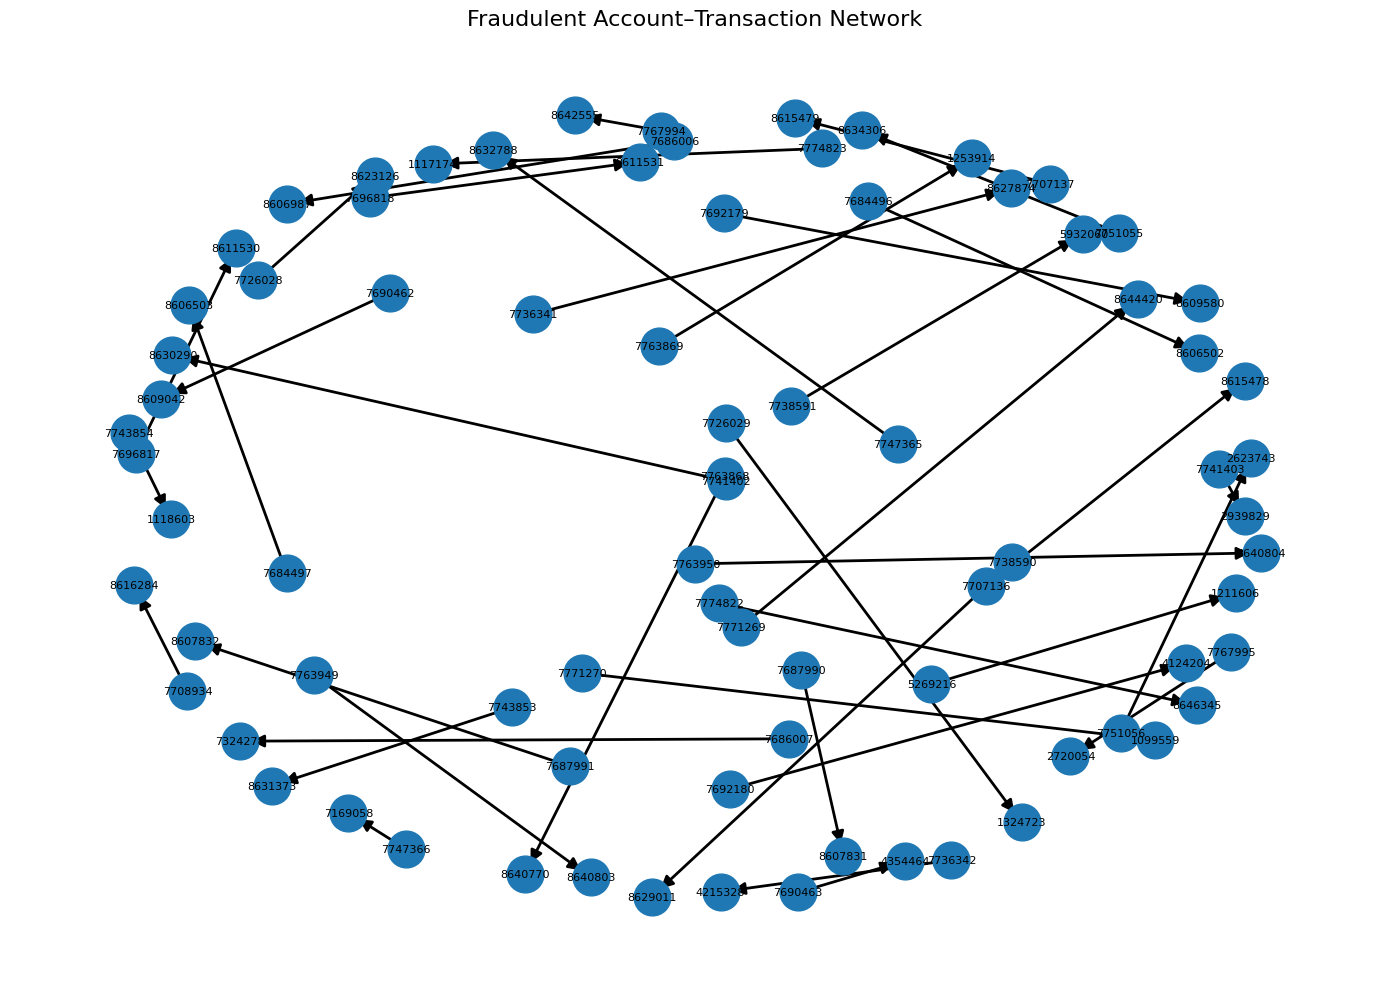


Visualization saved to:
/content/graph_data/member2_fraud_transaction_graph.png


In [ ]:
# ============================================================
# MEMBER 2 - VISUAL 1
# ACTUAL ACCOUNT-TRANSACTION GRAPH
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

print("=" * 60)
print("MEMBER 2 - ACCOUNT TRANSACTION GRAPH")
print("=" * 60)

# ------------------------------------------------------------
# 1. Test partitions
# ------------------------------------------------------------

test_files = [
    "/content/graph_data/test/edge_part_6.npz",
    "/content/graph_data/test/edge_part_7.npz"
]

# ------------------------------------------------------------
# 2. Collect a manageable number of fraudulent transactions
# ------------------------------------------------------------

fraud_edges = []

for file_path in test_files:

    data = np.load(file_path)

    source = data["source"]
    destination = data["destination"]
    labels = data["labels"]

    fraud_idx = np.where(labels == 1)[0]

    print(
        Path(file_path).name,
        "fraud transactions:",
        len(fraud_idx)
    )

    for idx in fraud_idx:
        fraud_edges.append(
            (
                int(source[idx]),
                int(destination[idx])
            )
        )

print("\nTotal fraud transactions available:", len(fraud_edges))

# ------------------------------------------------------------
# 3. Select a small subset for visualization
# ------------------------------------------------------------

MAX_FRAUD_EDGES = 40

fraud_edges = fraud_edges[:MAX_FRAUD_EDGES]

print("Fraud edges selected for visualization:", len(fraud_edges))

# ------------------------------------------------------------
# 4. Build graph
# ------------------------------------------------------------

G = nx.DiGraph()

for source, destination in fraud_edges:

    G.add_edge(
        source,
        destination,
        fraud=True
    )

print("\nGraph statistics")
print("-" * 40)
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# ------------------------------------------------------------
# 5. Draw graph
# ------------------------------------------------------------

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.2,
    iterations=100
)

# Draw nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=700
)

# Draw directed edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18,
    width=2
)

# Draw labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=8
)

plt.title(
    "Fraudulent Account–Transaction Network",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

# ------------------------------------------------------------
# 6. Save figure
# ------------------------------------------------------------

output_path = "/content/graph_data/member2_fraud_transaction_graph.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(output_path)

Node = account
Directed edge = transaction
Arrow direction = sender → receiver

The displayed transactions are actual fraudulent transactions from test data

Suspicious Account Network

SUSPICIOUS ACCOUNT CONNECTION NETWORK
edge_part_6.npz → 847453 edges
edge_part_7.npz → 71164 edges

Total edges : 918617
Fraud edges : 4006
Fraud among top 150 : 150
Graph nodes: 300
Graph edges: 150


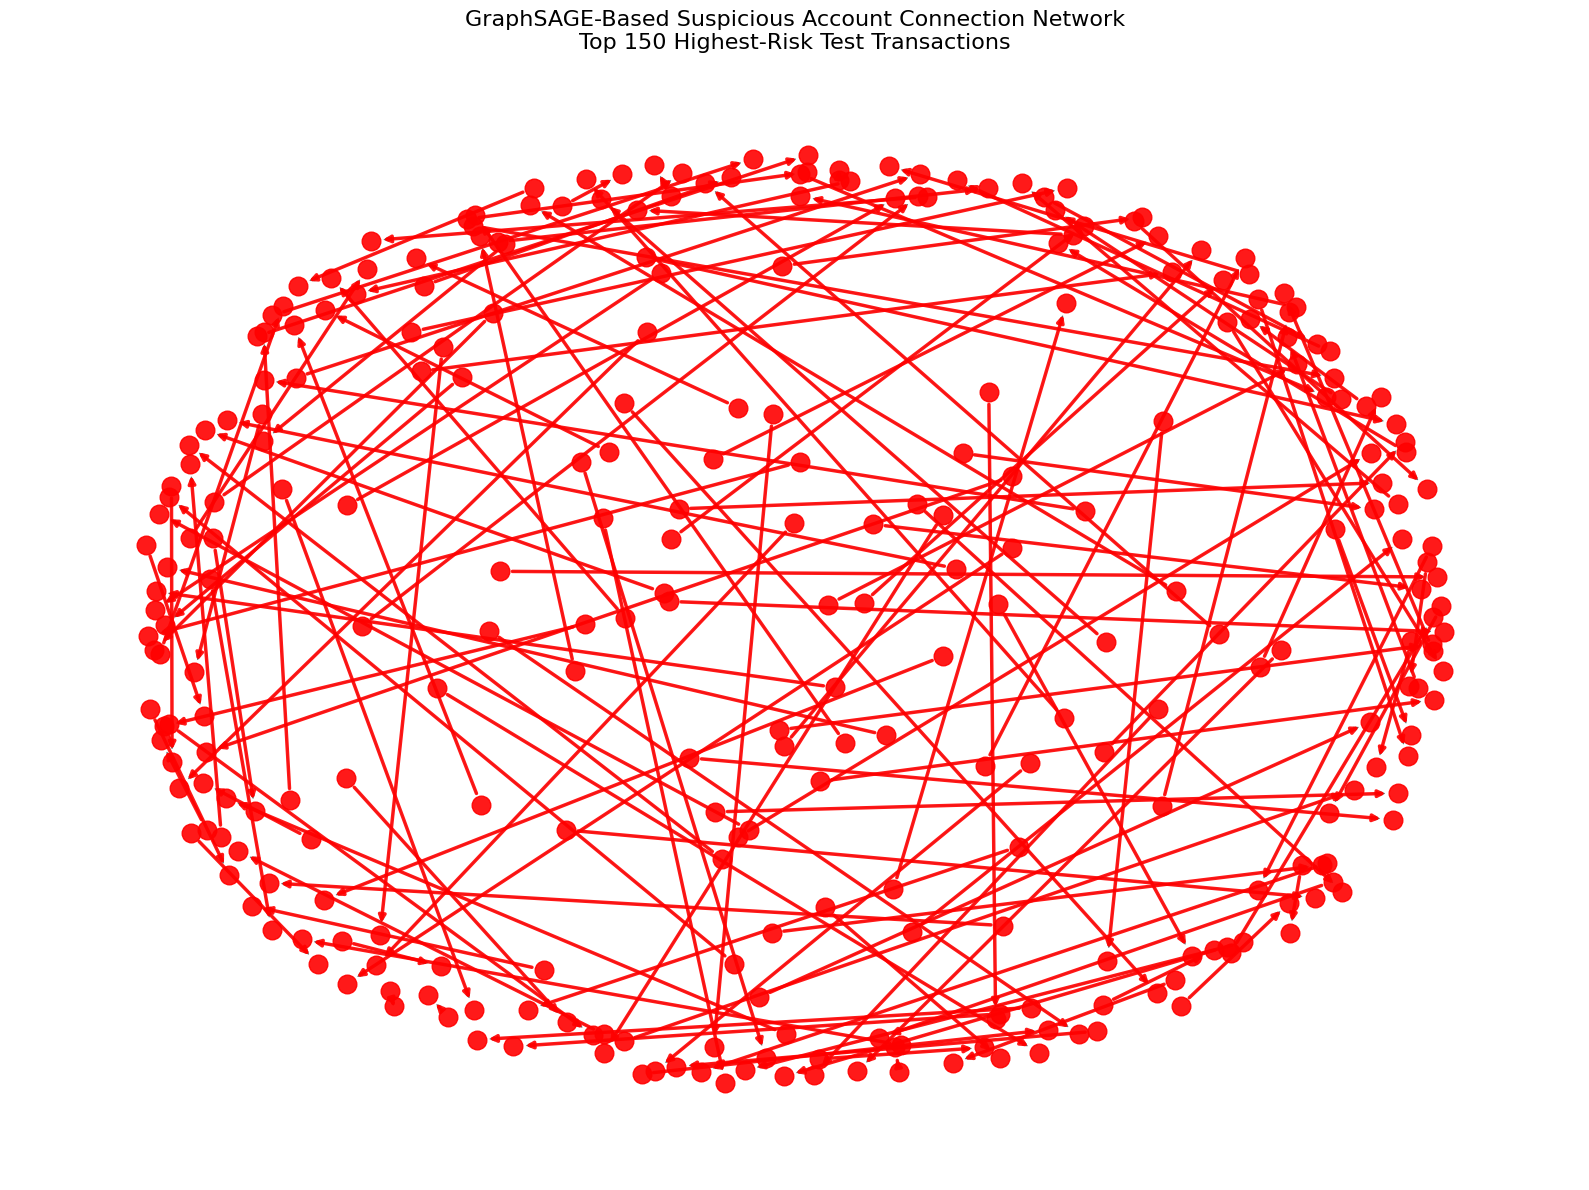

Saved: /content/graph_data/visual3_suspicious_network.png


In [ ]:
# ============================================================
# VISUAL  - SUSPICIOUS ACCOUNT CONNECTION NETWORK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os

print("=" * 60)
print("SUSPICIOUS ACCOUNT CONNECTION NETWORK")
print("=" * 60)

test_files = [
    "/content/graph_data/test/edge_part_6.npz",
    "/content/graph_data/test/edge_part_7.npz"
]

all_sources = []
all_destinations = []
all_labels = []

for file in test_files:

    data = np.load(file)

    all_sources.append(data["source"])
    all_destinations.append(data["destination"])
    all_labels.append(data["labels"])

    print(
        os.path.basename(file),
        "→",
        len(data["source"]),
        "edges"
    )

all_sources = np.concatenate(all_sources)
all_destinations = np.concatenate(all_destinations)
all_labels = np.concatenate(all_labels)

print("\nTotal edges :", len(all_sources))
print("Fraud edges :", int(all_labels.sum()))

# ------------------------------------------------------------
# Find probability variable
# ------------------------------------------------------------

if "test_probs" in globals():

    probs = np.asarray(test_probs)

elif "test_probabilities" in globals():

    probs = np.asarray(test_probabilities)

elif "test_predictions" in globals():

    probs = np.asarray(test_predictions)

else:

    raise NameError(
        "Test probability variable not found. "
        "Use the probability variable created during final test inference."
    )

assert len(probs) == len(all_sources)

# ------------------------------------------------------------
# Select highest-risk transactions
# ------------------------------------------------------------

TOP_K = 150

top_indices = np.argsort(probs)[-TOP_K:][::-1]

top_sources = all_sources[top_indices]
top_destinations = all_destinations[top_indices]
top_probs = probs[top_indices]
top_labels = all_labels[top_indices]

print(
    "Fraud among top",
    TOP_K,
    ":",
    int(top_labels.sum())
)

# ------------------------------------------------------------
# Build graph
# ------------------------------------------------------------

G = nx.DiGraph()

for src, dst, prob, label in zip(
    top_sources,
    top_destinations,
    top_probs,
    top_labels
):

    G.add_edge(
        int(src),
        int(dst),
        probability=float(prob),
        fraud=int(label)
    )

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8,
    iterations=80
)

# ------------------------------------------------------------
# Fraud-related nodes
# ------------------------------------------------------------

fraud_nodes = set()

for u, v, data in G.edges(data=True):

    if data["fraud"] == 1:

        fraud_nodes.add(u)
        fraud_nodes.add(v)

normal_nodes = set(G.nodes()) - fraud_nodes

# ------------------------------------------------------------
# Draw normal nodes
# ------------------------------------------------------------

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=list(normal_nodes),
    node_size=70,
    alpha=0.6
)

# ------------------------------------------------------------
# Draw fraud-related nodes
# ------------------------------------------------------------

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=list(fraud_nodes),
    node_size=180,
    node_color="red",
    alpha=0.9
)

# ------------------------------------------------------------
# Draw edges
# ------------------------------------------------------------

nx.draw_networkx_edges(
    G,
    pos,
    width=0.8,
    alpha=0.3,
    arrows=True,
    arrowsize=8
)

# ------------------------------------------------------------
# Highlight actual fraud edges
# ------------------------------------------------------------

fraud_edges = [
    (u, v)
    for u, v, data in G.edges(data=True)
    if data["fraud"] == 1
]

if fraud_edges:

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=fraud_edges,
        width=2.5,
        edge_color="red",
        alpha=0.9,
        arrows=True,
        arrowsize=10
    )
plt.title(
    "GraphSAGE-Based Suspicious Account Connection Network\n"
    "Top 150 Highest-Risk Test Transactions",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

path = "/content/graph_data/visual3_suspicious_network.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

Confusion Matrix

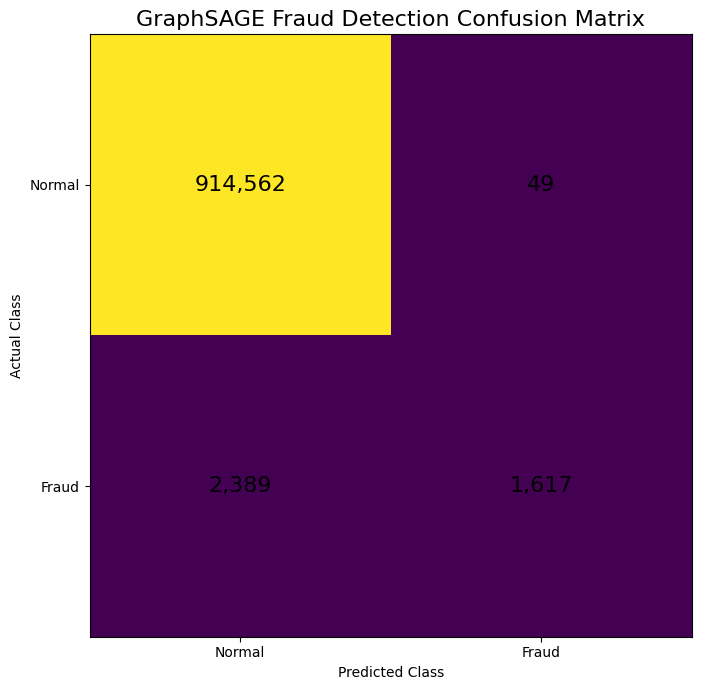

Saved: /content/graph_data/visual4_confusion_matrix.png


In [ ]:
# ============================================================
# VISUAL  - CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

cm = np.array([
    [914562, 49],
    [2389, 1617]
])

plt.figure(figsize=(8, 7))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "GraphSAGE Fraud Detection Confusion Matrix",
    fontsize=16
)

# Add numbers
for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()

path = "/content/graph_data/visual4_confusion_matrix.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

This confirms the model is highly precise (97%) but conservative — it rarely mislabels a genuine transaction as fraud, but it still misses about 60% of actual frauds (low recall ~40%).



ROC Curve

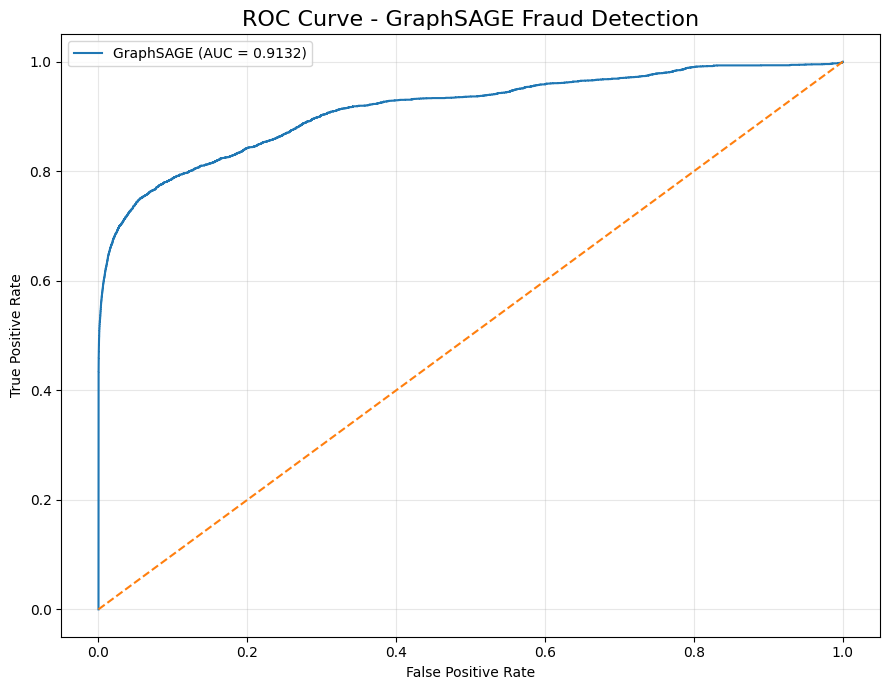

ROC-AUC: 0.9131704802378813
Saved: /content/graph_data/visual5_roc_curve.png


In [ ]:
# ============================================================
# VISUAL  - ROC CURVE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ------------------------------------------------------------
# Find probabilities
# ------------------------------------------------------------

if "test_probs" in globals():

    probs = np.asarray(test_probs)

elif "test_probabilities" in globals():

    probs = np.asarray(test_probabilities)

elif "test_predictions" in globals():

    probs = np.asarray(test_predictions)

else:

    raise NameError(
        "Test probability variable not found."
    )

# ------------------------------------------------------------
# Load labels
# ------------------------------------------------------------

test_files = [
    "/content/graph_data/test/edge_part_6.npz",
    "/content/graph_data/test/edge_part_7.npz"
]

labels = []

for file in test_files:

    data = np.load(file)
    labels.append(data["labels"])

labels = np.concatenate(labels)

# ------------------------------------------------------------
# ROC
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    labels,
    probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    label=f"GraphSAGE (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - GraphSAGE Fraud Detection",
    fontsize=16
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

path = "/content/graph_data/visual5_roc_curve.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", roc_auc)
print("Saved:", path)

Precision–Recall Curve

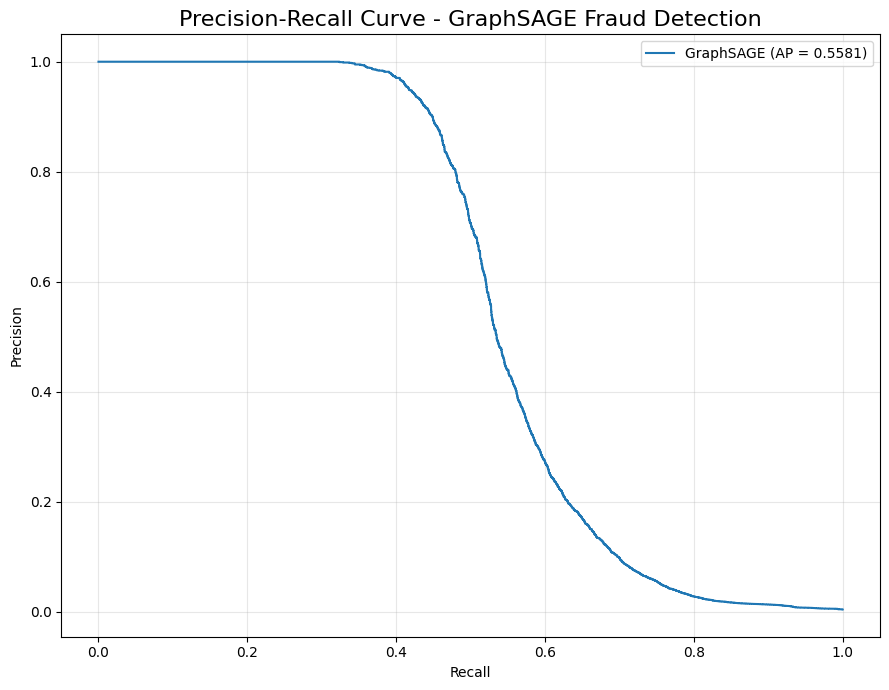

PR-AUC: 0.5580950484895786
Saved: /content/graph_data/visual6_precision_recall.png


In [ ]:
# ============================================================
# VISUAL  - PRECISION RECALL CURVE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# Find probabilities
# ------------------------------------------------------------

if "test_probs" in globals():

    probs = np.asarray(test_probs)

elif "test_probabilities" in globals():

    probs = np.asarray(test_probabilities)

elif "test_predictions" in globals():

    probs = np.asarray(test_predictions)

else:

    raise NameError(
        "Test probability variable not found."
    )

# ------------------------------------------------------------
# Load labels
# ------------------------------------------------------------

test_files = [
    "/content/graph_data/test/edge_part_6.npz",
    "/content/graph_data/test/edge_part_7.npz"
]

labels = []

for file in test_files:

    data = np.load(file)
    labels.append(data["labels"])

labels = np.concatenate(labels)

# ------------------------------------------------------------
# Precision-Recall
# ------------------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    labels,
    probs
)

pr_auc = average_precision_score(
    labels,
    probs
)

plt.figure(figsize=(9, 7))

plt.plot(
    recall,
    precision,
    label=f"GraphSAGE (AP = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve - GraphSAGE Fraud Detection",
    fontsize=16
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

path = "/content/graph_data/visual6_precision_recall.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR-AUC:", pr_auc)
print("Saved:", path)

Member:3

In [ ]:
import os

print("Contents of /content/drive:")
print(os.listdir("/content/drive"))

Contents of /content/drive:
['MyDrive']


In [ ]:
import os

for mount in ["/content/drive", "/content/gdrive"]:
    print("\n" + "=" * 60)
    print(mount)

    if os.path.exists(mount):
        print("Exists:", True)
        print("Contents:", os.listdir(mount)[:20])
    else:
        print("Does not exist")


/content/drive
Exists: True
Contents: ['MyDrive']

/content/gdrive
Exists: True
Contents: ['MyDrive']


In [ ]:
import shutil

source = "/content/ForensicFusion_Member1_Final.parquet"
destination = "/content/gdrive/MyDrive/ForensicFusion_Member1_Final.parquet"

shutil.copy2(source, destination)

print("Member 1 file copied to Google Drive successfully!")
print(destination)

Member 1 file copied to Google Drive successfully!
/content/gdrive/MyDrive/ForensicFusion_Member1_Final.parquet


In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

member1 = pd.read_parquet(
    "/content/gdrive/MyDrive/ForensicFusion_Member1_Final.parquet"
)

print("Member 1 loaded!")
print("Shape:", member1.shape)

Member 1 loaded!
Shape: (6362620, 30)


In [ ]:
member2 = pd.read_csv(
    "/content/gdrive/MyDrive/ForensicFusion_Member2_test_predictions.csv"
)

print("Member 2 loaded!")
print("Shape:", member2.shape)
print(member2.head())

Member 2 loaded!
Shape: (918617, 6)
   source_node  destination_node  step  fraud_label  fraud_probability  \
0      7953920           8722509   398            1                1.0   
1      7953919           8722508   398            1                1.0   
2      9042261           9073886   742            1                1.0   
3      7954081           8722576   398            1                1.0   
4      9024420           1328083   692            1                1.0   

   predicted_fraud  
0                1  
1                1  
2                1  
3                1  
4                1  


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded.")

Libraries loaded.


In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
DRIVE_PATH = "/content/drive/MyDrive/ForensicFusion/"

In [ ]:
member1_path = DRIVE_PATH + "ForensicFusion_Member1_Final.parquet"

member1 = pd.read_parquet(member1_path)

print("Member 1 loaded successfully.")
print("Shape:", member1.shape)
print("Columns:", len(member1.columns))

Member 1 loaded successfully.
Shape: (6362620, 30)
Columns: 30


In [ ]:
from google.colab import drive
import pandas as pd
import os

# Mount Google Drive
drive.mount('/content/gdrive')

# Exact file path
member2_path = "/content/gdrive/MyDrive/ForensicFusion/ForensicFusion_Member2_test_predictions.csv"

# Check file
print("File exists:", os.path.exists(member2_path))

# Load
member2 = pd.read_csv(member2_path)

print("Member 2 loaded!")
print("Shape:", member2.shape)

display(member2.head())

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
File exists: True
Member 2 loaded!
Shape: (918617, 6)


,source_node,destination_node,step,fraud_label,fraud_probability,predicted_fraud
0,7953920,8722509,398,1,1.0,1
1,7953919,8722508,398,1,1.0,1
2,9042261,9073886,742,1,1.0,1
3,7954081,8722576,398,1,1.0,1
4,9024420,1328083,692,1,1.0,1


In [ ]:
print("========== MEMBER 1 ==========")
print(member1.shape)
print(member1.columns.tolist())

print("\n========== MEMBER 2 ==========")
print(member2.shape)
print(member2.columns.tolist())

========== MEMBER 1 ==========
(6362620, 30)
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'origBalanceChange', 'destBalanceChange', 'origBalanceError', 'destBalanceError', 'type_encoded', 'BenfordTypeScore', 'time_window_25', 'BenfordTimeScore_25', 'sender_transaction_count', 'receiver_transaction_count', 'sender_avg_amount', 'receiver_avg_amount', 'sender_amount_deviation', 'receiver_amount_deviation', 'sender_window_velocity', 'receiver_window_velocity', 'BenfordTypeScore_Norm', 'BenfordTimeScore_Norm', 'BenfordForensicScore']

========== MEMBER 2 ==========
(918617, 6)
['source_node', 'destination_node', 'step', 'fraud_label', 'fraud_probability', 'predicted_fraud']


In [ ]:
member1_test = member1[
    member1["step"] > 378
].copy()

member1_test.reset_index(
    drop=True,
    inplace=True
)

print("Member 1 test shape:", member1_test.shape)

print(
    "Fraud transactions:",
    member1_test["isFraud"].sum()
)

Member 1 test shape: (918617, 30)
Fraud transactions: 4006


In [ ]:
gnn = member2.copy()

print("GNN rows:", len(gnn))
print("GNN fraud labels:", gnn["fraud_label"].sum())
print("GNN predicted fraud:", gnn["predicted_fraud"].sum())

GNN rows: 918617
GNN fraud labels: 4006
GNN predicted fraud: 1666


In [ ]:
print("Member 2 test shape:", member2.shape)

print(
    "Member 2 fraud:",
    member2["fraud_label"].sum()
)

print(
    "Member 2 predicted fraud:",
    member2["predicted_fraud"].sum()
)

Member 2 test shape: (918617, 6)
Member 2 fraud: 4006
Member 2 predicted fraud: 1666


In [ ]:
member2["fraud_probability"].values

array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, ..., 6.5977660e-28,
       5.2373325e-28, 2.3666003e-29])

Create GNN temporal evidence

In [ ]:
gnn_step = (
    gnn.groupby("step")
    .agg(
        GNN_MeanScore=("fraud_probability", "mean"),
        GNN_MaxScore=("fraud_probability", "max"),
        GNN_FraudRate=("predicted_fraud", "mean"),
        GNN_FraudCount=("predicted_fraud", "sum")
    )
    .reset_index()
)

print(gnn_step.head())

   step  GNN_MeanScore  GNN_MaxScore  GNN_FraudRate  GNN_FraudCount
0   379       0.067136      1.000000       0.000168               7
1   380       0.065511      1.000000       0.000133               5
2   381       0.061900      0.994313       0.000134               2
3   382       0.057792      0.999819       0.000338               4
4   383       0.056365      1.000000       0.000767               6


Create a stronger GNN temporal score

In [ ]:
gnn_step["GNN_TemporalScore"] = (
    0.70 * gnn_step["GNN_MaxScore"] +
    0.30 * gnn_step["GNN_FraudRate"]
)

print(
    gnn_step[
        [
            "step",
            "GNN_MeanScore",
            "GNN_MaxScore",
            "GNN_FraudRate",
            "GNN_TemporalScore"
        ]
    ].head(20)
)

    step  GNN_MeanScore  GNN_MaxScore  GNN_FraudRate  GNN_TemporalScore
0    379       0.067136      1.000000       0.000168           0.700050
1    380       0.065511      1.000000       0.000133           0.700040
2    381       0.061900      0.994313       0.000134           0.696059
3    382       0.057792      0.999819       0.000338           0.699974
4    383       0.056365      1.000000       0.000767           0.700230
5    384       0.054035      0.999997       0.000557           0.700165
6    385       0.056073      0.992695       0.001409           0.695309
7    386       0.075279      1.000000       0.022117           0.706635
8    387       0.716815      1.000000       0.571429           0.871429
9    388       0.661560      1.000000       0.500000           0.850000
10   389       0.834366      1.000000       0.800000           0.940000
11   390       0.865158      1.000000       0.666667           0.900000
12   391       0.659506      1.000000       0.333333           0

Merge GNN evidence into Member 1

In [ ]:
fusion_data = member1_test.merge(
    gnn_step[
        [
            "step",
            "GNN_MeanScore",
            "GNN_MaxScore",
            "GNN_FraudRate",
            "GNN_TemporalScore"
        ]
    ],
    on="step",
    how="left"
)

print("Fusion shape:", fusion_data.shape)

Fusion shape: (918617, 34)


In [ ]:
print(
    "Missing GNN:",
    fusion_data["GNN_TemporalScore"].isna().sum()
)

Missing GNN: 0


Prepare Benford evidence

In [ ]:
print(
    fusion_data[
        [
            "BenfordTypeScore",
            "BenfordTimeScore_25",
            "BenfordForensicScore"
        ]
    ].describe()
)

       BenfordTypeScore  BenfordTimeScore_25  BenfordForensicScore
count     918617.000000        918617.000000         918617.000000
mean           0.016471             0.014998              0.567722
std            0.006898             0.001445              0.202976
min            0.005427             0.010543              0.127052
25%            0.009527             0.014232              0.388260
50%            0.022241             0.015715              0.670800
75%            0.022241             0.016294              0.753260
max            0.022844             0.020611              0.889107


Normalize Benford properly

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler_benford = MinMaxScaler()

fusion_data["BenfordEvidence"] = (
    scaler_benford.fit_transform(
        fusion_data[["BenfordForensicScore"]]
    ).ravel()
)

print(
    fusion_data["BenfordEvidence"].describe()
)

count    918617.000000
mean          0.578266
std           0.266354
min           0.000000
25%           0.342768
50%           0.713529
75%           0.821737
max           1.000000
Name: BenfordEvidence, dtype: float64


Create behavioral evidence

In [ ]:
fusion_data["BalanceAnomaly"] = (
    abs(fusion_data["origBalanceError"]) +
    abs(fusion_data["destBalanceError"])
)

print(
    fusion_data["BalanceAnomaly"].describe()
)

count    9.186170e+05
mean     2.645150e+05
std      4.836852e+05
min      0.000000e+00
25%      1.400819e+04
50%      7.908782e+04
75%      3.077871e+05
max      2.066495e+07
Name: BalanceAnomaly, dtype: float64


Convert balance anomaly into normalized evidence

In [ ]:
fusion_data["BehavioralEvidence"] = (
    fusion_data["BalanceAnomaly"]
    .rank(pct=True)
)

print(
    fusion_data["BehavioralEvidence"].describe()
)

count    918617.000000
mean          0.500001
std           0.288675
min           0.005815
25%           0.250001
50%           0.500001
75%           0.750000
max           1.000000
Name: BehavioralEvidence, dtype: float64


Create ForensicFusion score

In [ ]:
fusion_data["ForensicFusionScore"] = (

    0.65 * fusion_data["GNN_TemporalScore"]

    +

    0.20 * fusion_data["BenfordEvidence"]

    +

    0.15 * fusion_data["BehavioralEvidence"]
)

In [ ]:
print("========== SCORE COMPARISON ==========")

print(
    "GNN mean:",
    fusion_data["GNN_TemporalScore"].mean()
)

print(
    "Benford mean:",
    fusion_data["BenfordEvidence"].mean()
)

print(
    "Behavior mean:",
    fusion_data["BehavioralEvidence"].mean()
)

print(
    "Fusion mean:",
    fusion_data["ForensicFusionScore"].mean()
)

========== SCORE COMPARISON ==========
GNN mean: 0.6968573218151028
Benford mean: 0.5782656346238563
Behavior mean: 0.5000005442964804
Fusion mean: 0.6436104677490606


In [ ]:
print(
    fusion_data[
        [
            "GNN_TemporalScore",
            "BenfordEvidence",
            "BehavioralEvidence",
            "ForensicFusionScore",
            "isFraud"
        ]
    ].groupby("isFraud").mean()
)

         GNN_TemporalScore  BenfordEvidence  BehavioralEvidence  \
isFraud                                                           
0                 0.696585         0.578831            0.500483   
1                 0.759074         0.449289            0.389802   

         ForensicFusionScore  
isFraud                       
0                   0.643619  
1                   0.641726  


Distribution visualization

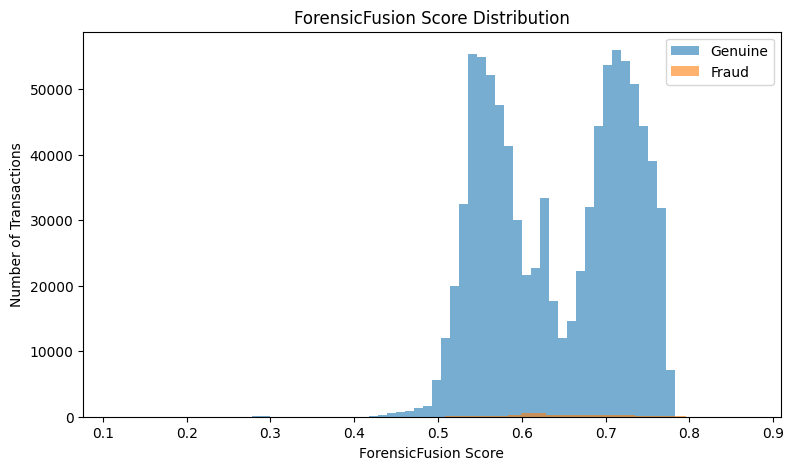

In [ ]:
plt.figure(figsize=(9,5))

plt.hist(
    fusion_data.loc[
        fusion_data["isFraud"] == 0,
        "ForensicFusionScore"
    ],
    bins=50,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    fusion_data.loc[
        fusion_data["isFraud"] == 1,
        "ForensicFusionScore"
    ],
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("ForensicFusion Score")
plt.ylabel("Number of Transactions")
plt.title("ForensicFusion Score Distribution")

plt.legend()

plt.show()

Precision-Recall evaluation

In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

y_true = fusion_data["isFraud"]

y_score = fusion_data["ForensicFusionScore"]

precision, recall, thresholds = (
    precision_recall_curve(
        y_true,
        y_score
    )
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    /
    (
        precision[:-1]
        +
        recall[:-1]
        +
        1e-10
    )
)

best_idx = np.argmax(f1_values)

fusion_threshold = thresholds[best_idx]

print("Fusion threshold:", fusion_threshold)
print("Best F1:", f1_values[best_idx])

Fusion threshold: 0.7779640425733177
Best F1: 0.043657530918569984


Generate fusion prediction

In [ ]:
fusion_data["FusionPrediction"] = (
    fusion_data["ForensicFusionScore"]
    >= fusion_threshold
).astype(int)

print(
    "Fusion predicted fraud:",
    fusion_data["FusionPrediction"].sum()
)

Fusion predicted fraud: 117


Final Fusion metrics

In [ ]:
fusion_precision = precision_score(
    y_true,
    fusion_data["FusionPrediction"],
    zero_division=0
)

fusion_recall = recall_score(
    y_true,
    fusion_data["FusionPrediction"],
    zero_division=0
)

fusion_f1 = f1_score(
    y_true,
    fusion_data["FusionPrediction"],
    zero_division=0
)

fusion_roc_auc = roc_auc_score(
    y_true,
    y_score
)

fusion_pr_auc = average_precision_score(
    y_true,
    y_score
)

print("=" * 50)
print("FORENSICFUSION RESULTS")
print("=" * 50)

print("Precision :", round(fusion_precision, 4))
print("Recall    :", round(fusion_recall, 4))
print("F1 Score  :", round(fusion_f1, 4))
print("ROC-AUC   :", round(fusion_roc_auc, 4))
print("PR-AUC    :", round(fusion_pr_auc, 4))

FORENSICFUSION RESULTS
Precision : 0.7692
Recall    : 0.0225
F1 Score  : 0.0437
ROC-AUC   : 0.5064
PR-AUC    : 0.0267


In [ ]:
gnn_precision = precision_score(
    gnn["fraud_label"],
    gnn["predicted_fraud"],
    zero_division=0
)

gnn_recall = recall_score(
    gnn["fraud_label"],
    gnn["predicted_fraud"],
    zero_division=0
)

gnn_f1 = f1_score(
    gnn["fraud_label"],
    gnn["predicted_fraud"],
    zero_division=0
)

gnn_roc_auc = roc_auc_score(
    gnn["fraud_label"],
    gnn["fraud_probability"]
)

gnn_pr_auc = average_precision_score(
    gnn["fraud_label"],
    gnn["fraud_probability"]
)

comparison = pd.DataFrame({

    "Model": [
        "Member 2 GNN",
        "ForensicFusion"
    ],

    "Precision": [
        gnn_precision,
        fusion_precision
    ],

    "Recall": [
        gnn_recall,
        fusion_recall
    ],

    "F1": [
        gnn_f1,
        fusion_f1
    ],

    "ROC-AUC": [
        gnn_roc_auc,
        fusion_roc_auc
    ],

    "PR-AUC": [
        gnn_pr_auc,
        fusion_pr_auc
    ]
})

print(comparison)

            Model  Precision    Recall        F1   ROC-AUC    PR-AUC
0    Member 2 GNN   0.970588  0.403645  0.570169  0.913170  0.558095
1  ForensicFusion   0.769231  0.022466  0.043658  0.506413  0.026744


In [ ]:
XAI: evidence contribution

In [ ]:
fusion_data["GNN_Contribution"] = (
    0.65 *
    fusion_data["GNN_TemporalScore"]
)

fusion_data["Benford_Contribution"] = (
    0.20 *
    fusion_data["BenfordEvidence"]
)

fusion_data["Behavioral_Contribution"] = (
    0.15 *
    fusion_data["BehavioralEvidence"]
)

In [ ]:
top_suspicious = (
    fusion_data
    .sort_values(
        "ForensicFusionScore",
        ascending=False
    )
    .head(20)
)

top_suspicious[
    [
        "step",
        "type",
        "amount",
        "nameOrig",
        "nameDest",
        "GNN_Contribution",
        "Benford_Contribution",
        "Behavioral_Contribution",
        "ForensicFusionScore",
        "isFraud"
    ]
]

,step,type,amount,nameOrig,nameDest,GNN_Contribution,Benford_Contribution,Behavioral_Contribution,ForensicFusionScore,isFraud
918571,740,TRANSFER,1755647.81,C507031767,C692082136,0.649965,0.073314,0.147764,0.871043,1
918569,740,TRANSFER,1312694.50,C1681615431,C492082350,0.649965,0.073314,0.144696,0.867975,1
918567,740,TRANSFER,748139.48,C1183186026,C1620658775,0.649965,0.073314,0.134127,0.857406,1
918570,740,CASH_OUT,1312694.50,C1078953751,C1920187579,0.649965,0.200000,0.000872,0.850837,1
918568,740,CASH_OUT,748139.48,C959562247,C1768725891,0.649965,0.200000,0.000872,0.850837,1
918572,740,CASH_OUT,1755647.81,C1724432558,C22170584,0.649965,0.200000,0.000872,0.850837,1
909929,708,TRANSFER,1735525.50,C944432695,C1069174246,0.649960,0.039046,0.147681,0.836687,1
909927,708,TRANSFER,1494146.93,C1328487364,C1043010515,0.649960,0.039046,0.146325,0.835332,1
852665,677,TRANSFER,10000000.00,C1709472240,C225746427,0.650000,0.033992,0.149990,0.833982,1
852667,677,TRANSFER,9295454.24,C1216463302,C1920599052,0.650000,0.033992,0.149972,0.833964,1


XAI visualization

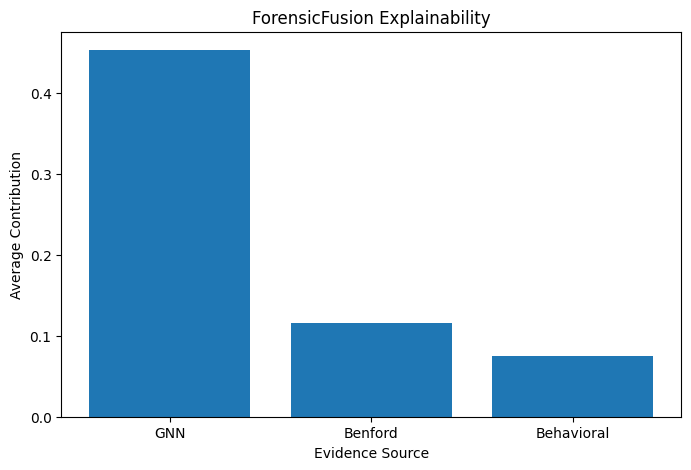

In [ ]:
xai_values = pd.DataFrame({
    "Evidence": [
        "GNN",
        "Benford",
        "Behavioral"
    ],
    "Contribution": [
        fusion_data["GNN_Contribution"].mean(),
        fusion_data["Benford_Contribution"].mean(),
        fusion_data["Behavioral_Contribution"].mean()
    ]
})

plt.figure(figsize=(8,5))

plt.bar(
    xai_values["Evidence"],
    xai_values["Contribution"]
)

plt.xlabel("Evidence Source")
plt.ylabel("Average Contribution")
plt.title(
    "ForensicFusion Explainability"
)

plt.show()

Confusion matrix

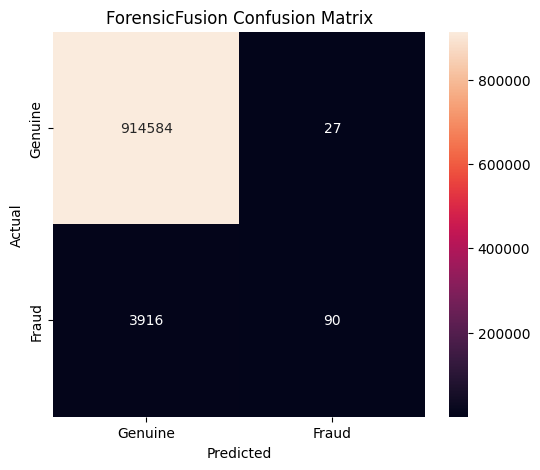

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    fusion_data["FusionPrediction"]
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "ForensicFusion Confusion Matrix"
)

plt.show()

ROC curve

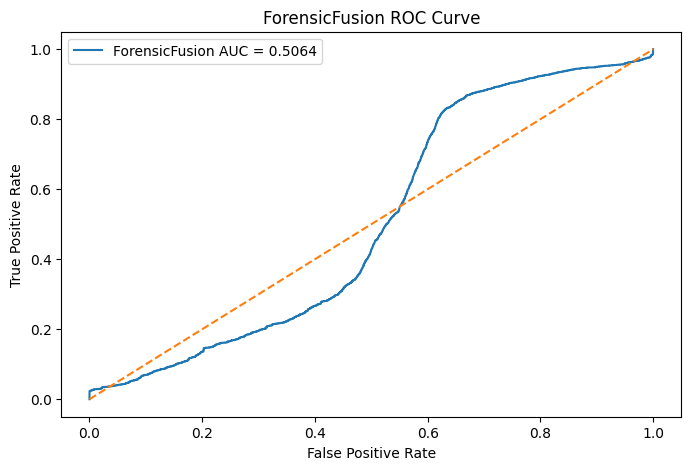

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(
    y_true,
    y_score
)

plt.figure(figsize=(8,5))

plt.plot(
    fpr,
    tpr,
    label=f"ForensicFusion AUC = {fusion_roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ForensicFusion ROC Curve"
)

plt.legend()

plt.show()

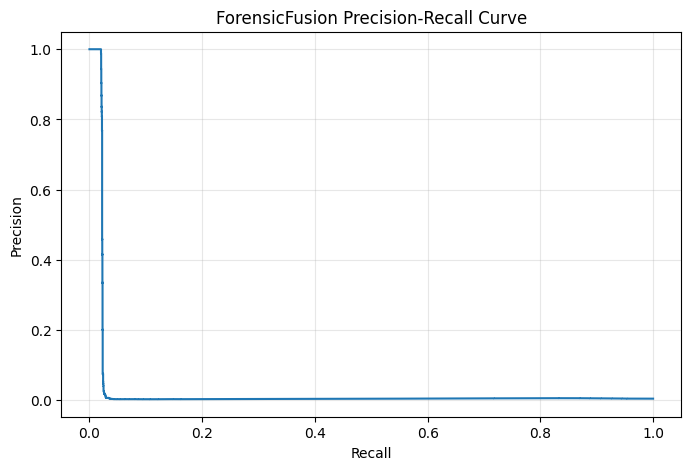

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "ForensicFusion Precision-Recall Curve"
)

plt.grid(alpha=0.3)

plt.show()

In [ ]:
gnn_only = fusion_data["GNN_TemporalScore"]
gnn_benford = (
    0.75 * fusion_data["GNN_TemporalScore"]
    +
    0.25 * fusion_data["BenfordEvidence"]
)
gnn_behavior = (
    0.80 * fusion_data["GNN_TemporalScore"]
    +
    0.20 * fusion_data["BehavioralEvidence"]
)
full_fusion = (
    fusion_data["ForensicFusionScore"]
)



ablation_results = []

scores = {
    "GNN Only": gnn_only,
    "GNN + Benford": gnn_benford,
    "GNN + Behavioral": gnn_behavior,
    "Full ForensicFusion": full_fusion
}

for name, score in scores.items():

    auc = roc_auc_score(
        y_true,
        score
    )

    pr_auc = average_precision_score(
        y_true,
        score
    )

    ablation_results.append([
        name,
        auc,
        pr_auc
    ])

ablation_df = pd.DataFrame(
    ablation_results,
    columns=[
        "Model",
        "ROC_AUC",
        "PR_AUC"
    ]
)

print(ablation_df)

                 Model   ROC_AUC    PR_AUC
0             GNN Only  0.835122  0.574024
1        GNN + Benford  0.522626  0.267834
2     GNN + Behavioral  0.569645  0.245019
3  Full ForensicFusion  0.506413  0.026744


.........................................Member -3..............................................



In [ ]:
from google.colab import drive

drive.flush_and_unmount()

Drive not mounted, so nothing to flush and unmount.


In [ ]:
!rm -rf /content/drive

In [ ]:
!mkdir -p /content/drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print("MyDrive exists:",
      os.path.exists("/content/drive/MyDrive"))

print("\nMy Drive contents:")

for item in os.listdir("/content/drive/MyDrive"):
    print(repr(item))

MyDrive exists: True

My Drive contents:
'Document from Madhavireddy.pdf'
'Colab Notebooks'
'Part 1.1 Accounting Notes.gdoc'
'23MIA1135 IPS.docx'
'23MIA1135 IPS.gdoc'
'IPS-6.gdoc'
'32 23MIA1075 R Lang.R.gdoc'
'23MIA1135 L.Madhavi.pdf'
'DigitalImage'
'ML'
'BDF report.pdf'
'Lokireddy Madhavi Resume (1).pdf'
'Lokireddy Madhavi Resume.pdf'
'IOT Project Title.gdoc'
'Laparoscopic Surgery Dataset Details.gsheet'
'Finance Project.docx'
'DL'
'Document from Madhavi  Reddy'
'ForensicFusion_Member1_Final.parquet'
'ForensicFusion'


In [ ]:
import os
import gc
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import networkx as nx

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

import shap

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
import os
import pandas as pd

print("=" * 70)
print("MEMBER 3 - NETWORK RISK ANALYSIS")
print("=" * 70)

PREDICTION_FILE = "/content/drive/MyDrive/ForensicFusion/ForensicFusion_Member2_test_predictions.csv"

ACCOUNT_FILE = "/content/drive/MyDrive/ForensicFusion/ForensicFusion_Member2_suspicious_accounts.csv"

THRESHOLD = 0.98

print("Prediction file:", PREDICTION_FILE)
print("Account file   :", ACCOUNT_FILE)

print("\nChecking files...")

print("Prediction exists:", os.path.exists(PREDICTION_FILE))
print("Account exists   :", os.path.exists(ACCOUNT_FILE))

if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTION_FILE}"
    )

if not os.path.exists(ACCOUNT_FILE):
    raise FileNotFoundError(
        f"Account file not found:\n{ACCOUNT_FILE}"
    )

pred_df = pd.read_csv(PREDICTION_FILE)
account_df = pd.read_csv(ACCOUNT_FILE)

print("\nLoaded successfully.")

print("Prediction shape:", pred_df.shape)
print("Account shape   :", account_df.shape)

print("\nPrediction columns:")
print(pred_df.columns.tolist())

print("\nAccount columns:")
print(account_df.columns.tolist())

print("=" * 80)
print("MEMBER 2 PREDICTION DATA")
print("=" * 80)

print("Shape:", pred_df.shape)
print("\nColumns:")
print(pred_df.columns.tolist())

display(pred_df.head())

MEMBER 3 - NETWORK RISK ANALYSIS
Prediction file: /content/drive/MyDrive/ForensicFusion/ForensicFusion_Member2_test_predictions.csv
Account file   : /content/drive/MyDrive/ForensicFusion/ForensicFusion_Member2_suspicious_accounts.csv

Checking files...
Prediction exists: True
Account exists   : True

Loaded successfully.
Prediction shape: (918617, 6)
Account shape   : (1608847, 7)

Prediction columns:
['source_node', 'destination_node', 'step', 'fraud_label', 'fraud_probability', 'predicted_fraud']

Account columns:
['account', 'transaction_count', 'max_fraud_probability', 'mean_fraud_probability', 'predicted_fraud_count', 'actual_fraud_count', 'suspiciousness_score']
MEMBER 2 PREDICTION DATA
Shape: (918617, 6)

Columns:
['source_node', 'destination_node', 'step', 'fraud_label', 'fraud_probability', 'predicted_fraud']


,source_node,destination_node,step,fraud_label,fraud_probability,predicted_fraud
0,7953920,8722509,398,1,1.0,1
1,7953919,8722508,398,1,1.0,1
2,9042261,9073886,742,1,1.0,1
3,7954081,8722576,398,1,1.0,1
4,9024420,1328083,692,1,1.0,1


In [ ]:
def find_column(df, candidates, required=True):
    lower_map = {c.lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    if required:
        raise ValueError(
            f"Could not find any of {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


SOURCE_COL = find_column(
    pred_df,
    ["source_node", "source", "src", "sender", "from_node"]
)

DEST_COL = find_column(
    pred_df,
    ["destination_node", "destination", "dst", "receiver", "to_node"]
)

PROB_COL = find_column(
    pred_df,
    ["fraud_probability", "probability", "fraud_prob", "prediction_probability"]
)

LABEL_COL = find_column(
    pred_df,
    ["fraud_label", "label", "is_fraud", "target"]
)

M2_PRED_COL = find_column(
    pred_df,
    ["predicted_fraud", "prediction", "predicted_label"]
)

STEP_COL = find_column(
    pred_df,
    ["step", "time_step", "timestamp_step"],
    required=False
)

print("Source column       :", SOURCE_COL)
print("Destination column  :", DEST_COL)
print("Probability column  :", PROB_COL)
print("Label column        :", LABEL_COL)
print("M2 prediction       :", M2_PRED_COL)
print("Step column         :", STEP_COL)

Source column       : source_node
Destination column  : destination_node
Probability column  : fraud_probability
Label column        : fraud_label
M2 prediction       : predicted_fraud
Step column         : step


Basic validation

In [ ]:
print("=" * 80)
print("MEMBER 2 DATA VALIDATION")
print("=" * 80)

print("Transactions:", len(pred_df))

print(
    "Fraud labels:",
    int(pred_df[LABEL_COL].sum())
)

print(
    "Predicted fraud:",
    int(pred_df[M2_PRED_COL].sum())
)

print(
    "Fraud probability min:",
    pred_df[PROB_COL].min()
)

print(
    "Fraud probability max:",
    pred_df[PROB_COL].max()
)

print(
    "Fraud probability mean:",
    pred_df[PROB_COL].mean()
)

print("\nMissing values:")
print(pred_df[[SOURCE_COL, DEST_COL, PROB_COL, LABEL_COL]].isna().sum())

MEMBER 2 DATA VALIDATION
Transactions: 918617
Fraud labels: 4006
Predicted fraud: 1666
Fraud probability min: 2.3666003e-29
Fraud probability max: 1.0
Fraud probability mean: 0.05753367656684194

Missing values:
source_node          0
destination_node     0
fraud_probability    0
fraud_label          0
dtype: int64


Recalculate Member 2 predictions

In [ ]:
pred_df["member2_pred_recalculated"] = (
    pred_df[PROB_COL] >= MEMBER2_THRESHOLD
).astype(int)

difference = (
    pred_df["member2_pred_recalculated"]
    != pred_df[M2_PRED_COL].astype(int)
).sum()

print("=" * 80)
print("MEMBER 2 THRESHOLD CHECK")
print("=" * 80)

print("Configured threshold:", MEMBER2_THRESHOLD)
print("Stored predictions  :", int(pred_df[M2_PRED_COL].sum()))
print("Recalculated        :", int(pred_df["member2_pred_recalculated"].sum()))
print("Differences         :", difference)

if difference == 0:
    print("✓ Member 2 predictions are consistent.")
else:
    print("WARNING: Stored predictions differ from threshold calculation.")

MEMBER 2 THRESHOLD CHECK
Configured threshold: 0.98
Stored predictions  : 1666
Recalculated        : 1666
Differences         : 0
✓ Member 2 predictions are consistent.


Build the transaction network

In [ ]:
network_df = pred_df[
    [SOURCE_COL, DEST_COL, PROB_COL, LABEL_COL]
].copy()

network_df.columns = [
    "source",
    "destination",
    "member2_probability",
    "fraud_label"
]

network_df["member2_probability"] = pd.to_numeric(
    network_df["member2_probability"],
    errors="coerce"
).fillna(0)

network_df["fraud_label"] = pd.to_numeric(
    network_df["fraud_label"],
    errors="coerce"
).fillna(0).astype(int)

print("=" * 80)
print("TRANSACTION NETWORK")
print("=" * 80)

print("Transactions :", len(network_df))
print("Unique source accounts :", network_df["source"].nunique())
print("Unique destination accounts :", network_df["destination"].nunique())

unique_accounts = pd.unique(
    pd.concat([
        network_df["source"],
        network_df["destination"]
    ])
)

print("Unique accounts :", len(unique_accounts))

TRANSACTION NETWORK
Transactions : 918617
Unique source accounts : 918421
Unique destination accounts : 690570
Unique accounts : 1608847


Calculate transaction-level network features

In [ ]:
M2_SUSPICIOUS = (
    network_df["member2_probability"] >= MEMBER2_THRESHOLD
).astype(int)

network_df["member2_suspicious"] = M2_SUSPICIOUS

# ---------------------------------------------------------
# SOURCE ACCOUNT STATISTICS
# ---------------------------------------------------------

source_stats = network_df.groupby("source").agg(
    source_transaction_count=("destination", "count"),
    source_mean_risk=("member2_probability", "mean"),
    source_max_risk=("member2_probability", "max"),
    source_suspicious_count=("member2_suspicious", "sum")
).reset_index()

# ---------------------------------------------------------
# DESTINATION ACCOUNT STATISTICS
# ---------------------------------------------------------

destination_stats = network_df.groupby("destination").agg(
    destination_transaction_count=("source", "count"),
    destination_mean_risk=("member2_probability", "mean"),
    destination_max_risk=("member2_probability", "max"),
    destination_suspicious_count=("member2_suspicious", "sum")
).reset_index()

# ---------------------------------------------------------
# MERGE SOURCE INFORMATION
# ---------------------------------------------------------

network_df = network_df.merge(
    source_stats,
    on="source",
    how="left"
)

# ---------------------------------------------------------
# MERGE DESTINATION INFORMATION
# ---------------------------------------------------------

network_df = network_df.merge(
    destination_stats,
    on="destination",
    how="left"
)

print("Network features created.")
display(network_df.head())

Network features created.


,source,destination,member2_probability,fraud_label,member2_suspicious,source_transaction_count,source_mean_risk,source_max_risk,source_suspicious_count,destination_transaction_count,destination_mean_risk,destination_max_risk,destination_suspicious_count
0,7953920,8722509,1.0,1,1,1,1.0,1.0,1,3,0.337545,1.0,1
1,7953919,8722508,1.0,1,1,1,1.0,1.0,1,1,1.000000,1.0,1
2,9042261,9073886,1.0,1,1,1,1.0,1.0,1,1,1.000000,1.0,1
3,7954081,8722576,1.0,1,1,1,1.0,1.0,1,2,0.510894,1.0,1
4,9024420,1328083,1.0,1,1,1,1.0,1.0,1,2,0.518000,1.0,1


Calculate network risk score

In [ ]:
def minmax_normalize(series):
    series = series.astype(float)

    min_val = series.min()
    max_val = series.max()

    if max_val == min_val:
        return pd.Series(
            np.zeros(len(series)),
            index=series.index
        )

    return (series - min_val) / (max_val - min_val)


network_df["source_activity_risk"] = minmax_normalize(
    network_df["source_transaction_count"]
)

network_df["destination_activity_risk"] = minmax_normalize(
    network_df["destination_transaction_count"]
)

network_df["source_mean_risk_norm"] = minmax_normalize(
    network_df["source_mean_risk"]
)

network_df["destination_mean_risk_norm"] = minmax_normalize(
    network_df["destination_mean_risk"]
)

network_df["source_suspicious_norm"] = minmax_normalize(
    network_df["source_suspicious_count"]
)

network_df["destination_suspicious_norm"] = minmax_normalize(
    network_df["destination_suspicious_count"]
)

# ---------------------------------------------------------
# NETWORK RISK
# ---------------------------------------------------------

network_df["network_risk"] = (
    0.20 * network_df["source_activity_risk"] +
    0.20 * network_df["destination_activity_risk"] +
    0.20 * network_df["source_mean_risk_norm"] +
    0.20 * network_df["destination_mean_risk_norm"] +
    0.10 * network_df["source_suspicious_norm"] +
    0.10 * network_df["destination_suspicious_norm"]
)

network_df["network_risk"] = network_df["network_risk"].clip(0, 1)

print("=" * 80)
print("NETWORK RISK")
print("=" * 80)

print(network_df["network_risk"].describe())

NETWORK RISK
count    918617.000000
mean          0.041310
std           0.046273
min           0.000000
25%           0.013029
50%           0.022813
75%           0.058627
max           0.650305
Name: network_risk, dtype: float64


Perform the actual ForensicFusion

In [ ]:
network_df["fusion_score"] = (
    MEMBER2_WEIGHT * network_df["member2_probability"] +
    NETWORK_WEIGHT * network_df["network_risk"]
)

network_df["fusion_score"] = network_df["fusion_score"].clip(0, 1)

network_df["final_suspicious"] = (
    network_df["fusion_score"] >= FUSION_THRESHOLD
).astype(int)

print("=" * 80)
print("FORENSICFUSION")
print("=" * 80)

print("Member 2 weight :", MEMBER2_WEIGHT)
print("Network weight  :", NETWORK_WEIGHT)
print("Fusion threshold:", FUSION_THRESHOLD)

print(
    "Final suspicious transactions:",
    int(network_df["final_suspicious"].sum())
)

FORENSICFUSION
Member 2 weight : 0.7
Network weight  : 0.3
Fusion threshold: 0.77
Final suspicious transactions: 2001


find the best fusion threshold

In [ ]:
threshold_results = []

for threshold in np.arange(0.50, 0.996, 0.005):

    y_pred = (
        network_df["fusion_score"] >= threshold
    ).astype(int)

    precision = precision_score(
        network_df["fraud_label"],
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        network_df["fraud_label"],
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        network_df["fraud_label"],
        y_pred,
        zero_division=0
    )

    threshold_results.append([
        threshold,
        precision,
        recall,
        f1
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        "threshold",
        "precision",
        "recall",
        "f1"
    ]
)

best_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("=" * 80)
print("FUSION THRESHOLD ANALYSIS")
print("=" * 80)

display(threshold_df.sort_values("f1", ascending=False).head(10))

print("\nBest diagnostic threshold:")
print("Threshold :", best_row["threshold"])
print("Precision :", best_row["precision"])
print("Recall    :", best_row["recall"])
print("F1        :", best_row["f1"])

FUSION THRESHOLD ANALYSIS


,threshold,precision,recall,f1
51,0.755,0.850404,0.472541,0.607510
50,0.750,0.832390,0.477284,0.606695
52,0.760,0.866760,0.466051,0.606169
53,0.765,0.885522,0.459561,0.605094
49,0.745,0.814376,0.480779,0.604615
48,0.740,0.797054,0.486271,0.604031
54,0.770,0.903548,0.451323,0.601964
47,0.735,0.782574,0.488767,0.601721
55,0.775,0.916453,0.446331,0.600302
46,0.730,0.763636,0.492761,0.598999



Best diagnostic threshold:
Threshold : 0.7550000000000002
Precision : 0.8504043126684636
Recall    : 0.4725411882176735
F1        : 0.6075096277278562


Final fusion metrics

In [ ]:
y_true = network_df["fraud_label"].values
y_fusion = network_df["final_suspicious"].values
fusion_scores = network_df["fusion_score"].values

roc_auc = roc_auc_score(
    y_true,
    fusion_scores
)

pr_auc = average_precision_score(
    y_true,
    fusion_scores
)

accuracy = accuracy_score(
    y_true,
    y_fusion
)

precision = precision_score(
    y_true,
    y_fusion,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_fusion,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_fusion,
    zero_division=0
)

cm = confusion_matrix(
    y_true,
    y_fusion
)

print("=" * 80)
print("FINAL FORENSICFUSION PERFORMANCE")
print("=" * 80)

print(f"Fusion threshold : {FUSION_THRESHOLD:.4f}")
print(f"ROC-AUC          : {roc_auc:.6f}")
print(f"PR-AUC           : {pr_auc:.6f}")
print(f"Accuracy         : {accuracy:.6f}")
print(f"Precision        : {precision:.6f}")
print(f"Recall           : {recall:.6f}")
print(f"F1-score         : {f1:.6f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_fusion,
        target_names=["Normal", "Fraud"],
        digits=4,
        zero_division=0
    )
)

FINAL FORENSICFUSION PERFORMANCE
Fusion threshold : 0.7700
ROC-AUC          : 0.907182
PR-AUC           : 0.558865
Accuracy         : 0.997397
Precision        : 0.903548
Recall           : 0.451323
F1-score         : 0.601964

Confusion Matrix:
[[914418    193]
 [  2198   1808]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9976    0.9998    0.9987    914611
       Fraud     0.9035    0.4513    0.6020      4006

    accuracy                         0.9974    918617
   macro avg     0.9506    0.7256    0.8003    918617
weighted avg     0.9972    0.9974    0.9970    918617



Extract suspicious transactions

In [ ]:
suspicious_transactions = (
    network_df[
        network_df["final_suspicious"] == 1
    ]
    .sort_values(
        "fusion_score",
        ascending=False
    )
    .copy()
)

print("=" * 80)
print("FINAL SUSPICIOUS TRANSACTIONS")
print("=" * 80)

print(
    "Suspicious transactions:",
    len(suspicious_transactions)
)

display(
    suspicious_transactions[
        [
            "source",
            "destination",
            "member2_probability",
            "network_risk",
            "fusion_score",
            "fraud_label"
        ]
    ].head(20)
)

FINAL SUSPICIOUS TRANSACTIONS
Suspicious transactions: 2001


,source,destination,member2_probability,network_risk,fusion_score,fraud_label
786,8242306,8847675,0.999981,0.650305,0.895078,1
393,8239045,8846226,1.000000,0.576707,0.873012,1
406,8236776,8835662,1.000000,0.567928,0.870378,1
1433,8418917,8846226,0.992295,0.575167,0.867157,1
296,8432975,8933560,1.000000,0.550000,0.865000,1
295,8432976,8933561,1.000000,0.550000,0.865000,1
294,8432977,8933562,1.000000,0.550000,0.865000,1
292,8432979,8933563,1.000000,0.550000,0.865000,1
290,8215867,8835361,1.000000,0.550000,0.865000,1
289,8499383,8962702,1.000000,0.550000,0.865000,1


**Account-level risk**


aggregate the final fusion risk to accounts.

In [ ]:
source_accounts = network_df.groupby("source").agg(
    transaction_count=("destination", "count"),
    mean_member2_risk=("member2_probability", "mean"),
    max_member2_risk=("member2_probability", "max"),
    mean_network_risk=("network_risk", "mean"),
    max_network_risk=("network_risk", "max"),
    mean_fusion_risk=("fusion_score", "mean"),
    max_fusion_risk=("fusion_score", "max"),
    suspicious_transaction_count=("final_suspicious", "sum"),
    actual_fraud_count=("fraud_label", "sum")
).reset_index()

source_accounts.rename(
    columns={"source": "account"},
    inplace=True
)

destination_accounts = network_df.groupby("destination").agg(
    transaction_count=("source", "count"),
    mean_member2_risk=("member2_probability", "mean"),
    max_member2_risk=("member2_probability", "max"),
    mean_network_risk=("network_risk", "mean"),
    max_network_risk=("network_risk", "max"),
    mean_fusion_risk=("fusion_score", "mean"),
    max_fusion_risk=("fusion_score", "max"),
    suspicious_transaction_count=("final_suspicious", "sum"),
    actual_fraud_count=("fraud_label", "sum")
).reset_index()

destination_accounts.rename(
    columns={"destination": "account"},
    inplace=True
)

account_df = pd.concat(
    [source_accounts, destination_accounts],
    ignore_index=True
)

account_df = account_df.groupby("account").agg(
    transaction_count=("transaction_count", "sum"),
    mean_member2_risk=("mean_member2_risk", "mean"),
    max_member2_risk=("max_member2_risk", "max"),
    mean_network_risk=("mean_network_risk", "mean"),
    max_network_risk=("max_network_risk", "max"),
    mean_fusion_risk=("mean_fusion_risk", "mean"),
    max_fusion_risk=("max_fusion_risk", "max"),
    suspicious_transaction_count=("suspicious_transaction_count", "sum"),
    actual_fraud_count=("actual_fraud_count", "sum")
).reset_index()

print("=" * 80)
print("ACCOUNT RISK ANALYSIS")
print("=" * 80)

print("Unique accounts:", len(account_df))

ACCOUNT RISK ANALYSIS
Unique accounts: 1608847


Account suspiciousness score

In [ ]:
account_df["activity_norm"] = minmax_normalize(
    account_df["transaction_count"]
)

account_df["suspicious_activity_norm"] = minmax_normalize(
    account_df["suspicious_transaction_count"]
)

account_df["fusion_risk_norm"] = minmax_normalize(
    account_df["mean_fusion_risk"]
)

account_df["max_risk_norm"] = minmax_normalize(
    account_df["max_fusion_risk"]
)

account_df["suspiciousness_score"] = (
    0.30 * account_df["fusion_risk_norm"] +
    0.25 * account_df["max_risk_norm"] +
    0.25 * account_df["suspicious_activity_norm"] +
    0.20 * account_df["activity_norm"]
)

account_df["suspiciousness_score"] = (
    account_df["suspiciousness_score"].clip(0, 1)
)

# An account is considered suspicious if it has
# at least one final suspicious transaction.
account_df["final_suspicious_account"] = (
    account_df["suspicious_transaction_count"] > 0
).astype(int)

suspicious_accounts = (
    account_df[
        account_df["final_suspicious_account"] == 1
    ]
    .sort_values(
        "suspiciousness_score",
        ascending=False
    )
)

print("=" * 80)
print("FINAL SUSPICIOUS ACCOUNTS")
print("=" * 80)

print(
    "Suspicious accounts:",
    len(suspicious_accounts)
)

display(
    suspicious_accounts.head(20)
)

FINAL SUSPICIOUS ACCOUNTS
Suspicious accounts: 3999


,account,transaction_count,mean_member2_risk,max_member2_risk,mean_network_risk,max_network_risk,mean_fusion_risk,max_fusion_risk,suspicious_transaction_count,actual_fraud_count,activity_norm,suspicious_activity_norm,fusion_risk_norm,max_risk_norm,suspiciousness_score,final_suspicious_account
1370609,8835662,2,0.964640,1.000000,0.510856,0.567928,0.828505,0.870378,2,2,0.125,1.0,0.925623,0.972405,0.795788,1
1381173,8846226,4,0.508537,1.000000,0.428415,0.576707,0.484500,0.873012,2,2,0.375,1.0,0.541294,0.975347,0.731225,1
237020,7057604,5,0.417330,0.999686,0.336932,0.533403,0.393211,0.859801,2,1,0.500,1.0,0.439303,0.960587,0.721938,1
1382622,8847675,1,0.999981,0.999981,0.650305,0.650305,0.895078,0.895078,1,1,0.000,0.5,1.000000,1.000000,0.675000,1
847262,8239045,1,1.000000,1.000000,0.576707,0.576707,0.873012,0.873012,1,1,0.000,0.5,0.975347,0.975347,0.661441,1
844993,8236776,1,1.000000,1.000000,0.567928,0.567928,0.870378,0.870378,1,1,0.000,0.5,0.972405,0.972405,0.659823,1
1027134,8418917,1,0.992295,0.992295,0.575167,0.575167,0.867157,0.867157,1,1,0.000,0.5,0.968805,0.968805,0.657843,1
1101959,8493742,1,1.000000,1.000000,0.550000,0.550000,0.865000,0.865000,1,1,0.000,0.5,0.966396,0.966396,0.656518,1
1107600,8499383,1,1.000000,1.000000,0.550000,0.550000,0.865000,0.865000,1,1,0.000,0.5,0.966396,0.966396,0.656518,1
1116979,8508762,1,1.000000,1.000000,0.550000,0.550000,0.865000,0.865000,1,1,0.000,0.5,0.966396,0.966396,0.656518,1


Create final transaction network

In [ ]:
TOP_NETWORK_EDGES = 300

network_sample = (
    network_df
    .sort_values("fusion_score", ascending=False)
    .head(TOP_NETWORK_EDGES)
)

G = nx.DiGraph()

for _, row in network_sample.iterrows():

    G.add_edge(
        int(row["source"]),
        int(row["destination"]),
        weight=float(row["fusion_score"])
    )

print("=" * 80)
print("SUSPICIOUS TRANSACTION NETWORK")
print("=" * 80)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

SUSPICIOUS TRANSACTION NETWORK
Nodes: 599
Edges: 300


Plot suspicious network

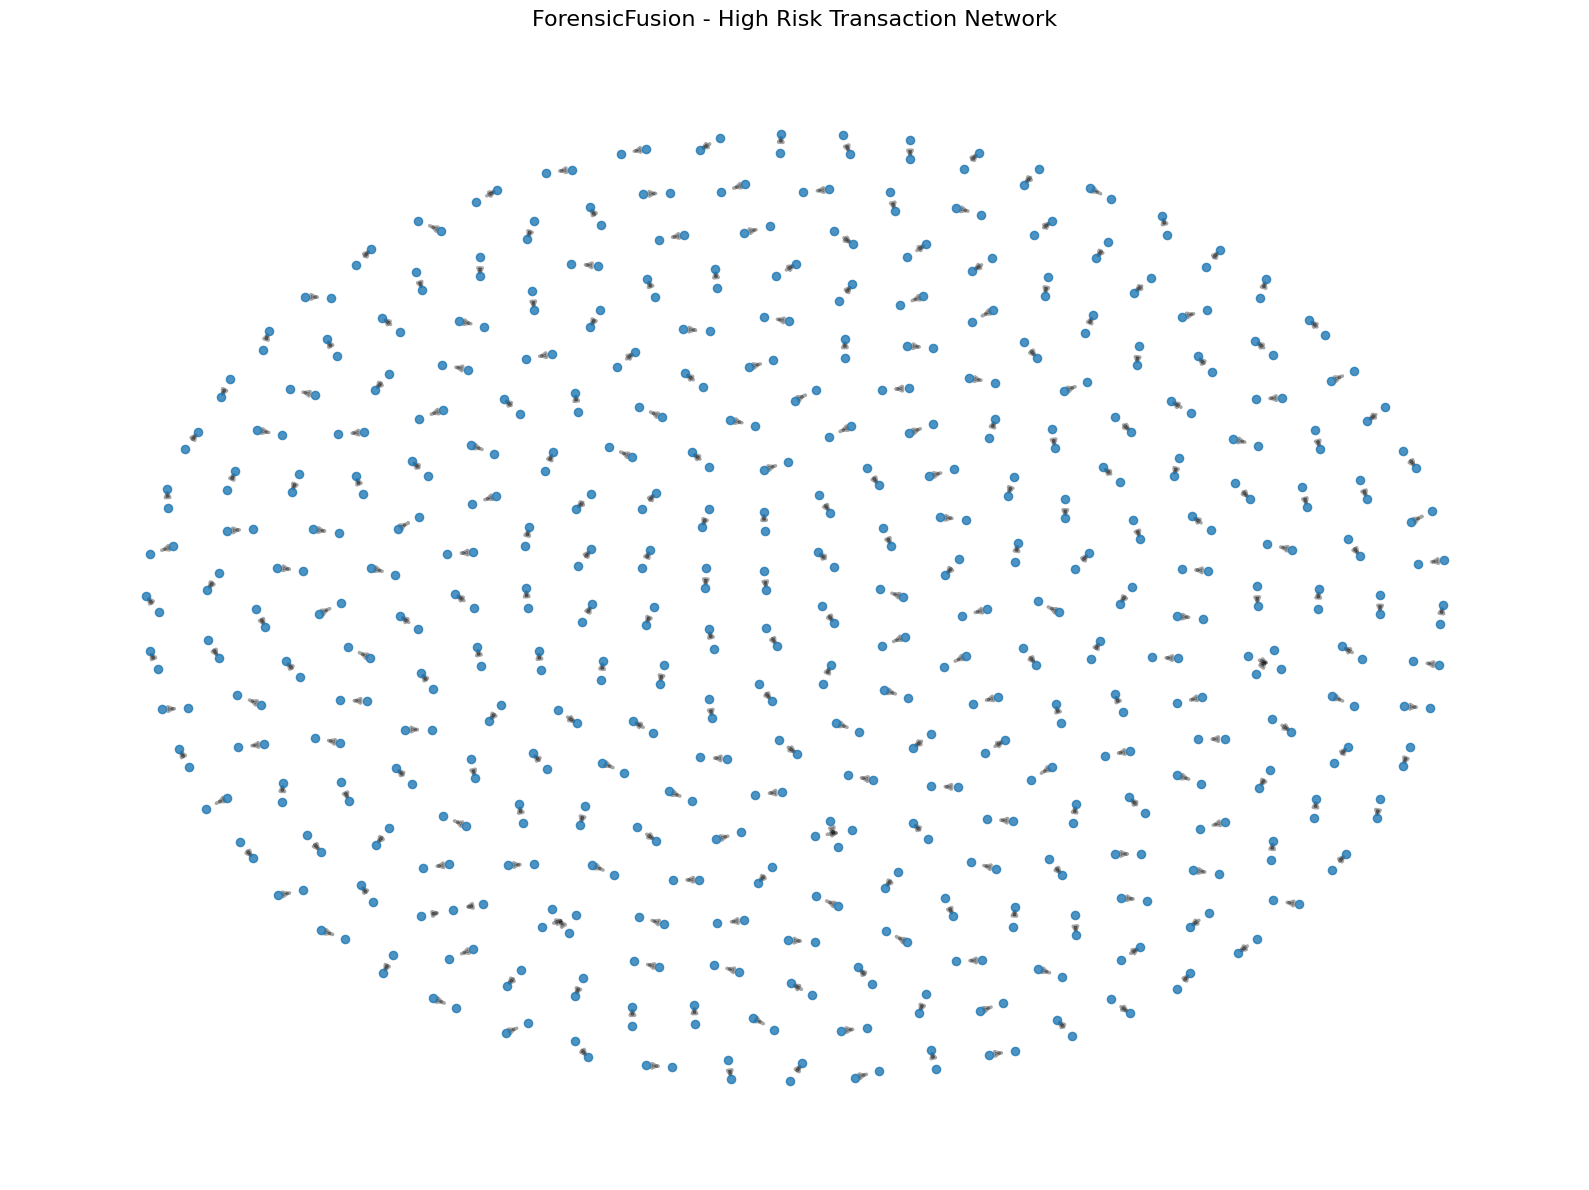

Saved: /content/ForensicFusion_Member3_suspicious_network.png


In [ ]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.5
)

edge_weights = [
    G[u][v]["weight"] * 3
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=35,
    alpha=0.8
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_weights,
    alpha=0.35,
    arrows=True,
    arrowsize=8
)

plt.title(
    "ForensicFusion - High Risk Transaction Network",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

NETWORK_PLOT = (
    "/content/ForensicFusion_Member3_suspicious_network.png"
)

plt.savefig(
    NETWORK_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", NETWORK_PLOT)

Fusion score distribution

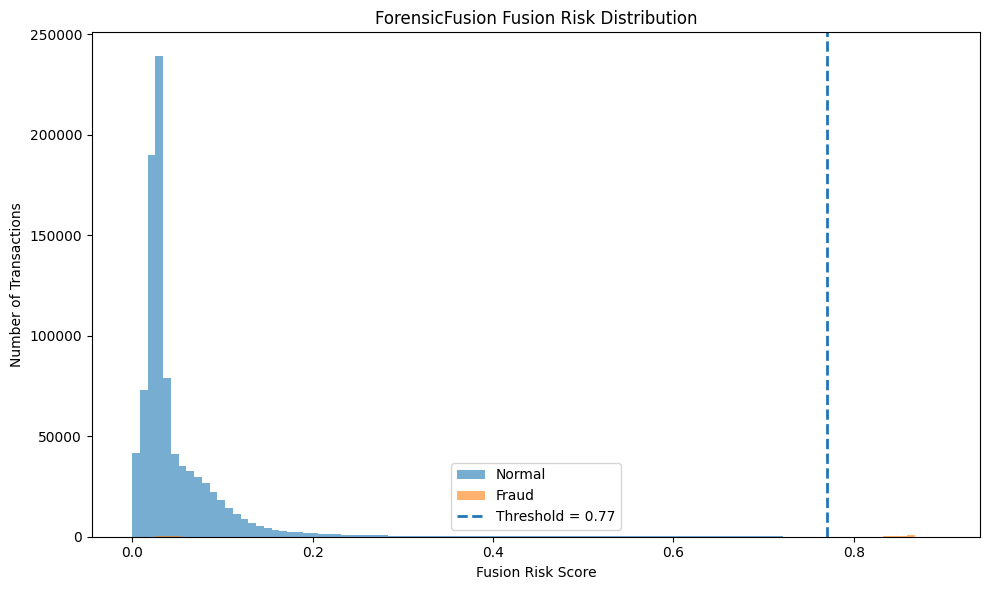

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    network_df.loc[
        network_df["fraud_label"] == 0,
        "fusion_score"
    ],
    bins=100,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    network_df.loc[
        network_df["fraud_label"] == 1,
        "fusion_score"
    ],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.axvline(
    FUSION_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {FUSION_THRESHOLD}"
)

plt.xlabel("Fusion Risk Score")
plt.ylabel("Number of Transactions")
plt.title("ForensicFusion Fusion Risk Distribution")
plt.legend()

plt.tight_layout()

FUSION_DIST_PLOT = (
    "/content/ForensicFusion_Member3_fusion_distribution.png"
)

plt.savefig(
    FUSION_DIST_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
XAI_FEATURES = [
    "member2_probability",
    "network_risk",
    "source_activity_risk",
    "destination_activity_risk",
    "source_mean_risk_norm",
    "destination_mean_risk_norm",
    "source_suspicious_norm",
    "destination_suspicious_norm"
]

XAI_NAMES = [
    "Member2_Fraud_Probability",
    "Network_Risk",
    "Source_Activity_Risk",
    "Destination_Activity_Risk",
    "Source_Mean_Risk",
    "Destination_Mean_Risk",
    "Source_Suspicious_Risk",
    "Destination_Suspicious_Risk"
]

X = network_df[XAI_FEATURES].astype(float).copy()

print("XAI shape:", X.shape)

display(X.head())

XAI shape: (918617, 8)


,member2_probability,network_risk,source_activity_risk,destination_activity_risk,source_mean_risk_norm,destination_mean_risk_norm,source_suspicious_norm,destination_suspicious_norm
0,1.0,0.467509,0.0,0.250,1.0,0.337545,1.0,0.5
1,1.0,0.550000,0.0,0.000,1.0,1.000000,1.0,0.5
2,1.0,0.550000,0.0,0.000,1.0,1.000000,1.0,0.5
3,1.0,0.477179,0.0,0.125,1.0,0.510894,1.0,0.5
4,1.0,0.478600,0.0,0.125,1.0,0.518000,1.0,0.5


Define the fusion model for SHAP

In [ ]:
def fusion_model(X_array):

    X_array = np.asarray(X_array)

    member2 = X_array[:, 0]
    network = X_array[:, 1]

    fusion = (
        MEMBER2_WEIGHT * member2 +
        NETWORK_WEIGHT * network
    )

    return fusion


test_prediction = fusion_model(
    X.iloc[:5].values
)

print("Test fusion outputs:")
print(test_prediction)

Test fusion outputs:
[0.84025269 0.865      0.865      0.84315363 0.84357997]


In [ ]:
# Sample data for SHAP
shap_n = min(
    SHAP_SAMPLE_SIZE,
    len(X)
)

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X),
    size=shap_n,
    replace=False
)

X_shap = X.iloc[sample_indices].copy()

print("SHAP samples:", len(X_shap))

# SHAP KernelExplainer
background_size = min(100, len(X_shap))

background = X_shap.sample(
    background_size,
    random_state=42
)

explainer = shap.KernelExplainer(
    fusion_model,
    background.values
)

shap_values = explainer.shap_values(
    X_shap.values,
    nsamples=100
)

shap_values = np.asarray(shap_values)

print("SHAP values shape:", shap_values.shape)

SHAP samples: 3000


  0%|          | 0/3000 [00:00<?, ?it/s]

SHAP values shape: (3000, 8)


Global SHAP feature importance

In [ ]:
mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance = pd.DataFrame({
    "feature": XAI_NAMES,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=False
)

print("=" * 80)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 80)

display(shap_importance)

GLOBAL SHAP FEATURE IMPORTANCE


,feature,mean_abs_shap
0,Member2_Fraud_Probability,0.040387
1,Network_Risk,0.009832
2,Source_Activity_Risk,0.000000
3,Destination_Activity_Risk,0.000000
4,Source_Mean_Risk,0.000000
5,Destination_Mean_Risk,0.000000
6,Source_Suspicious_Risk,0.000000
7,Destination_Suspicious_Risk,0.000000


SHAP summary plot

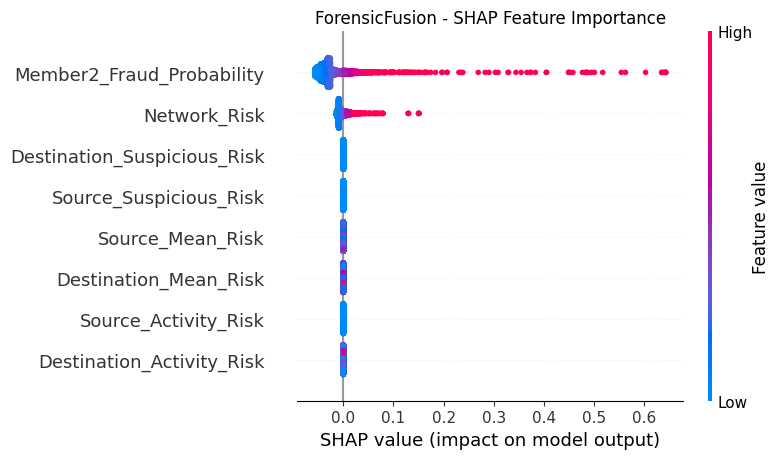

Saved: /content/ForensicFusion_Member3_SHAP_summary.png


In [ ]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_shap.values,
    feature_names=XAI_NAMES,
    show=False
)

plt.title(
    "ForensicFusion - SHAP Feature Importance"
)

plt.tight_layout()

SHAP_SUMMARY = (
    "/content/ForensicFusion_Member3_SHAP_summary.png"
)

plt.savefig(
    SHAP_SUMMARY,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", SHAP_SUMMARY)

SHAP bar plot

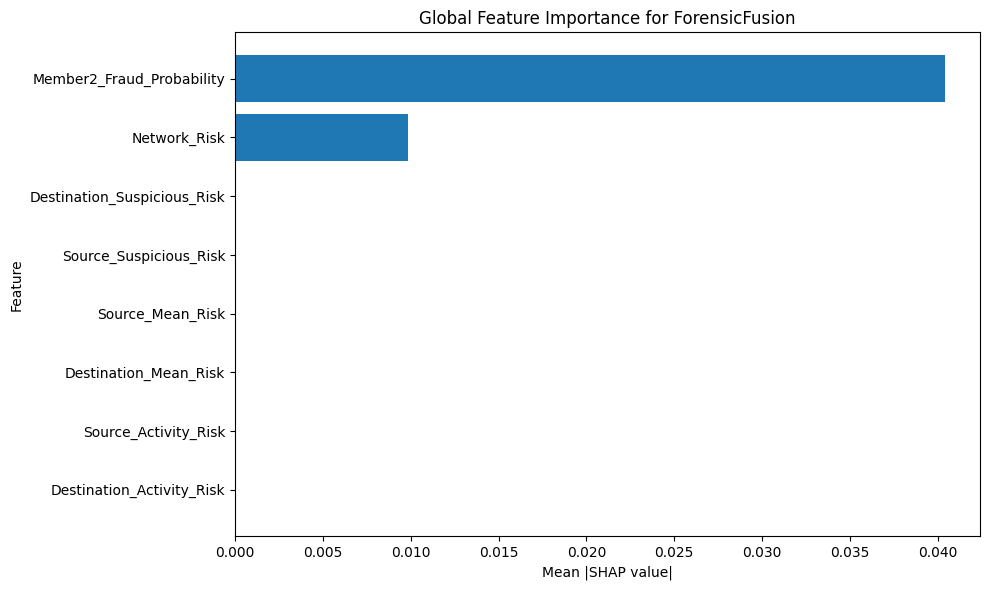

In [ ]:
plt.figure(figsize=(10, 6))

plot_df = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title(
    "Global Feature Importance for ForensicFusion"
)

plt.tight_layout()

SHAP_BAR = (
    "/content/ForensicFusion_Member3_SHAP_bar.png"
)

plt.savefig(
    SHAP_BAR,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Local SHAP explanation for top suspicious transactions

In [ ]:
top_xai = (
    network_df
    .sort_values(
        "fusion_score",
        ascending=False
    )
    .head(TOP_XAI_TRANSACTIONS)
    .copy()
)

X_local = top_xai[XAI_FEATURES].astype(float)

local_shap_values = explainer.shap_values(
    X_local.values,
    nsamples=100
)

local_shap_values = np.asarray(
    local_shap_values
)

print(
    "Generated local explanations for",
    len(top_xai),
    "transactions."
)

  0%|          | 0/20 [00:00<?, ?it/s]

Generated local explanations for 20 transactions.


Save local SHAP explanations

In [ ]:
local_rows = []

for i in range(len(top_xai)):

    row = top_xai.iloc[i]

    for j, feature in enumerate(XAI_NAMES):

        local_rows.append({
            "transaction_index": int(top_xai.index[i]),
            "source": row["source"],
            "destination": row["destination"],
            "fusion_score": row["fusion_score"],
            "fraud_label": row["fraud_label"],
            "feature": feature,
            "feature_value": X_local.iloc[i, j],
            "shap_value": local_shap_values[i, j],
            "absolute_shap": abs(local_shap_values[i, j])
        })

local_shap_df = pd.DataFrame(local_rows)

print("=" * 80)
print("LOCAL SHAP EXPLANATIONS")
print("=" * 80)

display(
    local_shap_df
    .sort_values(
        "absolute_shap",
        ascending=False
    )
    .head(30)
)

LOCAL SHAP EXPLANATIONS


,transaction_index,source,destination,fusion_score,fraud_label,feature,feature_value,shap_value,absolute_shap
8,393,8239045.0,8846226.0,0.873012,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
16,406,8236776.0,8835662.0,0.870378,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
104,309,8292950.0,8599609.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
64,437,8307532.0,8877050.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
144,333,8242809.0,8847912.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
32,367,8236544.0,8844868.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
128,304,8292051.0,7202441.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
88,344,8234842.0,8843806.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
40,474,8976514.0,2774145.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169
56,438,8195748.0,8823717.0,0.865000,1.0,Member2_Fraud_Probability,1.000000,0.643169,0.643169


Explain one suspicious transaction

In [ ]:
transaction_number = 0

row = top_xai.iloc[transaction_number]

print("=" * 80)
print("LOCAL FORENSICFUSION EXPLANATION")
print("=" * 80)

print("Source account      :", row["source"])
print("Destination account :", row["destination"])
print("Member 2 probability:", row["member2_probability"])
print("Network risk        :", row["network_risk"])
print("Fusion score        :", row["fusion_score"])
print("Actual label        :", row["fraud_label"])

explanation = pd.DataFrame({
    "Feature": XAI_NAMES,
    "Feature Value": X_local.iloc[
        transaction_number
    ].values,
    "SHAP Contribution": local_shap_values[
        transaction_number
    ]
})

explanation["Absolute Contribution"] = (
    explanation["SHAP Contribution"].abs()
)

explanation = explanation.sort_values(
    "Absolute Contribution",
    ascending=False
)

display(explanation)

LOCAL FORENSICFUSION EXPLANATION
Source account      : 8242306.0
Destination account : 8847675.0
Member 2 probability: 0.9999814
Network risk        : 0.6503046843600001
Fusion score        : 0.895078385308
Actual label        : 1.0


,Feature,Feature Value,SHAP Contribution,Absolute Contribution
0,Member2_Fraud_Probability,0.999981,0.643156,0.643156
1,Network_Risk,0.650305,0.181376,0.181376
2,Source_Activity_Risk,1.000000,0.000000,0.000000
3,Destination_Activity_Risk,0.000000,0.000000,0.000000
4,Source_Mean_Risk,0.501542,0.000000,0.000000
5,Destination_Mean_Risk,0.999981,0.000000,0.000000
6,Source_Suspicious_Risk,1.000000,0.000000,0.000000
7,Destination_Suspicious_Risk,0.500000,0.000000,0.000000


Create human-readable explanation

In [ ]:
top_contributors = (
    explanation
    .head(5)
    .copy()
)

print("=" * 80)
print("FORENSIC EXPLANATION")
print("=" * 80)

print(
    f"Transaction: {row['source']} -> {row['destination']}"
)

print(
    f"Final fusion risk: {row['fusion_score']:.4f}"
)

print("\nTop contributing factors:")

for _, r in top_contributors.iterrows():

    direction = (
        "increased"
        if r["SHAP Contribution"] > 0
        else "decreased"
    )

    print(
        f"• {r['Feature']} "
        f"{direction} the fusion risk "
        f"(SHAP={r['SHAP Contribution']:.4f})"
    )

FORENSIC EXPLANATION
Transaction: 8242306.0 -> 8847675.0
Final fusion risk: 0.8951

Top contributing factors:
• Member2_Fraud_Probability increased the fusion risk (SHAP=0.6432)
• Network_Risk increased the fusion risk (SHAP=0.1814)
• Source_Activity_Risk decreased the fusion risk (SHAP=0.0000)
• Destination_Activity_Risk decreased the fusion risk (SHAP=0.0000)
• Source_Mean_Risk decreased the fusion risk (SHAP=0.0000)


In [ ]:
FINAL_TRANSACTION_PATH = (
    "/content/ForensicFusion_Member3_final_transactions.csv"
)

network_df.to_csv(
    FINAL_TRANSACTION_PATH,
    index=False
)

print("Saved:")
print(FINAL_TRANSACTION_PATH)

Saved:
/content/ForensicFusion_Member3_final_transactions.csv


Save suspicious transactions

In [ ]:
SUSPICIOUS_TRANSACTION_PATH = (
    "/content/ForensicFusion_Member3_suspicious_transactions.csv"
)

suspicious_transactions.to_csv(
    SUSPICIOUS_TRANSACTION_PATH,
    index=False
)

print("Saved:")
print(SUSPICIOUS_TRANSACTION_PATH)

Save suspicious accounts

In [ ]:
SUSPICIOUS_ACCOUNT_PATH = (
    "/content/ForensicFusion_Member3_suspicious_accounts.csv"
)

suspicious_accounts.to_csv(
    SUSPICIOUS_ACCOUNT_PATH,
    index=False
)

print("Saved:")
print(SUSPICIOUS_ACCOUNT_PATH)

Saved:
/content/ForensicFusion_Member3_suspicious_accounts.csv


SHAP results

In [ ]:
SHAP_IMPORTANCE_PATH = (
    "/content/ForensicFusion_Member3_SHAP_importance.csv"
)

LOCAL_SHAP_PATH = (
    "/content/ForensicFusion_Member3_local_SHAP.csv"
)

shap_importance.to_csv(
    SHAP_IMPORTANCE_PATH,
    index=False
)

local_shap_df.to_csv(
    LOCAL_SHAP_PATH,
    index=False
)

print("SHAP files saved:")
print(SHAP_IMPORTANCE_PATH)
print(LOCAL_SHAP_PATH)

SHAP files saved:
/content/ForensicFusion_Member3_SHAP_importance.csv
/content/ForensicFusion_Member3_local_SHAP.csv


Final report

In [ ]:
import os

# Re-define label_col for consistent execution
label_col = 'fraud_label'

print("\n")
print("=" * 80)
print("FORENSICFUSION - MEMBER 3 FINAL REPORT")
print("=" * 80)

print("\n[INPUT FROM MEMBER 2]")
print("-" * 80)

print(
    "Transactions analyzed :",
    len(network_df)
)

print(
    "Member 2 threshold    :",
    MEMBER2_THRESHOLD
)

print(
    "Member 2 suspicious transactions :",
    int(network_df["member2_suspicious"].sum())
)

print("\n[NETWORK]")
print("-" * 80)

print(
    "Unique accounts :",
    len(unique_accounts)
)

print(
    "Network edges   :",
    len(network_df)
)

print("\n[FUSION]")
print("-" * 80)

print(
    "Member 2 weight       :",
    MEMBER2_WEIGHT
)

print(
    "Network weight        :",
    NETWORK_WEIGHT
)

print(
    "Fusion threshold      :",
    FUSION_THRESHOLD
)

print(
    "Final suspicious transactions :",
    int(network_df["final_suspicious"].sum())
)

print(
    "Final suspicious accounts     :",
    len(suspicious_accounts)
)

if label_col is not None:

    print("\n[FINAL FUSION PERFORMANCE]")
    print("-" * 80)

    # Ensure performance metrics are available from previous cells
    # roc_auc, pr_auc, accuracy, precision, recall, f1 are assumed defined

    print(
        f"ROC-AUC   : {roc_auc:.6f}"
    )

    print(
        f"PR-AUC    : {pr_auc:.6f}"
    )

    print(
        f"Accuracy  : {accuracy:.6f}"
    )

    print(
        f"Precision : {precision:.6f}"
    )

    print(
        f"Recall    : {recall:.6f}"
    )

    print(
        f"F1-score  : {f1:.6f}"
    )

print("\n[EXPLAINABLE AI]")
print("-" * 80)

# Ensure SHAP related variables are available from previous cells
# X_shap, XAI_FEATURES, shap_importance are assumed defined

print(
    "SHAP samples:",
    len(X_shap)
)

print(
    "XAI features:",
    len(XAI_FEATURES)
)

print(
    "Top SHAP feature:",
    shap_importance.iloc[0]["feature"]
)

print(
    "Top SHAP importance:",
    shap_importance.iloc[0]["mean_abs_shap"]
)

print("\n[OUTPUT FILES]")
print("-" * 80)

# Define paths explicitly if they were not passed into current session or kernel restarted.
FINAL_TRANSACTION_PATH = "/content/ForensicFusion_Member3_final_transactions.csv"
SUSPICIOUS_TRANSACTION_PATH = "/content/ForensicFusion_Member3_suspicious_transactions.csv"
SUSPICIOUS_ACCOUNT_PATH = "/content/ForensicFusion_Member3_suspicious_accounts.csv"
SHAP_IMPORTANCE_PATH = "/content/ForensicFusion_Member3_SHAP_importance.csv"
LOCAL_SHAP_PATH = "/content/ForensicFusion_Member3_local_SHAP.csv"
NETWORK_PLOT = "/content/ForensicFusion_Member3_suspicious_network.png"
FUSION_DIST_PLOT = "/content/ForensicFusion_Member3_fusion_distribution.png"
SHAP_SUMMARY = "/content/ForensicFusion_Member3_SHAP_summary.png"
SHAP_BAR = "/content/ForensicFusion_Member3_SHAP_bar.png"


print(FINAL_TRANSACTION_PATH)
print(SUSPICIOUS_TRANSACTION_PATH)
print(SUSPICIOUS_ACCOUNT_PATH)
print(SHAP_IMPORTANCE_PATH)
print(LOCAL_SHAP_PATH)
print(NETWORK_PLOT)
print(FUSION_DIST_PLOT)
print(SHAP_SUMMARY)
print(SHAP_BAR)

print("\n")
print("=" * 80)
print("MEMBER 3 COMPLETE")
print("=" * 80)



FORENSICFUSION - MEMBER 3 FINAL REPORT

[INPUT FROM MEMBER 2]
--------------------------------------------------------------------------------
Transactions analyzed : 918617
Member 2 threshold    : 0.98
Member 2 suspicious transactions : 1666

[NETWORK]
--------------------------------------------------------------------------------
Unique accounts : 1608847
Network edges   : 918617

[FUSION]
--------------------------------------------------------------------------------
Member 2 weight       : 0.7
Network weight        : 0.3
Fusion threshold      : 0.77
Final suspicious transactions : 2001
Final suspicious accounts     : 3999

[FINAL FUSION PERFORMANCE]
--------------------------------------------------------------------------------
ROC-AUC   : 0.907182
PR-AUC    : 0.558865
Accuracy  : 0.997397
Precision : 0.903548
Recall    : 0.451323
F1-score  : 0.601964

[EXPLAINABLE AI]
--------------------------------------------------------------------------------
SHAP samples: 3000
XAI featu